# Livrable 2 : débruitage d'images RGB par autoencodeur convolutif
**Auteur :** Nizar
Projet Leyenda. L'objectif est de rendre les photographies plus exploitables par les algorithmes de Machine Learning en retirant le bruit qu'elles contiennent. On s'appuie sur des autoencodeurs à convolution (architecture UNet), entraînés sur des images RGB, et on compare deux variantes : une avec augmentation de données et une sans.

## Résumé

**Le problème.** Le dataset contient 148 photos RGB au format JPEG, de tailles différentes (de 333 à 640 pixels de large). Il n'existe pas de version propre de ces photos. Il faut donc construire nous mêmes les paires (image bruitée, image cible) qui servent à entraîner le modèle, puis vérifier que le modèle retire le bruit sans effacer les détails utiles au livrable 3 (génération de légendes).

**Ce qu'on a fait.**

1. **Contrôle des données** : formats, canaux, doublons, images quasi vides, niveau de bruit déjà présent (section 3).
2. **Prétraitement sans déformation** : le plus petit côté est ramené à 256 pixels en gardant le format de l'image (section 4).
3. **Découpage par image avant tout** : 70 % entraînement, 15 % validation, 15 % test, pour qu'aucune photo du test n'ait été vue pendant l'entraînement (section 5).
4. **Paires bruitée et cible** : on ajoute à chaque patch un bruit gaussien dont le niveau σ est tiré entre 0 et 0,08, et on en tire un nouveau à chaque époque (sections 7 et 8).
5. **Modèle** : un UNet résiduel entièrement convolutif d'environ 467 000 paramètres. Il estime le bruit puis le soustrait de l'entrée (section 10).
6. **Deux variantes** identiques sauf sur un point : avec ou sans augmentation (rotations et symétries). Un **modèle de référence**, un autoencodeur convolutif simple sans skip connections, est entraîné dans les mêmes conditions pour mesurer ce qu'apporte l'architecture UNet (section 12 bis). Une étude complémentaire refait la comparaison avec très peu d'images d'entraînement, pour voir dans quel cas l'augmentation devient utile (section 15 bis).
7. **Évaluation honnête** : PSNR et SSIM sur le test à quatre niveaux de bruit, comparaison avec trois filtres classiques réglés sur la validation, test statistique image par image, et essai sur les photos réelles sans bruit ajouté (sections 14 à 16).

**Ce qu'il faut retenir.**

* Le UNet bat nettement les filtres classiques (gaussien, médian, Non Local Means) à tous les niveaux de bruit, en PSNR comme en SSIM, et il reste rapide.
* Avec toutes les images, l'augmentation n'apporte aucun gain : elle fait même très légèrement moins bien (−0,03 dB), un écart mesurable mais sans importance pratique. C'est logique : aucun signe de surapprentissage n'est observé, et le bruit tiré à nouveau à chaque époque apporte déjà beaucoup de variété. Les deux modèles donnent donc des courbes presque identiques ; les figures les tracent côte à côte avec l'écart entre eux, pour qu'on puisse les distinguer.
* L'architecture compte : entraîné exactement de la même façon, un autoencodeur convolutif simple, sans skip connections, fait 6,83 dB de moins que le UNet en moyenne et floute les détails ; à faible bruit, il fait même moins bien que l'image bruitée (section 12 bis).
* Les courbes d'apprentissage des UNet ne montrent aucun signe de surapprentissage. Celles du modèle sans augmentation sont parfaitement lisses ; celles du modèle avec augmentation ont une seule remontée, de 7 % à l'époque 40, rattrapée en cinq époques.
* Sur les photos réelles, le bruit d'origine est très faible à la résolution de travail. Le UNet garde alors la photo presque intacte, sans la flouter, alors que le filtre gaussien perd de la netteté. Une vérification avec de vraies références propres (section 16.5) le confirme : un bruit réaliste du type de nos photos laisse l'image à 44 dB de sa version propre, il n'y a presque rien à retirer, et le UNet est la seule méthode testée qui ne dégrade pas l'image.

Les chiffres de l'exécution remise sont résumés dans le tableau juste en dessous. Chaque bloc de code est précédé d'une courte explication, et chaque graphe ou tableau est suivi de sa lecture. Chaque choix est justifié dans la section 9 (pourquoi cette méthode, comment, et pourquoi pas les autres).

> À exécuter sur Colab avec un GPU (Exécution, Modifier le type d'exécution, GPU T4), puis Exécution, Tout exécuter. Compter environ trente minutes (31 min lors de notre exécution) : tous les modèles sont réentraînés, pour que le journal des époques soit visible.

### Chiffres clés de l'exécution remise

| Indicateur | Valeur |
|:--|:--|
| Modèle retenu | UNet sans augmentation |
| PSNR moyen sur le test, 4 niveaux de bruit | **35,92 dB** (image bruitée : 27,27 dB) |
| Meilleur filtre classique | Non Local Means (h = 5) : 30,86 dB, soit **+5,07 dB** pour le UNet |
| SSIM moyen sur le test | **0,934** (meilleur filtre : 0,821, image bruitée : 0,617) |
| Gain du UNet selon le bruit | σ = 0,02 : +6,1 dB ; σ = 0,04 : +8,5 dB ; σ = 0,08 : +10,3 dB |
| UNet contre autoencodeur simple (sans skip) | **+6,83 dB** par image, p = 2,4 × 10⁻⁷, UNet meilleur sur les 23 images (29,11 dB pour l'autoencodeur simple) |
| Augmentation, toutes les images | −0,033 dB, p = 0,002 : très légèrement moins bien, sans importance pratique (moins de 0,1 dB) |
| Augmentation, 12 images | −0,041 dB, p = 0,04 : même conclusion |
| Vérité terrain (CBSD68, référence propre) | bruit gaussien σ = 0,04 : 28,11 → **35,87 dB** ; bruit réaliste : 44,23 → 44,21 dB, ni gain ni perte (p = 0,86), alors que le filtre gaussien perd 11,8 dB |
| Photos réelles : netteté des contours conservée | UNet 100 %, autoencodeur simple 91 %, filtre gaussien 82 % |
| Stabilité des courbes (UNet) | sans augmentation : remontée maximale 0,01 % ; avec augmentation : une remontée de 7,3 % (époque 40), rattrapée en 5 époques |
| Temps total d'exécution du notebook | 31,1 min, tous les modèles réentraînés |

Ces chiffres viennent des tableaux 1 à 5 et de la section 15 bis. Les commentaires placés sous chaque graphe et chaque tableau décrivent cette même exécution ; une nouvelle exécution sur GPU peut faire varier légèrement les dernières décimales (voir les limites).

## Sommaire
1. [Configuration et mesure du temps d'exécution](#s1)
2. [Chargement du dataset](#s2)
3. [Visualisation et validation des données](#s3)
4. [Prétraitement : résolution de travail, format conservé](#s4)
5. [Découpage train, validation et test](#s5)
6. [Extraction des patchs](#s6)
7. [Création des paires bruitée et cible](#s7)
8. [Augmentation de données et bruit tiré à chaque époque](#s8)
9. [Pourquoi ce choix de méthode ? (why, how, why not)](#s9)
10. [Architecture : autoencodeur convolutif UNet](#s10)
11. [Modèle A : entraînement avec augmentation](#s11)
12. [Modèle B : entraînement sans augmentation](#s12)
12 bis. [Modèle de référence : autoencodeur convolutif simple](#s12b)
13. [Courbes séparées : train, validation, test](#s13)
14. [Évaluation PSNR et SSIM, comparaison aux filtres classiques réglés sur la validation](#s14)
15. [Tableaux comparatifs et test statistique par image](#s15)
15 bis. [Étude complémentaire : l'augmentation quand les données manquent](#s15b)
16. [Étude de cas](#s16)
17. [Temps d'exécution de chaque cellule](#s17)
18. [Conclusion](#s18)
19. [Test sur une photo au choix](#s19)

<a id="s1"></a>
## 1. Configuration et mesure du temps d'exécution

On installe d'abord un petit chronomètre automatique. Après chaque bloc de code exécuté, il affiche la durée d'exécution et l'enregistre dans un journal. À la fin du notebook (section 17), on récupère ce journal sous forme de tableau. On n'utilise pas d'extension externe : uniquement les événements d'IPython, donc rien à installer.

On installe un chronomètre automatique. Avant chaque bloc de code exécuté, une fonction note l'heure ; après, une autre calcule la durée, l'affiche (⏱) et l'ajoute au journal `JOURNAL_TEMPS`. Si on relance ce code, les anciennes versions du chronomètre sont retirées, pour ne pas compter deux fois. Le journal est affiché en section 17.

In [2]:
# Chronometre automatique de chaque cellule
import time
from IPython import get_ipython

JOURNAL_TEMPS = []          # liste de dictionnaires (numero, debut du code, duree)
CHRONO = {"t0": None, "code": ""}

def avant_cellule(info=None):
    CHRONO["t0"] = time.perf_counter()
    CHRONO["code"] = (info.raw_cell if info is not None else "").strip()

def apres_cellule(result=None):
    if CHRONO["t0"] is None:
        return
    duree = time.perf_counter() - CHRONO["t0"]
    premiere_ligne = next((l for l in CHRONO["code"].splitlines()
                           if l.strip() and not set(l.strip()) <= set("#=")), "")
    JOURNAL_TEMPS.append({"cellule": len(JOURNAL_TEMPS) + 1,
                          "debut du code": premiere_ligne[:70],
                          "duree (s)": round(duree, 2)})
    print(f"\n⏱ Temps d'execution de la cellule : {duree:.2f} s")

ip = get_ipython()
# On retire d'anciennes versions si la cellule est relancee
for evt, fn in (("pre_run_cell", avant_cellule), ("post_run_cell", apres_cellule)):
    for f in list(ip.events.callbacks[evt]):
        if getattr(f, "__name__", "") == fn.__name__:
            ip.events.unregister(evt, f)
    ip.events.register(evt, fn)
print("Chronometre active.")

Chronometre active.


On monte le Google Drive dans Colab. Les modèles entraînés et les figures y sont enregistrés, ce qui évite de tout réentraîner à chaque session.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive

⏱ Temps d'execution de la cellule : 24.44 s


On importe `Path`, l'outil Python qui manipule les chemins de fichiers.

In [4]:
from pathlib import Path, PurePosixPath


⏱ Temps d'execution de la cellule : 0.00 s


On définit les dossiers du projet, cherche l'archive du dataset sur le Drive et, si elle n'y est pas, la télécharge depuis son lien de partage. L'archive est décompressée sur le disque local de Colab (plus rapide que le Drive), puis toutes les images sont copiées dans un seul dossier. Les fichiers cachés et le dossier `__MACOSX` ajouté par macOS sont ignorés ; deux images de même nom sont renommées. Un `assert` arrête le notebook si aucune image n'est trouvée.

In [5]:
# Dossiers du projet
import zipfile, shutil

RACINE = Path("/content/drive/MyDrive/Project1_Livrable2")
DOSSIERTRAVAIL = RACINE / "resultats"
DOSSIERTRAVAIL.mkdir(parents=True, exist_ok=True)

# Le dataset est fourni en archive zip (Dataset Livrable 2.zip).
# On la decompresse sur le disque local de Colab, plus rapide que le Drive,
# puis on rassemble toutes les images dans un seul dossier a plat.
NOM_ZIP = "Dataset Livrable 2.zip"
ID_ZIP = "1FXVD_BC7U794zSq2uFJNs9Ju3mQf_r62"
ZIP_LOCAL = Path("/content") / NOM_ZIP
DOSSIEREXTRAIT = Path("/content/dataset_extrait")
DOSSIERSOURCE = Path("/content/dataset")
DOSSIERSELECTION = DOSSIERSOURCE / "selection"
EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def trouver_zip():
    """Cherche le zip dans les emplacements habituels du Drive, sinon le telecharge."""
    for d in [RACINE, RACINE / "Dataset", Path("/content/drive/MyDrive"), Path("/content")]:
        if (d / NOM_ZIP).exists():
            return d / NOM_ZIP
    print("Zip introuvable sur le Drive, telechargement depuis le lien de partage...")
    import gdown
    gdown.download(id=ID_ZIP, output=str(ZIP_LOCAL), quiet=False)
    return ZIP_LOCAL

if not DOSSIERSOURCE.exists() or not any(DOSSIERSOURCE.iterdir()):
    chemin_zip = trouver_zip()
    print(f"Archive utilisee : {chemin_zip}")
    if DOSSIEREXTRAIT.exists():
        shutil.rmtree(DOSSIEREXTRAIT)
    with zipfile.ZipFile(chemin_zip) as z:
        z.extractall(DOSSIEREXTRAIT)

    # Mise a plat : les images peuvent etre dans des sous dossiers.
    # On ignore les fichiers caches et le dossier __MACOSX ajoute par macOS.
    DOSSIERSOURCE.mkdir(parents=True, exist_ok=True)
    for f in DOSSIEREXTRAIT.rglob("*"):
        if (f.is_file() and f.suffix.lower() in EXTS
                and not f.name.startswith(".") and "__MACOSX" not in f.parts):
            cible = DOSSIERSOURCE / f.name
            if cible.exists():   # deux images de meme nom dans deux sous dossiers
                cible = DOSSIERSOURCE / f"{f.parent.name}_{f.name}"
            shutil.copy2(f, cible)

nb_images = sum(1 for f in DOSSIERSOURCE.iterdir() if f.suffix.lower() in EXTS)
print(f"Dossier des images : {DOSSIERSOURCE} ({nb_images} images)")
assert nb_images > 0, "Aucune image trouvee apres extraction, verifier le contenu du zip."

Zip introuvable sur le Drive, telechargement depuis le lien de partage...


Downloading...
From: https://drive.google.com/uc?id=1FXVD_BC7U794zSq2uFJNs9Ju3mQf_r62
To: /content/Dataset Livrable 2.zip
100%|██████████| 18.7M/18.7M [00:00<00:00, 55.5MB/s]


Archive utilisee : /content/Dataset Livrable 2.zip
Dossier des images : /content/dataset (148 images)

⏱ Temps d'execution de la cellule : 3.05 s


L'archive n'était pas encore sur le Drive : le notebook l'a donc téléchargée depuis son lien de partage (18,7 Mo), puis décompressée sur le disque de Colab. On retrouve bien les 148 images annoncées, ce qui confirme que l'extraction et la mise à plat des dossiers se sont bien passées.

<a id="s2"></a>
## 2. Chargement du dataset

On liste les fichiers image du dossier, puis on ouvre chacun avec Pillow pour relever son format, sa taille et son mode de couleur. Le sujet précise que le workflow est en RGB, on vérifie donc que toutes les images ont bien trois canaux.

On liste les fichiers image du dossier (jpg, jpeg, png, bmp), triés par nom, et fixe le style commun de toutes les figures du notebook.

In [6]:
# ============================================================
# ETAPE 1 : CHARGEMENT DU DATASET
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import cv2
import os

# 1.1 Lister toutes les images du dossier source
extensions_valides = {".jpg", ".jpeg", ".png", ".bmp"}
chemins_images = sorted([
    p for p in DOSSIERSOURCE.iterdir()
    if p.suffix.lower() in extensions_valides
])

print(f"Nombre d'images trouvées : {len(chemins_images)}")
print(f"Exemples : {[p.name for p in chemins_images[:5]]}")

# Style commun des figures : légendes hors des courbes, grille légère, pas de cadre inutile
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "legend.fontsize": 9, "legend.frameon": False,
})


Nombre d'images trouvées : 148
Exemples : ['noisy_001.jpg', 'noisy_002.jpg', 'noisy_003.jpg', 'noisy_004.jpg', 'noisy_005.jpg']

⏱ Temps d'execution de la cellule : 0.05 s


Les 148 images sont bien trouvées. Leur nom, de la forme `noisy_001.jpg`, n'est pas anodin : il indique que les photos fournies sont déjà bruitées et qu'on ne dispose d'aucune version propre. C'est cette contrainte qui oriente toute la méthode : on ne pourra pas apprendre à passer d'une photo bruitée à une photo propre, il faudra fabriquer nous mêmes des paires d'entraînement (section 7).

On ouvre chaque fichier avec Pillow et relève son format, sa taille et son mode de couleur. Un fichier illisible serait signalé sans arrêter le notebook.

In [7]:
# 1.2 Vérifier la cohérence des fichiers (formats, tailles, canaux)
infos = []
for p in chemins_images:
    try:
        img = Image.open(p)
        infos.append({
            "nom": p.name,
            "format": img.format,
            "taille": img.size,          # (largeur, hauteur)
            "mode": img.mode,            # RGB, L, RGBA...
        })
    except Exception as e:
        print(f"⚠️ Erreur sur {p.name} : {e}")

print(f"\nFichiers lus avec succès : {len(infos)}")
print("\nAperçu des 5 premières entrées :")
for info in infos[:5]:
    print(info)


Fichiers lus avec succès : 148

Aperçu des 5 premières entrées :
{'nom': 'noisy_001.jpg', 'format': 'JPEG', 'taille': (640, 426), 'mode': 'RGB'}
{'nom': 'noisy_002.jpg', 'format': 'JPEG', 'taille': (640, 482), 'mode': 'RGB'}
{'nom': 'noisy_003.jpg', 'format': 'JPEG', 'taille': (480, 640), 'mode': 'RGB'}
{'nom': 'noisy_004.jpg', 'format': 'JPEG', 'taille': (518, 600), 'mode': 'RGB'}
{'nom': 'noisy_005.jpg', 'format': 'JPEG', 'taille': (640, 480), 'mode': 'RGB'}

⏱ Temps d'execution de la cellule : 0.07 s


Les 148 fichiers s'ouvrent sans erreur : aucun n'est corrompu. Les premières entrées montrent déjà deux caractéristiques du dataset que l'on retrouvera partout : toutes les images sont des JPEG en RGB, mais elles n'ont pas la même taille, et certaines sont en hauteur (480 × 640) alors que d'autres sont en largeur (640 × 426).

On calcule les tailles minimale, maximale et moyenne, liste les modes de couleur, et vérifie que toutes les images sont en RGB.

In [8]:
# 1.3 Statistiques globales sur le dataset
tailles = [i["taille"] for i in infos]
modes   = [i["mode"]   for i in infos]

largeurs = [t[0] for t in tailles]
hauteurs = [t[1] for t in tailles]

print("=== STATISTIQUES GLOBALES ===")
print(f"Nombre total d'images    : {len(infos)}")
print(f"Largeur  min / max / moy : {min(largeurs)} / {max(largeurs)} / {np.mean(largeurs):.1f}")
print(f"Hauteur  min / max / moy : {min(hauteurs)} / {max(hauteurs)} / {np.mean(hauteurs):.1f}")
print(f"Modes de couleur uniques : {set(modes)}")

# Vérifier que toutes les images sont bien en RGB
modes_non_rgb = [i for i in infos if i["mode"] != "RGB"]
if modes_non_rgb:
    print(f"⚠️ {len(modes_non_rgb)} image(s) non RGB détectée(s) :")
    for i in modes_non_rgb[:10]:
        print("  ", i["nom"], ":", i["mode"])
else:
    print("✅ Toutes les images sont en RGB (3 canaux), conforme au workflow du projet.")

=== STATISTIQUES GLOBALES ===
Nombre total d'images    : 148
Largeur  min / max / moy : 333 / 640 / 583.9
Hauteur  min / max / moy : 233 / 640 / 478.8
Modes de couleur uniques : {'RGB'}
✅ Toutes les images sont en RGB (3 canaux), conforme au workflow du projet.

⏱ Temps d'execution de la cellule : 0.00 s


Les largeurs vont de 333 à 640 pixels (583,9 en moyenne) et les hauteurs de 233 à 640 pixels (478,8 en moyenne). Les tailles sont donc trop variées pour être données telles quelles à un réseau qui travaille par lots : il faudra les ramener à une résolution commune, ce que fait la section 4. En revanche, toutes les images sont en RGB, conformément au cahier des charges : aucune conversion de couleur n'est nécessaire.

<a id="s3"></a>
## 3. Visualisation et validation des données

Avant de toucher au modèle, on regarde les données. Trois questions guident cette partie :

* à quoi ressemblent les images et leur bruit ?
* les tailles et les couleurs sont elles homogènes ?
* y a t il des fichiers corrompus, des doublons ou des images quasi vides qui fausseraient l'entraînement ?

On tire 12 images au hasard (graine 42, donc toujours les mêmes) et les affiche à leur taille d'origine, avec leur nom et leurs dimensions.

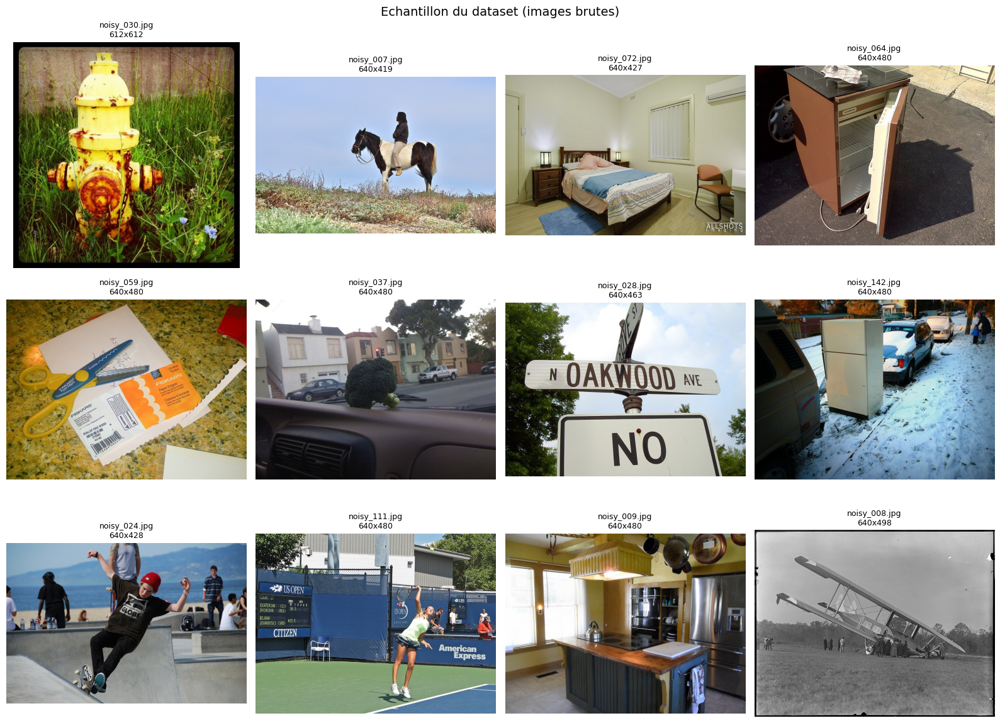


⏱ Temps d'execution de la cellule : 4.29 s


In [9]:
# 3.1 Galerie d'images brutes (taille d'origine)
import random
random.seed(42)
echantillon = random.sample(chemins_images, min(12, len(chemins_images)))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, p in zip(axes.ravel(), echantillon):
    img = Image.open(p).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{p.name}\n{img.size[0]}x{img.size[1]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Echantillon du dataset (images brutes)", fontsize=14)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "01_galerie.png", dpi=100, bbox_inches="tight")
plt.show()

La galerie montre des scènes très variées : extérieurs, intérieurs, objets du quotidien, sport, et même des photos anciennes en noir et blanc, comme l'avion en bas à droite. Deux images ont un cadre noir (la borne à incendie et l'avion), ce qui produira des pixels très sombres dans les statistiques de couleur. On remarque surtout qu'à cette taille, le bruit des photos ne se voit pas à l'œil : il est faible, ce que la mesure de la section 3.4 va confirmer.

On trace les histogrammes des largeurs, des hauteurs et du rapport largeur / hauteur, puis affiche un tableau de statistiques et le nombre d'images par format de fichier.

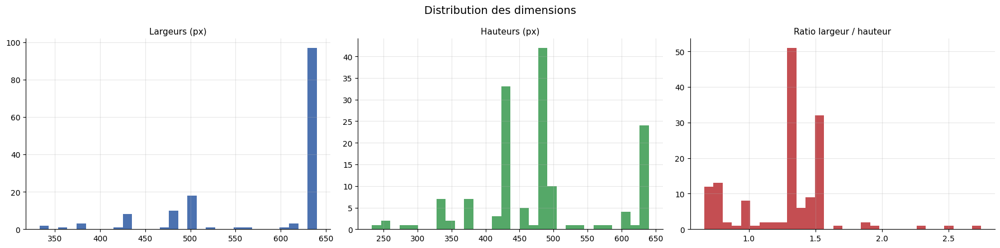

,largeur,hauteur,ratio
count,148.00,148.00,148.00
mean,583.87,478.79,1.28
std,86.16,95.23,0.35
min,333.00,233.00,0.66
25%,500.00,427.00,1.08
50%,640.00,480.00,1.33
75%,640.00,500.00,1.50
max,640.00,640.00,2.75


,nombre d'images
format,
JPEG,148



⏱ Temps d'execution de la cellule : 1.67 s


In [10]:
# 3.2 Distribution des tailles et des ratios
import pandas as pd
df_infos = pd.DataFrame(infos)
df_infos["largeur"] = df_infos["taille"].apply(lambda t: t[0])
df_infos["hauteur"] = df_infos["taille"].apply(lambda t: t[1])
df_infos["ratio"]   = df_infos["largeur"] / df_infos["hauteur"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(df_infos["largeur"], bins=30, color="#4C72B0"); axes[0].set_title("Largeurs (px)")
axes[1].hist(df_infos["hauteur"], bins=30, color="#55A868"); axes[1].set_title("Hauteurs (px)")
axes[2].hist(df_infos["ratio"],   bins=30, color="#C44E52"); axes[2].set_title("Ratio largeur / hauteur")
for ax in axes: ax.grid(alpha=0.3)
plt.suptitle("Distribution des dimensions", fontsize=14)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "02_dimensions.png", dpi=100, bbox_inches="tight")
plt.show()

display(df_infos[["largeur", "hauteur", "ratio"]].describe().round(2))
display(df_infos["format"].value_counts().to_frame("nombre d'images"))

La largeur la plus fréquente est 640 pixels, pour près de 100 images sur 148. Le rapport largeur sur hauteur va de 0,66, pour les images en hauteur, à 2,75, pour un format panoramique, avec deux pics nets à 1,33 (le format 4 : 3 des appareils photo) et à 1,5. Les 148 fichiers sont tous des JPEG. Ces chiffres justifient un choix important du prétraitement : si l'on ramenait toutes les images à un carré, certaines seraient étirées jusqu'à un facteur 2,75, ce qui déformerait les objets. On garde donc le format propre à chaque image (section 4).

Pour chaque image réduite à 128 × 128 (la réduction suffit pour des statistiques de couleur), on cumule l'histogramme de chaque canal R, G, B, et calcule la luminosité moyenne et le contraste (écart type des niveaux de gris).

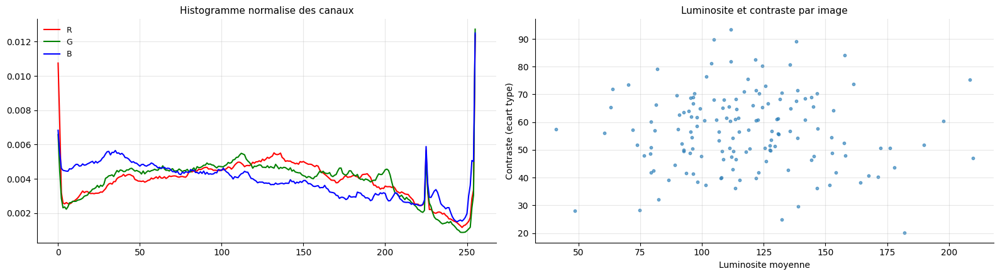


⏱ Temps d'execution de la cellule : 1.89 s


In [11]:
# 3.3 Histogrammes des canaux R, G, B et luminosite moyenne
hist = {c: np.zeros(256) for c in "RGB"}
lum_moy, contraste = [], []
for p in chemins_images:
    arr = np.asarray(Image.open(p).convert("RGB").resize((128, 128)))
    for k, c in enumerate("RGB"):
        hist[c] += np.bincount(arr[..., k].ravel(), minlength=256)
    gris = arr.mean(axis=2)
    lum_moy.append(gris.mean()); contraste.append(gris.std())

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for c, col in zip("RGB", ["red", "green", "blue"]):
    axes[0].plot(hist[c] / hist[c].sum(), color=col, label=c)
axes[0].set_title("Histogramme normalise des canaux"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].scatter(lum_moy, contraste, s=10, alpha=0.6)
axes[1].set_xlabel("Luminosite moyenne"); axes[1].set_ylabel("Contraste (ecart type)")
axes[1].set_title("Luminosite et contraste par image"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "03_couleurs.png", dpi=100, bbox_inches="tight")
plt.show()

Sur le graphique de gauche, les trois canaux couvrent toute la plage de 0 à 255 sans qu'aucun ne domine : le dataset n'a pas de dominante de couleur. Les pics aux deux extrémités viennent des zones saturées, noir pur et blanc pur, et des cadres noirs de certaines photos. Sur le graphique de droite, chaque point est une image : la luminosité moyenne va d'environ 40 à 210 et le contraste d'environ 20 à 93. Aucune image n'est presque uniforme, puisque le contraste le plus faible, autour de 20, reste loin du seuil de 5 utilisé ensuite dans les contrôles qualité.

On estime le bruit déjà présent dans chaque photo. On soustrait à l'image en niveaux de gris sa version floutée (noyau gaussien 3 × 3) : il reste surtout le bruit et les détails fins. On mesure ensuite l'écart type de ce résidu de façon robuste (MAD × 1,4826), ce qui donne l'écart type d'un bruit gaussien sans être faussé par les contours forts. La mesure est faite à la résolution de travail du modèle (plus petit côté de 256 px), car réduire une image fait baisser son bruit apparent.

Bruit estime a la resolution de travail : mediane 0.0080, 90e centile 0.0194, 95e centile 0.0240, maximum 0.0425


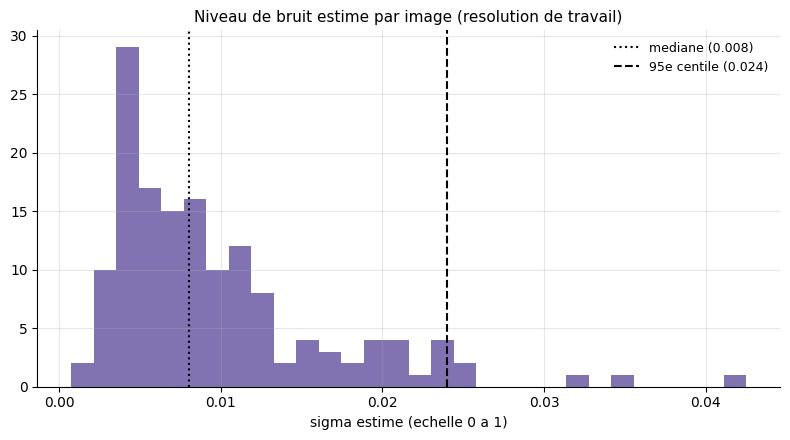

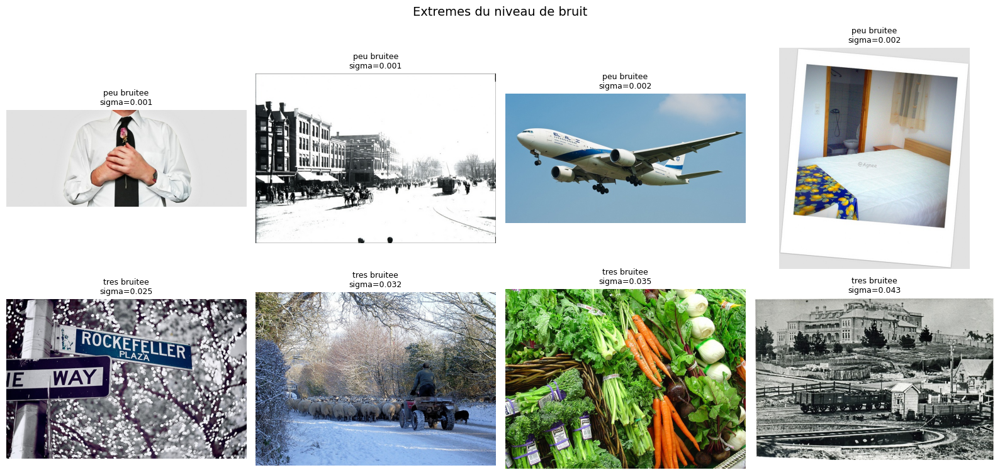


⏱ Temps d'execution de la cellule : 2.25 s


In [12]:
# 3.4 Estimation du niveau de bruit deja present dans chaque image
# Methode : ecart type du residu (image moins image floutee), mesure robuste (MAD).
# La mesure est faite a la resolution de travail du modele (section 4) : plus petit cote ramene a COTE_COURT
# pixels au plus, format conserve. Reduire une image moyenne ses pixels et diminue donc son bruit apparent :
# mesurer a une autre resolution que celle de l'entrainement fausserait le choix du niveau de bruit.
COTE_COURT = 256


def a_la_resolution_de_travail(img):
    """Ramene le plus petit cote a COTE_COURT pixels (jamais d'agrandissement), sans deformer l'image."""
    w, h = img.size
    echelle = min(1.0, COTE_COURT / min(w, h))
    return img.resize((round(w * echelle), round(h * echelle)), Image.BILINEAR) if echelle < 1 else img


def estimer_bruit(arr):
    gris = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    residu = gris - cv2.GaussianBlur(gris, (3, 3), 0)
    return 1.4826 * np.median(np.abs(residu - np.median(residu)))


df_infos["bruit estime"] = [estimer_bruit(np.asarray(a_la_resolution_de_travail(Image.open(p).convert("RGB"))))
                            for p in chemins_images]
quantiles = df_infos["bruit estime"].quantile([0.5, 0.9, 0.95, 1.0])
print("Bruit estime a la resolution de travail : mediane {:.4f}, 90e centile {:.4f}, 95e centile {:.4f}, "
      "maximum {:.4f}".format(*quantiles.values))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df_infos["bruit estime"], bins=30, color="#8172B2")
ax.axvline(quantiles.loc[0.5], color="black", ls=":", label=f"mediane ({quantiles.loc[0.5]:.3f})")
ax.axvline(quantiles.loc[0.95], color="black", ls="--", label=f"95e centile ({quantiles.loc[0.95]:.3f})")
ax.set_title("Niveau de bruit estime par image (resolution de travail)")
ax.set_xlabel("sigma estime (echelle 0 a 1)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Images les plus et les moins bruitees
ordre = df_infos.sort_values("bruit estime")
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, row) in zip(axes[0], ordre.head(4).iterrows()):
    ax.imshow(Image.open(DOSSIERSOURCE / row["nom"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"peu bruitee\nsigma={row['bruit estime']:.3f}", fontsize=9)
for ax, (_, row) in zip(axes[1], ordre.tail(4).iterrows()):
    ax.imshow(Image.open(DOSSIERSOURCE / row["nom"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"tres bruitee\nsigma={row['bruit estime']:.3f}", fontsize=9)
plt.suptitle("Extremes du niveau de bruit", fontsize=14)
plt.tight_layout(); plt.show()

Le bruit déjà présent dans les photos est faible : la médiane vaut 0,008 sur une échelle de 0 à 1, soit environ 2 niveaux de gris sur 255, le 90e centile 0,019, le 95e centile 0,024 et le maximum 0,043. Toutes les photos restent donc sous 0,08, la valeur maximale du bruit que l'on ajoutera pendant l'entraînement : la plage choisie couvre bien le dataset.

La seconde figure montre une limite de cet estimateur. Les images classées « très bruitées » sont surtout très texturées (guirlandes lumineuses, branches enneigées, légumes, grain d'une photo ancienne), alors que les images « peu bruitées » ont de grandes zones unies (ciel, chemise, fond blanc). L'estimateur ne sait pas distinguer un détail fin d'un vrai bruit : il compte les deux. Le vrai bruit des photos est donc probablement encore plus faible que ces chiffres.

### Validation des données

On contrôle ici la qualité du dataset avec des règles simples. Chaque contrôle donne un statut OK ou ALERTE, et le tableau final résume l'ensemble.

On applique cinq contrôles automatiques : fichiers illisibles, images non RGB, doublons exacts (empreinte MD5 du fichier), images de moins de 128 px, images presque uniformes (contraste inférieur à 5). Les doublons seraient retirés avant le découpage, pour qu'une même photo ne puisse pas être à la fois en entraînement et en test.

In [13]:
# 3.5 Controles qualite automatiques
import hashlib

def hash_fichier(p):
    return hashlib.md5(open(p, "rb").read()).hexdigest()

hashes = pd.Series([hash_fichier(p) for p in chemins_images])
nb_doublons = int(hashes.duplicated().sum())

nb_corrompus   = len(chemins_images) - len(infos)
nb_non_rgb     = int((df_infos["mode"] != "RGB").sum())
nb_petites     = int(((df_infos["largeur"] < 128) | (df_infos["hauteur"] < 128)).sum())
nb_quasi_vides = int((np.array(contraste) < 5).sum())    # images presque uniformes

controles = pd.DataFrame([
    ["Fichiers illisibles",               nb_corrompus,   nb_corrompus == 0],
    ["Images non RGB",                    nb_non_rgb,     nb_non_rgb == 0],
    ["Doublons exacts (hash MD5)",        nb_doublons,    nb_doublons == 0],
    ["Images plus petites que 128 px",    nb_petites,     nb_petites == 0],
    ["Images quasi uniformes (contraste<5)", nb_quasi_vides, nb_quasi_vides == 0],
], columns=["Controle", "Nombre", "OK"])
controles["Statut"] = controles["OK"].map({True: "OK", False: "ALERTE"})
display(controles.drop(columns="OK"))

# Les doublons sont retires pour eviter qu'une meme image se retrouve en train ET en test
if nb_doublons:
    garder = ~hashes.duplicated().values
    chemins_images = [p for p, g in zip(chemins_images, garder) if g]
    print(f"{nb_doublons} doublon(s) retire(s). Images restantes : {len(chemins_images)}")

,Controle,Nombre,Statut
0,Fichiers illisibles,0,OK
1,Images non RGB,0,OK
2,Doublons exacts (hash MD5),0,OK
3,Images plus petites que 128 px,0,OK
4,Images quasi uniformes (contraste<5),0,OK



⏱ Temps d'execution de la cellule : 0.06 s


Les cinq contrôles passent : aucun fichier illisible, aucune image non RGB, aucun doublon exact, aucune image trop petite et aucune image quasi uniforme. On peut donc garder les 148 images sans en retirer aucune. Il faut cependant connaître la limite du contrôle des doublons : l'empreinte MD5 ne repère que des fichiers strictement identiques, pas deux photos presque semblables, par exemple la même scène recadrée.

En résumé, les images n'ont ni la même taille ni le même format (rapport largeur sur hauteur de 0,66 à 2,75) : la section 4 les ramène à une résolution commune **sans les déformer**. Les doublons exacts auraient été retirés, car une même image présente à la fois en entraînement et en test gonflerait artificiellement les scores ; il n'y en a aucun. Enfin, le bruit déjà présent dans les photos est faible, ce qui fixe la plage de bruit utilisée à l'entraînement (section 7).

<a id="s4"></a>
## 4. Prétraitement : résolution de travail, format conservé

Chaque image est réduite pour que son plus petit côté fasse au plus 256 pixels, **en gardant son format** : une image de 640 × 480 devient 341 × 256. Une image plus petite n'est jamais agrandie. Les valeurs sont ramenées entre 0 et 1, ce qui correspond à la plage de sortie du modèle (bornée entre 0 et 1).

Pourquoi ne plus forcer un carré de 128 × 128 ? Le carré déformait les images (jusqu'à un facteur 2,75), et passer de 640 à 128 pixels moyenne des blocs de 5 × 5 pixels, ce qui efface une grande partie du bruit réel avant même le débruitage et rend la sortie trop petite pour la génération de légendes du livrable 3. Le modèle étant entièrement convolutif (section 10), il traite ensuite des images de n'importe quelle taille.

On fixe les paramètres globaux : patchs de 64 × 64 sans chevauchement, graine 42, bruit d'entraînement σ tiré entre 0 et 0,08 pour chaque patch, et les quatre niveaux de bruit de l'évaluation finale (0,02 ; 0,04 ; 0,06 ; 0,08). On vérifie aussi quelle part des photos a un bruit estimé dans cette plage.

### Justification des paramètres globaux

**Patchs de 64 × 64 sans chevauchement.** 64 est divisible par 4, donc les deux sous-échantillonnages du UNet (chacun divise la taille par 2) donnent des dimensions entières et les connexions de saut se concatènent sans recadrage. C’est aussi cohérent avec un modèle de 467 000 paramètres, dont le champ réceptif (environ 47 pixels) reste inférieur à 64 pixels. Le découpage multiplie les exemples (2 151 patchs d’entraînement, 468 en validation, 496 en test) pour un dataset de 148 images. L’absence de chevauchement évite la redondance : chaque pixel n’est compté qu’une fois, et les patchs d’une même image restent des exemples distincts. Elle complète le découpage par image fait avant l’extraction, qu’un assert vérifie.

**Graine 42.** Elle garantit la reproductibilité : mêmes images, même validation et même test bruités pour tous les modèles. Les écarts mesurés viennent donc du modèle, et non du hasard. La valeur 42 est une simple convention.

**σ d’entraînement tiré entre 0 et 0,08, pour chaque patch.** La version précédente utilisait σ = 0,06 fixe, ce qui poussait le modèle à trop lisser et dégradait les images peu bruitées. Une plage de σ donne un modèle unique, qui s’adapte au niveau de bruit, ce qui est nécessaire sur des photos réelles. Elle contient les quatre niveaux d’évaluation, donc le test interpole au lieu d’extrapoler. La borne à 0 évite de dégrader les images propres (CBSD68 : 44,23 → 44,21 dB, p = 0,86, alors que le filtre gaussien perd 11,8 dB). Un σ tiré à nouveau à chaque époque limite aussi le sur-apprentissage.

**Niveaux d’évaluation 0,02 ; 0,04 ; 0,06 ; 0,08.** Régulièrement espacés, ils couvrent du bruit léger au bruit fort et montrent l’évolution du gain (+6,1 dB à σ = 0,02, +10,3 dB à σ = 0,08). Ces jeux de test sont figés, donc comparables entre modèles. L’écart absolu moyen mesuré (≈ 0,8 σ) correspond à la valeur théorique d’un bruit gaussien, σ·√(2/π).

**Part des photos dans la plage.** Le bruit estimé (MAD du résidu à la résolution de travail) a pour médiane 0,008, pour 95ᵉ centile 0,024 et pour maximum 0,043 : 100 % des photos sont sous 0,08. L’estimateur confond détail fin et bruit, donc le vrai bruit est probablement encore plus faible, et la plage choisie est conservatrice.

**Limites.** Le bruit gaussien additif simplifie le bruit réel. La cible contient encore le bruit d’origine (montage Noisier2Noise). Le test CBSD68, qui a une vérité terrain propre, et la conservation des contours (UNet 100 %, filtre gaussien 82 %) vérifient que cette simplification ne dégrade pas le résultat.

In [14]:
# ============================================================
# ETAPE 3 : PRETRAITEMENT DES IMAGES
# ============================================================
from sklearn.model_selection import train_test_split
import tensorflow as tf

# 3.1 Paramètres globaux
PATCH_SIZE = 64             # patchs 64 x 64 pour l'entraînement
STRIDE     = 64             # patchs sans chevauchement : chaque pixel n'est compté qu'une fois
SEED       = 42
SIGMA_MIN, SIGMA_MAX = 0.0, 0.08          # bruit ajouté pendant l'entraînement, tiré pour chaque patch
SIGMAS_EVAL = [0.02, 0.04, 0.06, 0.08]   # niveaux de bruit connus utilisés pour l'évaluation sur le test

print(f"Résolution de travail : plus petit côté ≤ {COTE_COURT} px, format conservé")
print(f"Patchs                : {PATCH_SIZE}x{PATCH_SIZE} (pas de {STRIDE})")
print(f"Bruit d'entraînement  : sigma uniforme entre {SIGMA_MIN} et {SIGMA_MAX}, tiré à nouveau à chaque époque")
couverture = (df_infos["bruit estime"] <= SIGMA_MAX).mean()
print(f"Part des photos dont le bruit estimé est dans cette plage : {couverture:.1%}")

Résolution de travail : plus petit côté ≤ 256 px, format conservé
Patchs                : 64x64 (pas de 64)
Bruit d'entraînement  : sigma uniforme entre 0.0 et 0.08, tiré à nouveau à chaque époque
Part des photos dont le bruit estimé est dans cette plage : 100.0%

⏱ Temps d'execution de la cellule : 3.70 s


Le rappel des paramètres confirme le choix de la plage de bruit : 100 % des photos ont un bruit estimé compris entre 0 et 0,08. Le modèle verra donc pendant l'entraînement des niveaux de bruit qui couvrent au moins celui de toutes nos photos.

On charge chaque photo, la réduit pour que son plus petit côté fasse au plus 256 px (interpolation bilinéaire, format conservé, jamais d'agrandissement) et divise les valeurs par 255. Les images sont gardées dans une liste, parce qu'elles n'ont pas toutes la même taille.

In [15]:
# 3.2 Redimensionnement (format conservé) + normalisation
def charger_et_preparer(chemin):
    """Charge une image, la ramène à la résolution de travail sans la déformer, valeurs entre 0 et 1."""
    img = a_la_resolution_de_travail(Image.open(chemin).convert("RGB"))
    return np.asarray(img, dtype=np.float32) / 255.0


images_propres = [charger_et_preparer(p) for p in chemins_images]   # liste : les tailles diffèrent
formes = pd.Series([f"{im.shape[1]}x{im.shape[0]}" for im in images_propres])
print(f"{len(images_propres)} images préparées, {formes.nunique()} tailles différentes ; les plus fréquentes :")
print(formes.value_counts().head(5).to_string())
print(f"Min / Max des valeurs : {min(im.min() for im in images_propres):.3f} / "
      f"{max(im.max() for im in images_propres):.3f}")
print(f"Mémoire : {sum(im.nbytes for im in images_propres) / 1e6:.0f} Mo")

148 images préparées, 46 tailles différentes ; les plus fréquentes :
341x256    47
384x256    20
256x341    10
256x256     7
386x256     6
Min / Max des valeurs : 0.000 / 1.000
Mémoire : 163 Mo

⏱ Temps d'execution de la cellule : 0.88 s


Les 148 images sont préparées, dans 46 tailles différentes, puisque chacune garde son format. La taille la plus fréquente est 341 × 256 (47 images, ce sont les photos de 640 × 480 réduites), suivie de 384 × 256 (20 images). Les valeurs sont bien comprises entre 0 et 1, la plage attendue par le modèle, et l'ensemble n'occupe que 163 Mo de mémoire, ce qui permet de tout garder en mémoire sur Colab.

On affiche les trois premières images après prétraitement, avec leur taille et leurs valeurs minimale et maximale.

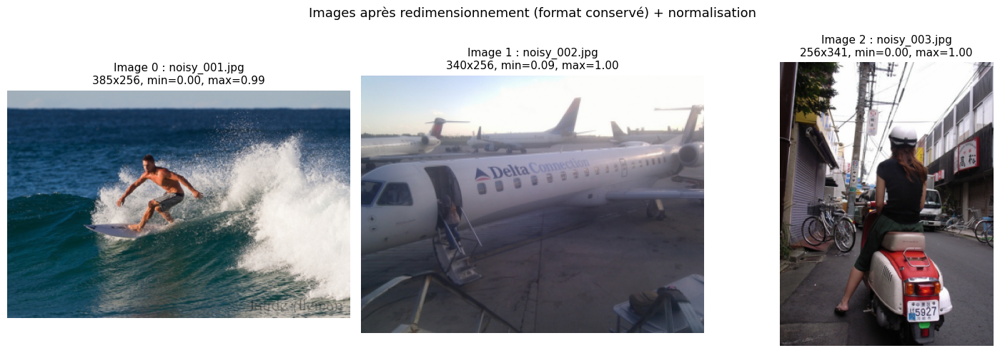


⏱ Temps d'execution de la cellule : 1.27 s


In [16]:
# 3.3 Vérification visuelle après prétraitement
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, idx in zip(axes, [0, 1, 2]):
    ax.imshow(images_propres[idx])
    h, w = images_propres[idx].shape[:2]
    ax.set_title(f"Image {idx} : {chemins_images[idx].name}\n{w}x{h}, "
                 f"min={images_propres[idx].min():.2f}, max={images_propres[idx].max():.2f}")
    ax.axis("off")
plt.suptitle("Images après redimensionnement (format conservé) + normalisation", fontsize=13)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "05_apres_pretraitement.png", dpi=100, bbox_inches="tight")
plt.show()

Les trois images gardent leurs proportions d'origine (385 × 256, 340 × 256 et 256 × 341 pour la photo en hauteur) et leurs valeurs restent entre 0 et 1. Visuellement, aucun sujet n'est déformé : la réduction a bien conservé le format, ce qui n'aurait pas été le cas avec un carré imposé.

<a id="s5"></a>
## 5. Découpage train, validation et test

Le découpage se fait **image par image, avant l'extraction des patchs** (70 / 15 / 15). Si on découpait après, des patchs voisins d'une même photo se retrouveraient dans le train et dans le test, et le modèle serait évalué sur des données qu'il a pratiquement déjà vues.

On découpe les numéros d'images en deux temps avec `train_test_split` : 70 % pour l'entraînement et 30 % mis de côté, puis ces 30 % coupés en deux (validation et test). Trois `assert` vérifient qu'aucune image n'appartient à deux ensembles.

In [17]:
# ============================================================
# ÉTAPE 4 : SPLIT TRAIN / VALIDATION / TEST (par image)
# ============================================================
# ⚠️ Règle d'or : on splitte AU NIVEAU DES IMAGES, AVANT d'extraire
# les patchs. Ainsi aucune image vue à l'entraînement n'apparaît
# en validation ou test (pas de data leakage).

from sklearn.model_selection import train_test_split

indices = np.arange(len(images_propres))

# 70 % train | 30 % temp
idx_train, idx_temp = train_test_split(
    indices, test_size=0.30, random_state=SEED, shuffle=True
)

# 15 % val | 15 % test
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, random_state=SEED, shuffle=True
)

print("=== SPLIT PAR IMAGE ===")
print(f"Train : {len(idx_train)} images")
print(f"Val   : {len(idx_val)} images")
print(f"Test  : {len(idx_test)} images")
print(f"Total : {len(idx_train) + len(idx_val) + len(idx_test)} images")

# Vérification : aucune image partagée entre ensembles
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val)   & set(idx_test)) == 0
print("✅ Aucune image partagée entre train / val / test.")

=== SPLIT PAR IMAGE ===
Train : 103 images
Val   : 22 images
Test  : 23 images
Total : 148 images
✅ Aucune image partagée entre train / val / test.

⏱ Temps d'execution de la cellule : 0.01 s


On obtient 103 images pour l'entraînement, 22 pour la validation et 23 pour le test. Les 30 % mis de côté correspondent à 45 images, partagées en 22 et 23. Les trois vérifications automatiques confirment qu'aucune image n'appartient à deux ensembles à la fois : c'est la garantie qu'aucune information du test ne fuira dans l'entraînement.

<a id="s6"></a>
## 6. Extraction des patchs

Chaque image est découpée en patchs de 64 × 64 **sans chevauchement** (pas de 64). Une image de 341 × 256 donne 5 × 4 = 20 patchs. Les patchs d'une même image restent tous dans le même ensemble, et on garde pour chaque patch le numéro de son image : l'évaluation statistique de la section 15 se fait image par image, car les patchs d'une même photo ne sont pas des exemples indépendants.

Pour l'entraînement, la variété ne vient pas du chevauchement mais du bruit, tiré à nouveau à chaque époque, et de l'augmentation (section 8).

On parcourt chaque image en grille, par pas de 64 px, et découpe des carrés de 64 × 64. Pour chaque patch, on garde le numéro de son image d'origine : il sert au test statistique de la section 15, qui compare les modèles image par image. Un `assert` vérifie qu'aucune image d'entraînement n'a de patch en validation ou en test.

In [18]:
# ============================================================
# ÉTAPE 4b : EXTRACTION DE PATCHS PAR ENSEMBLE
# ============================================================
def extraire_patches_par_indices(images, indices, patch_size=PATCH_SIZE, stride=STRIDE):
    """Patchs des images désignées, et numéro de l'image d'origine de chaque patch."""
    patches, origine = [], []
    for i in indices:
        img = images[i]
        H, W = img.shape[:2]
        for y in range(0, H - patch_size + 1, stride):
            for x in range(0, W - patch_size + 1, stride):
                patches.append(img[y:y + patch_size, x:x + patch_size])
                origine.append(i)
    return np.stack(patches), np.array(origine)


patches_train, origine_train = extraire_patches_par_indices(images_propres, idx_train)
patches_val,   origine_val   = extraire_patches_par_indices(images_propres, idx_val)
patches_test,  origine_test  = extraire_patches_par_indices(images_propres, idx_test)
print("=== PATCHS PAR ENSEMBLE ===")
print(f"Train : {patches_train.shape} ({len(idx_train)} images)")
print(f"Val   : {patches_val.shape} ({len(idx_val)} images)")
print(f"Test  : {patches_test.shape} ({len(idx_test)} images)")
assert set(origine_train).isdisjoint(origine_val) and set(origine_train).isdisjoint(origine_test)
print("✅ Aucun patch d'une image d'entraînement en validation ou en test.")

=== PATCHS PAR ENSEMBLE ===
Train : (2151, 64, 64, 3) (103 images)
Val   : (468, 64, 64, 3) (22 images)
Test  : (496, 64, 64, 3) (23 images)
✅ Aucun patch d'une image d'entraînement en validation ou en test.

⏱ Temps d'execution de la cellule : 0.08 s


Le découpage donne 2 151 patchs d'entraînement, 468 de validation et 496 de test, soit environ 21 patchs par image. Comme les patchs ne se chevauchent pas, le bord d'une image qui ne remplit pas un patch entier est laissé de côté : pour une image de 341 pixels de large, cinq patchs couvrent 320 pixels et les 21 derniers ne sont pas utilisés. Le dernier contrôle confirme qu'aucun patch d'une image d'entraînement ne se retrouve en validation ou en test, puisque le découpage a été fait image par image.

On affiche quatre images de chaque ensemble : entraînement en vert, validation en orange, test en rouge.

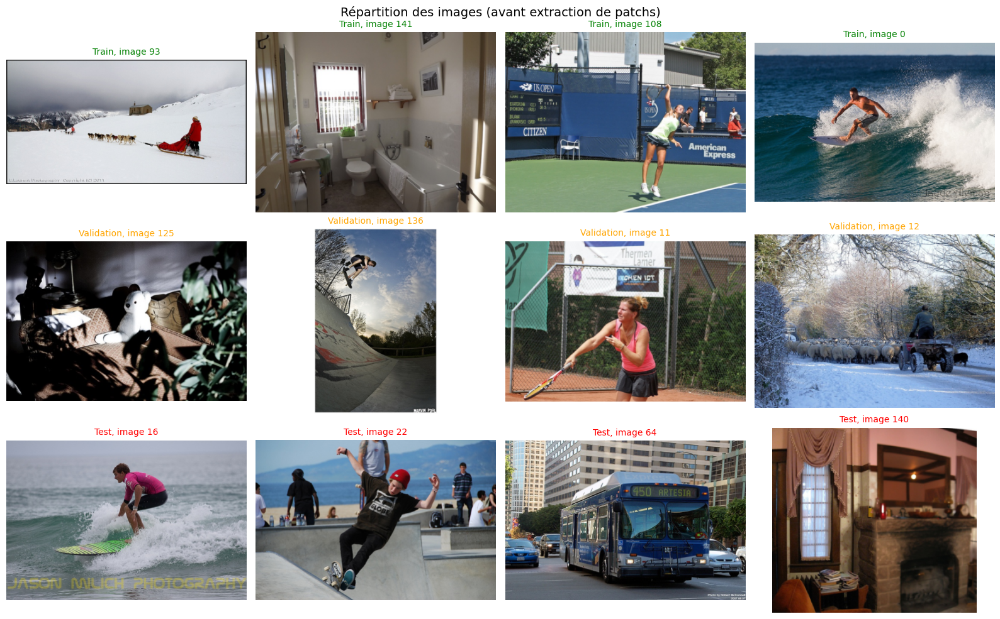


⏱ Temps d'execution de la cellule : 2.93 s


In [19]:
# ============================================================
# ÉTAPE 4c : VISUALISATION DU SPLIT
# ============================================================
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ligne, (idx_list, nom, couleur) in enumerate(
        [(idx_train, "Train", "green"), (idx_val, "Validation", "orange"), (idx_test, "Test", "red")]):
    for col, i in enumerate(idx_list[:4]):
        axes[ligne, col].imshow(images_propres[i]); axes[ligne, col].axis("off")
        axes[ligne, col].set_title(f"{nom}, image {i}", color=couleur, fontsize=10)
plt.suptitle("Répartition des images (avant extraction de patchs)", fontsize=14)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "08_split_train_val_test.png", dpi=100, bbox_inches="tight")
plt.show()

Chaque photo apparaît dans un seul des trois ensembles. Ce contrôle visuel complète les vérifications automatiques de la cellule de découpage.

<a id="s7"></a>
## 7. Création des paires bruitée et cible

Le dataset ne contient **pas de version propre** des photos : les 148 fichiers JPEG fournis sont déjà légèrement bruités. On prend donc chaque patch d'origine comme **cible**, et on fabrique l'entrée en lui ajoutant un bruit gaussien. Il faut être précis sur ce que cela implique :

* le modèle apprend à **retirer le bruit qu'on ajoute**, pas à retrouver une image parfaitement propre, puisque la cible contient encore le bruit d'origine ;
* ce montage, où l'entrée est une version *encore plus bruitée* d'une cible déjà bruitée, correspond à **Noisier2Noise** (Moran et al., CVPR 2020), et non à Noise2Noise (Lehtinen et al., ICML 2018), qui demande deux versions bruitées indépendantes d'une même image propre ;
* en pratique, un réseau qui ne peut pas distinguer le bruit ajouté du bruit d'origine en retire aussi une partie ; c'est ce que vérifie, indirectement, la section 16.4 sur les photos réelles ;
* les PSNR et SSIM de la section 14 sont donc calculés par rapport à la photo d'origine : ils mesurent la capacité à retirer un bruit de niveau connu.

**Niveau de bruit.** La version précédente utilisait σ = 0,06 en affirmant qu'il était du même ordre que le bruit réel ; l'histogramme de la section 3.4 montre au contraire un bruit réel bien plus faible. Entraîné à un seul niveau fort, le modèle avait appris à lisser fortement et dégradait les images peu bruitées. Ici, **chaque patch reçoit un σ tiré au hasard entre 0 et 0,08** : le modèle apprend à adapter son lissage au bruit qu'il voit, y compris à ne presque rien faire quand l'image est déjà nette (σ proche de 0).

Pour l'entraînement, le bruit est tiré **à chaque époque** dans le pipeline (section 8). Pour la validation et le test, il est tiré une fois avec une graine fixe, pour que toutes les mesures soient comparables d'une époque et d'un modèle à l'autre ; le test est en plus décliné à quatre niveaux connus (σ = 0,02, 0,04, 0,06 et 0,08).

La fonction `bruiter_fixe` ajoute à chaque patch un bruit gaussien de niveau σ (un σ par patch), avec une graine fixe, puis borne le résultat entre 0 et 1. On s'en sert pour fabriquer une validation et un test « courants » (σ tiré entre 0 et 0,08, comme à l'entraînement) et quatre versions du test à σ connu, pour l'évaluation finale. Ces paires sont figées : elles ne changent jamais.

In [20]:
# ============================================================
# ÉTAPE 5 : PAIRES (BRUITÉE, CIBLE) POUR LA VALIDATION ET LE TEST
# ============================================================
# y = patch d'origine (la cible) ; x = y + bruit gaussien de niveau sigma, borné à [0, 1].
np.random.seed(SEED)
tf.random.set_seed(SEED)

y_train_propre, y_val_propre, y_test_propre = patches_train, patches_val, patches_test


def bruiter_fixe(patches, sigmas, graine):
    """Bruit gaussien figé (graine fixe) : un sigma par patch."""
    rng = np.random.default_rng(graine)
    sigmas = np.asarray(sigmas, dtype=np.float32).reshape(-1, 1, 1, 1)
    bruit = rng.standard_normal(patches.shape).astype(np.float32)
    return np.clip(patches + sigmas * bruit, 0.0, 1.0)


# Validation et test « courants » : sigma tiré dans la même plage qu'à l'entraînement
sigma_val = np.random.default_rng(SEED + 1).uniform(SIGMA_MIN, SIGMA_MAX, len(y_val_propre))
sigma_test = np.random.default_rng(SEED + 2).uniform(SIGMA_MIN, SIGMA_MAX, len(y_test_propre))
x_val_bruite = bruiter_fixe(y_val_propre, sigma_val, SEED + 3)
x_test_bruite = bruiter_fixe(y_test_propre, sigma_test, SEED + 4)

# Test à niveau de bruit connu, pour l'évaluation finale (section 14)
tests_par_sigma = {s: bruiter_fixe(y_test_propre, np.full(len(y_test_propre), s), SEED + 10 + k)
                   for k, s in enumerate(SIGMAS_EVAL)}

print("=== PAIRES ===")
print(f"Train : {len(y_train_propre)} cibles ; entrées bruitées tirées à chaque époque (section 8)")
print(f"Val   : x={x_val_bruite.shape}, sigma entre {sigma_val.min():.3f} et {sigma_val.max():.3f}")
print(f"Test  : x={x_test_bruite.shape}, sigma entre {sigma_test.min():.3f} et {sigma_test.max():.3f}")
print(f"Test à sigma connu : {', '.join(str(s) for s in SIGMAS_EVAL)}")

=== PAIRES ===
Train : 2151 cibles ; entrées bruitées tirées à chaque époque (section 8)
Val   : x=(468, 64, 64, 3), sigma entre 0.000 et 0.080
Test  : x=(496, 64, 64, 3), sigma entre 0.000 et 0.080
Test à sigma connu : 0.02, 0.04, 0.06, 0.08

⏱ Temps d'execution de la cellule : 0.77 s


La validation (468 paires) et le test (496 paires) sont figés, avec un niveau de bruit tiré entre 0 et 0,08 pour chaque patch. Le test existe aussi en quatre versions où tous les patchs ont le même niveau de bruit, de 0,02 à 0,08 : elles serviront à mesurer les performances niveau par niveau. Les entrées d'entraînement, elles, ne sont pas figées : elles sont tirées à nouveau à chaque époque (section 8), pour que le modèle ne puisse pas apprendre par cœur un bruit particulier.

On montre un même patch de test aux quatre niveaux de bruit, à côté de sa cible, et calcule pour chaque niveau l'écart absolu moyen entre l'entrée bruitée et la cible.

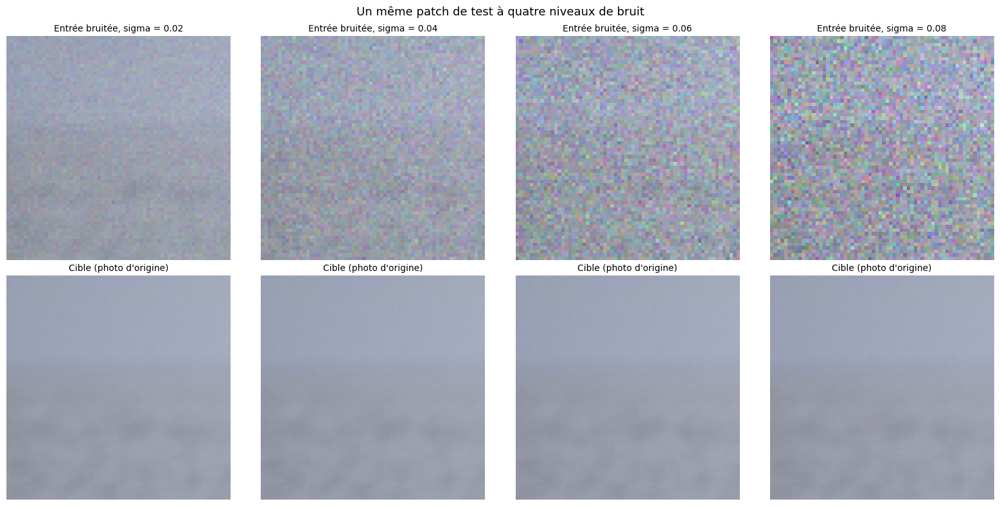

sigma = 0.02 : écart moyen entre entrée et cible = 0.0158
sigma = 0.04 : écart moyen entre entrée et cible = 0.0313
sigma = 0.06 : écart moyen entre entrée et cible = 0.0465
sigma = 0.08 : écart moyen entre entrée et cible = 0.0614

⏱ Temps d'execution de la cellule : 1.23 s


In [21]:
# 5.3 Vérification visuelle : entrée bruitée et cible, à plusieurs niveaux
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, s in enumerate(SIGMAS_EVAL):
    axes[0, col].imshow(tests_par_sigma[s][0]); axes[0, col].axis("off")
    axes[0, col].set_title(f"Entrée bruitée, sigma = {s}", fontsize=10)
    axes[1, col].imshow(y_test_propre[0]); axes[1, col].axis("off")
    axes[1, col].set_title("Cible (photo d'origine)", fontsize=10)
plt.suptitle("Un même patch de test à quatre niveaux de bruit", fontsize=13)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "09_paires_bruitees.png", dpi=100, bbox_inches="tight")
plt.show()
for s in SIGMAS_EVAL:
    print(f"sigma = {s} : écart moyen entre entrée et cible = {np.mean(np.abs(tests_par_sigma[s] - y_test_propre)):.4f}")

Le patch affiché est presque uni : sur la cible, aucun bruit n'est visible, alors qu'il devient très marqué à σ = 0,08. Les écarts moyens mesurés entre l'entrée et la cible (0,0158 ; 0,0313 ; 0,0465 ; 0,0614) valent environ 0,8 × σ. C'est exactement la valeur attendue pour un bruit gaussien, dont l'écart absolu moyen vaut σ × √(2/π), soit environ 0,8 σ. Ils sont un peu plus bas à fort bruit, parce que les pixels sont bornés entre 0 et 1 et que le bruit ne peut pas dépasser ces bornes. Le bruit ajouté est donc bien celui qu'on annonce.

<a id="s8"></a>
## 8. Augmentation de données et bruit tiré à chaque époque

Le pipeline d'entraînement part des **cibles** et fabrique les entrées à la volée :

1. (modèle avec augmentation seulement) une transformation géométrique est tirée **pour chaque patch** : rotation de 0, 90, 180 ou 270° et symétrie horizontale ou non, soit les 8 orientations possibles ;
2. un σ est tiré entre 0 et 0,08, puis un bruit gaussien de ce niveau est ajouté.

Comme la transformation est appliquée à la cible *avant* d'ajouter le bruit, l'entrée et la cible sont alignées par construction. Et comme ces étapes sont rejouées à chaque époque, le modèle ne revoit jamais exactement la même entrée bruitée : il ne peut pas apprendre par cœur une réalisation du bruit.

**Piège évité.** Quand on fixe la graine globale de TensorFlow, les tirages aléatoires classiques appelés dans un pipeline tf.data redonnent exactement les mêmes valeurs à chaque époque : le « nouveau » bruit serait en réalité toujours le même, et l'augmentation se répéterait à l'identique. Ici, chaque patch reçoit sa propre graine, tirée à nouveau à chaque époque, et les tirages sont « sans état » (stateless) : ils changent d'une époque à l'autre tout en restant reproductibles d'une exécution à l'autre. Le contrôle chiffré placé sous la visualisation le vérifie.

Pourquoi pas de changement de couleur, de luminosité ou de flou ? Ces transformations changeraient le contenu de la cible et la statistique du bruit déjà présent. Les rotations et symétries conservent exactement les deux.

La fonction `fabriquer_paire` prépare un exemple d'entraînement. On découpe la graine du patch en quatre graines : rotation, symétrie, niveau σ et bruit. Si l'augmentation est demandée, la cible est tournée d'un multiple de 90° et éventuellement retournée. Puis un σ est tiré entre 0 et 0,08 et le bruit est ajouté. Les tirages « sans état » (stateless) donnent un bruit vraiment nouveau à chaque époque tout en gardant l'exécution reproductible.

In [22]:
# Tirages aléatoires du pipeline : chaque patch reçoit une graine, retirée à chaque époque.
# Pourquoi pas simplement tf.random.uniform / tf.random.normal dans le pipeline ? Avec une graine globale
# (tf.keras.utils.set_random_seed), ces fonctions redonnent EXACTEMENT les mêmes tirages à chaque nouvelle époque :
# le « nouveau » bruit serait en réalité toujours le même. Les tirages « sans état » (stateless) alimentés par
# tf.data.Dataset.random(rerandomize_each_iteration=True) changent bien à chaque époque tout en restant reproductibles.

def fabriquer_paire(y, graine, augment):
    '''Cible éventuellement augmentée (rotation de k x 90° et symétrie tirées pour CE patch), puis entrée bruitée
    avec un sigma tiré entre SIGMA_MIN et SIGMA_MAX.'''
    g = tf.random.experimental.stateless_split(graine, num=4)
    if augment:
        k = tf.random.stateless_uniform((), g[0], minval=0, maxval=4, dtype=tf.int32)
        y = tf.image.rot90(y, k=k)
        y = tf.cond(tf.random.stateless_uniform((), g[1]) < 0.5, lambda: tf.image.flip_left_right(y), lambda: y)
    sigma = tf.random.stateless_uniform((), g[2], minval=SIGMA_MIN, maxval=SIGMA_MAX)
    x = tf.clip_by_value(y + sigma * tf.random.stateless_normal(tf.shape(y), g[3]), 0.0, 1.0)
    return x, y


⏱ Temps d'execution de la cellule : 0.00 s


On définit les deux pipelines `tf.data`. Pour l'entraînement : les cibles sont mélangées à chaque époque, chaque patch reçoit une graine renouvelée à chaque époque, les paires sont fabriquées à la volée puis regroupées par lots de 32. Pour la validation et le test : paires figées, sans mélange, sans augmentation, sans nouveau bruit.

In [23]:
# ============================================================
# Pipelines tf.data
# ============================================================
def creer_dataset_entrainement(y, batch_size=32, augment=True, melanger=True):
    '''Cibles mélangées, augmentées (si demandé) puis bruitées à la volée : tout est tiré à nouveau à chaque époque.'''
    ds = tf.data.Dataset.from_tensor_slices(y)
    if melanger:
        ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    graines = tf.data.Dataset.random(seed=SEED, rerandomize_each_iteration=True).batch(2)   # une graine par patch
    ds = tf.data.Dataset.zip((ds, graines))
    ds = ds.map(lambda cible, graine: fabriquer_paire(cible, graine, augment), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def creer_dataset_fixe(x, y, batch_size=32):
    '''Paires figées (validation, test) : ni mélange, ni augmentation, ni nouveau bruit.'''
    return tf.data.Dataset.from_tensor_slices((x, y)).batch(batch_size).prefetch(tf.data.AUTOTUNE)


⏱ Temps d'execution de la cellule : 0.00 s


On fait passer six patchs deux fois dans le pipeline d'entraînement (comme deux époques), sans mélange pour garder l'ordre, et affiche les cibles et les entrées obtenues. Deux contrôles chiffrés suivent : l'entrée est-elle alignée avec sa cible, et le tirage change-t-il d'une époque à l'autre ?

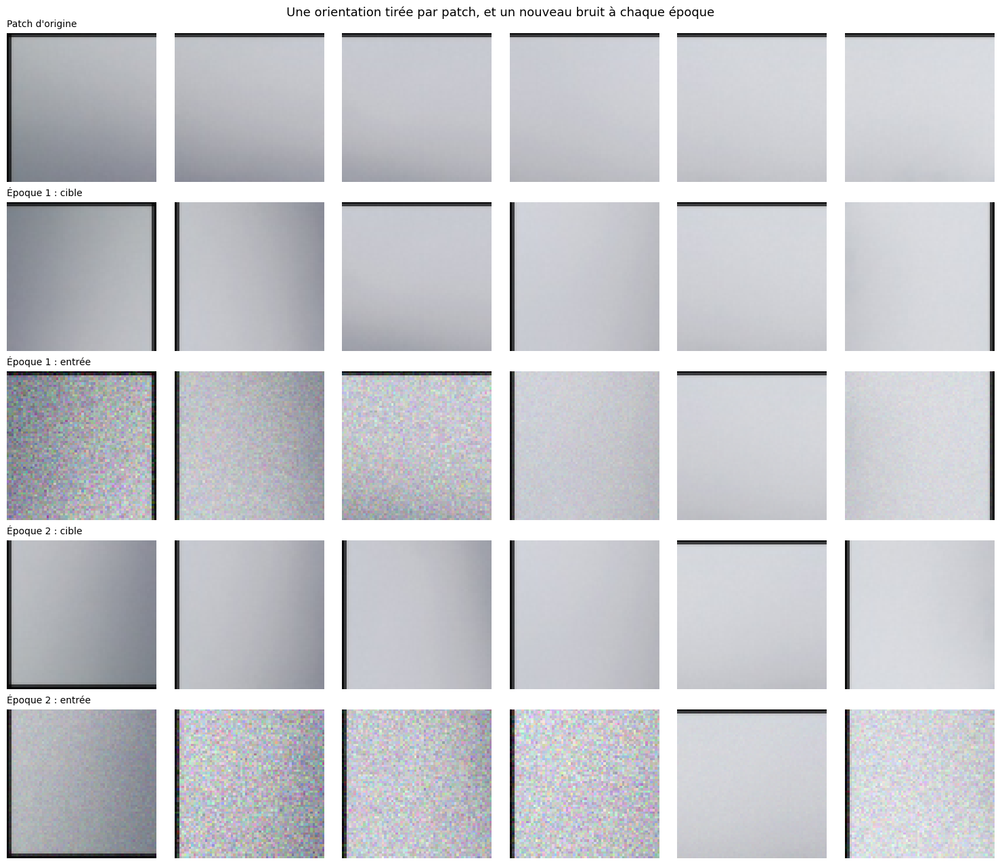

Écart moyen entrée et cible = 0.0248 (de l'ordre du bruit ajouté) contre 0.0875 si la cible était tournée de 90° : l'entrée et la cible sont bien alignées.
Le bruit et l'orientation changent d'une époque à l'autre : True

⏱ Temps d'execution de la cellule : 5.53 s


In [24]:
# ============================================================
# ÉTAPE 6c : VISUALISATION DE L'AUGMENTATION ET DU BRUIT À LA VOLÉE
# ============================================================
# Même chaîne que l'entraînement, sans mélange pour garder l'ordre des patchs ; deux passages = deux époques.
demo = creer_dataset_entrainement(y_train_propre[:6], batch_size=6, augment=True, melanger=False)
x_p1, y_p1 = next(iter(demo))          # premier passage (une époque)
x_p2, y_p2 = next(iter(demo))          # second passage : nouvelles transformations, nouveau bruit
lignes = [(y_train_propre[:6], "Patch d'origine"), (y_p1, "Époque 1 : cible"), (x_p1, "Époque 1 : entrée"),
          (y_p2, "Époque 2 : cible"), (x_p2, "Époque 2 : entrée")]
fig, axes = plt.subplots(len(lignes), 6, figsize=(15, 13))
for r, (images, titre) in enumerate(lignes):
    for c in range(6):
        axes[r, c].imshow(np.clip(np.asarray(images[c]), 0, 1)); axes[r, c].axis("off")
    axes[r, 0].set_title(titre, fontsize=10, loc="left")
plt.suptitle("Une orientation tirée par patch, et un nouveau bruit à chaque époque", fontsize=13)
plt.tight_layout()
plt.show()

# Contrôles chiffrés
ecart_aligne = float(tf.reduce_mean(tf.abs(x_p1 - y_p1)))
ecart_si_desaligne = float(tf.reduce_mean(tf.abs(x_p1 - tf.image.rot90(y_p1))))
print(f"Écart moyen entrée et cible = {ecart_aligne:.4f} (de l'ordre du bruit ajouté) contre {ecart_si_desaligne:.4f} "
      "si la cible était tournée de 90° : l'entrée et la cible sont bien alignées.")
print("Le bruit et l'orientation changent d'une époque à l'autre :", not np.allclose(x_p1.numpy(), x_p2.numpy()))

La première ligne montre six patchs d'origine, des zones grises presque unies avec un bord sombre. Sur les lignes 2 et 4, on voit que la même cible change d'orientation d'une époque à l'autre : le bord sombre passe en haut, à gauche ou à droite. Sur les lignes 3 et 5, l'entrée garde toujours exactement l'orientation de sa cible, avec un bruit dont l'intensité varie d'un patch et d'une époque à l'autre : fort sur certains patchs, presque nul sur d'autres, puisque σ est tiré entre 0 et 0,08.

Les deux contrôles chiffrés confirment ce qu'on voit. L'écart moyen entre l'entrée et sa cible vaut 0,0248, contre 0,0875 si la cible était tournée de 90° : l'entrée et la cible sont donc bien alignées, sans quoi le modèle apprendrait n'importe quoi. Et le tirage change bien d'une époque à l'autre (`True`), ce qui montre que le piège des tirages répétés a été évité.

<a id="s9"></a>
## 9. Pourquoi ce choix de méthode ? (why, how, why not)

### Why : pourquoi un autoencodeur convolutif
Un autoencodeur compresse l'image dans un espace latent puis la reconstruit. Comme le bruit est aléatoire et difficile à compresser, il est en grande partie perdu lors de la compression, alors que les structures (contours, textures, couleurs) sont conservées. Les convolutions exploitent le fait qu'un pixel ressemble à ses voisins, avec peu de paramètres et une bonne généralisation.

### How : comment on l'a construit
* entrée : image RGB bruitée de taille quelconque (patchs de 64 × 64 à l'entraînement), sortie : image débruitée de même taille ;
* encodeur à 3 niveaux (32, 64, 128 filtres), décodeur symétrique ;
* connexions de saut (skip connections) entre encodeur et décodeur, ce qui donne une architecture de type UNet ;
* aucune couche dense : le réseau est **entièrement convolutif** et s'applique à une image entière, sans la découper ;
* **apprentissage résiduel** : le réseau estime le bruit, et la sortie vaut *entrée moins bruit estimé*, bornée entre 0 et 1. La dernière couche part de zéro, donc au début de l'entraînement le modèle renvoie l'image telle quelle et ne peut pas la dégrader ;
* **GroupNormalization** pour stabiliser l'entraînement (au lieu de BatchNormalization, voir plus bas) ;
* bruit d'entraînement de niveau variable (σ entre 0 et 0,08) tiré à nouveau à chaque époque, pour un débruitage qui s'adapte au niveau de bruit ;
* perte MSE, optimiseur Adam avec montée progressive puis décroissance en cosinus du taux d'apprentissage, gradient borné ;
* évaluation avec la **moyenne mobile des poids** (EMA) ; arrêt anticipé et choix du meilleur modèle décidés sur la validation.

### Pourquoi les courbes sont lisses
Un premier essai, avec BatchNormalization, Dropout et un taux d'apprentissage constant divisé par deux sur plateau, donnait une courbe de validation pleine de pics : la perte pouvait être multipliée par 3 à 5 d'une époque à la suivante. Trois causes ont été identifiées, et chacune a sa correction :

| Cause des oscillations | Correction retenue |
|:--|:--|
| BatchNormalization normalise avec les statistiques du lot à l'entraînement, mais avec des moyennes mobiles à l'évaluation. Ces moyennes sont en retard sur les poids : la validation saute. | **GroupNormalization** : même calcul à l'entraînement et à l'évaluation, indépendant du lot. |
| Taux d'apprentissage élevé et constant, puis divisé par deux par paliers : les gros pas font sortir le modèle d'un bon minimum. | **Montée progressive** sur 3 époques puis **décroissance en cosinus** jusqu'à 1 % de la valeur de départ, et norme du gradient bornée à 1. |
| Les poids changent à chaque lot ; ceux de la dernière itération de l'époque ne sont qu'un point au hasard autour du minimum. | **Moyenne mobile exponentielle des poids** (EMA, 0,99) utilisée pour la validation, le test et le modèle final. |

Le Dropout a aussi été retiré : aucun signe de surapprentissage n'était observé et il rendait la perte d'entraînement plus bruitée. Le bruit tiré à nouveau à chaque époque régularise déjà le modèle. Le tableau 2b de la section 13 le vérifie chiffres à l'appui : aucune remontée pour le modèle sans augmentation, et une seule pour le modèle avec augmentation (7 % à l'époque 40, rattrapée en cinq époques), loin des facteurs 3 à 5 du premier essai.

### Why not : les alternatives écartées
| Alternative | Pourquoi on ne l'a pas retenue |
|:--|:--|
| Filtre gaussien ou médian | Rapide mais floute aussi les contours. Sert de point de comparaison (section 14), avec des réglages choisis sur la validation. |
| Non Local Means (OpenCV) | Bon résultat à faible bruit mais lent, et un seul réglage ne convient pas à tous les niveaux de bruit. Aussi gardé comme comparaison. |
| BM3D | Référence classique très solide, mais plusieurs minutes de calcul sur nos 2 000 patchs de test et une bibliothèque en plus ; Non Local Means joue le même rôle de méthode non apprise. |
| ACP (PCA) | Modèle linéaire : il ne capte pas les textures complexes, et il travaille sur des vecteurs aplatis en perdant la structure spatiale. |
| Autoencodeur dense (fully connected) | Énormément de paramètres pour une image 64 × 64 × 3, ignore la proximité entre pixels, surapprend vite, et ne s'applique qu'à une taille d'image fixe. |
| Autoencodeur convolutif simple, sans skip | Le goulot fait perdre les détails fins : sortie souvent floue. Les skip connections réinjectent ces détails. **Mesuré** : entraîné dans les mêmes conditions comme modèle de référence (section 12 bis), il fait 6,83 dB de moins que le UNet et floute les détails (tableau 2d). |
| DnCNN, réseaux très profonds | Plus performants sur de gros datasets, mais trop lourds pour 148 images. On leur emprunte l'idée de l'apprentissage résiduel. |
| GAN de débruitage | Images plus nettes visuellement, mais entraînement instable et risque d'inventer des détails qui n'existent pas, gênant pour un usage ML en aval. |
| Perte SSIM seule | Bonne sur la structure mais peut décaler les couleurs. MSE est plus stable, et on mesure quand même le SSIM à l'évaluation. |

### Avec ou sans augmentation ?
On entraîne deux modèles identiques qui ne diffèrent que par l'augmentation (même architecture, même graine, même bruit tiré à la volée). Ainsi l'écart de résultats ne peut venir que de ce facteur. Le tableau 2 et le test par image de la section 15 tranchent. La section 15 bis refait la même comparaison avec seulement 12 images d'entraînement : c'est la situation où l'augmentation est censée servir, et elle permet de vérifier que l'absence d'effet avec toutes les images vient bien de l'abondance de données, et pas d'une erreur dans le pipeline.

<a id="s10"></a>
## 10. Architecture : autoencodeur convolutif UNet

On construit le UNet. Chaque bloc fait deux convolutions 3 × 3 suivies de GroupNormalization (8 groupes) et de ReLU. L'encodeur passe de 32 à 64 puis 128 filtres, avec deux MaxPooling. Le décodeur remonte symétriquement (UpSampling) et reçoit deux skip connections qui réinjectent les détails de l'encodeur. Une dernière convolution 1 × 1, initialisée à zéro, estime le bruit. La sortie vaut entrée moins bruit estimé, bornée entre 0 et 1. À la fin, on vérifie que le modèle non entraîné renvoie exactement son entrée.

Nous choisissons un UNet car le bruit, aléatoire, se compresse mal dans l’espace latent alors que les structures de l’image se conservent ; les connexions de saut réinjectent en plus les détails fins de l’encodeur, ce qu’un autoencodeur simple perd (+6,83 dB en faveur du UNet, et 100 % des contours conservés contre 91 %). Chaque bloc enchaîne deux convolutions 3 × 3 (champ réceptif de 5 × 5 avec moins de paramètres) puis GroupNormalization à 8 groupes, dont le calcul est identique à l’entraînement et à l’évaluation, contrairement à BatchNormalization qui rendait la validation instable. L’encodeur passe de 32 à 64 puis 128 filtres avec deux MaxPooling, ce qui suffit pour estimer un bruit local ; le modèle reste léger (≈ 467 000 paramètres) pour limiter le sur-apprentissage sur 148 images. Le réseau, entièrement convolutif, s’entraîne sur des patchs mais s’applique à des images entières. Enfin, il apprend le bruit plutôt que l’image : la sortie vaut l’entrée moins le bruit estimé, bornée entre 0 et 1. Comme la dernière convolution 1 × 1 est initialisée à zéro, le modèle non entraîné renvoie exactement son entrée (écart maximal mesuré : 0), ce qui garantit que l’entraînement part de l’identité et ne peut pas dégrader l’image.

In [25]:
# ============================================================
# Architecture UNet résiduelle, entièrement convolutive
# ============================================================
from tensorflow.keras import layers, Model, Input


def bloc_conv(x, filtres):
    """Deux convolutions 3x3 + GroupNormalization + ReLU.
    GroupNorm calcule la même chose à l'entraînement et à l'évaluation (contrairement à BatchNorm)."""
    for _ in range(2):
        x = layers.Conv2D(filtres, 3, padding="same", use_bias=False)(x)
        x = layers.GroupNormalization(groups=8)(x)
        x = layers.Activation("relu")(x)
    return x


def construire_unet(canaux=3):
    """U-Net léger : 3 niveaux d'encodeur + 3 de décodeur. Taille d'entrée libre (multiple de 4).
    Le réseau estime le bruit ; la sortie vaut entrée - bruit estimé, bornée entre 0 et 1."""
    entree = Input(shape=(None, None, canaux), name="entree")
    # ENCODEUR
    c1 = bloc_conv(entree, 32)                  # (H, W, 32)
    p1 = layers.MaxPooling2D(2)(c1)             # (H/2, W/2, 32)
    c2 = bloc_conv(p1, 64)                      # (H/2, W/2, 64)
    p2 = layers.MaxPooling2D(2)(c2)             # (H/4, W/4, 64)
    c3 = bloc_conv(p2, 128)                     # (H/4, W/4, 128)  ← espace latent
    # DÉCODEUR (avec skip connections)
    u2 = layers.UpSampling2D(2)(c3)
    u2 = layers.Conv2D(64, 2, padding="same")(u2)
    u2 = layers.Concatenate()([u2, c2])         # ⭐ SKIP CONNECTION
    c4 = bloc_conv(u2, 64)
    u1 = layers.UpSampling2D(2)(c4)
    u1 = layers.Conv2D(32, 2, padding="same")(u1)
    u1 = layers.Concatenate()([u1, c1])         # ⭐ SKIP CONNECTION
    c5 = bloc_conv(u1, 32)
    # SORTIE RÉSIDUELLE
    bruit_estime = layers.Conv2D(canaux, 1, kernel_initializer="zeros", name="bruit_estime")(c5)  # vaut 0 au départ
    image = layers.Subtract(name="entree_moins_bruit")([entree, bruit_estime])
    sortie = layers.ReLU(max_value=1.0, name="sortie")(image)                                   # bornée entre 0 et 1
    return Model(entree, sortie, name="unet_residuel_denoising")


autoencodeur = construire_unet(canaux=3)
autoencodeur.summary()

# Vérification : avant entraînement, le modèle renvoie exactement son entrée (il ne peut pas dégrader l'image)
essai = x_val_bruite[:4]
print("Écart max entre sortie initiale et entrée :", float(np.abs(autoencodeur.predict(essai, verbose=0) - essai).max()))

Model: "unet_residuel_denoising"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entree (InputLayer) │ (None, None,      │          0 │ -                 │
│                     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, None,      │        864 │ entree[0][0]      │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, None,      │         64 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, None,      │          0 │ group_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, None,      │      9,216 │ activation[0][0]  │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, None,      │         64 │ conv2d_1[0][0]    │
│ (GroupNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, None,      │          0 │ group_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, None,      │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, None,      │     18,432 │ max_pooling2d[0]… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, None,      │        128 │ conv2d_2[0][0]    │
│ (GroupNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, None,      │          0 │ group_normalizat… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, None,      │     36,864 │ activation_2[0][… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, None,      │        128 │ conv2d_3[0][0]    │
│ (GroupNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, None,      │          0 │ group_normalizat… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, None,      │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, None,      │     73,728 │ max_pooling2d_1[… │
│                     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, None,      │        256 │ conv2d_4[0][0]  

 Total params: 467,235 (1.78 MB)

 Trainable params: 467,235 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

Écart max entre sortie initiale et entrée : 0.0

⏱ Temps d'execution de la cellule : 5.13 s


Le modèle compte 467 235 paramètres, soit 1,78 Mo, tous entraînables. C'est un réseau léger, adapté à un dataset de 148 images : un modèle beaucoup plus gros risquerait davantage d'apprendre les images par cœur. La vérification finale donne un écart maximal de exactement 0 entre la sortie et l'entrée avant tout entraînement. Grâce à la dernière couche initialisée à zéro, le réseau part donc de l'identité : au départ, il renvoie l'image telle quelle et ne peut pas commencer par la dégrader.

### Modèle de référence : autoencodeur convolutif simple

On construit un **modèle de référence** : un autoencodeur convolutif classique. Il reprend les mêmes blocs et le même nombre de filtres que le UNet (32, 64, 128), mais il n'a **pas de skip connections** : toute l'information passe par le goulot, quatre fois plus petit que l'image. Il n'a pas non plus de sortie résiduelle : il produit directement l'image, bornée entre 0 et 1 par une sigmoïde. C'est le modèle que la section 9 écarte en disant que le goulot fait perdre les détails ; ici, on le mesure au lieu de l'affirmer. On affiche son nombre de paramètres à côté de celui du UNet.

In [26]:
# Modèle de référence : autoencodeur convolutif simple, SANS skip connections et SANS sortie résiduelle
def construire_autoencodeur_simple(canaux=3):
    """Mêmes blocs et même nombre de filtres que le UNet, mais toute l'information passe par le goulot,
    et le réseau produit directement l'image (sigmoïde), sans le raccourci « entrée moins bruit estimé »."""
    entree = Input(shape=(None, None, canaux), name="entree")
    x = bloc_conv(entree, 32); x = layers.MaxPooling2D(2)(x)      # (H/2, W/2, 32)
    x = bloc_conv(x, 64);      x = layers.MaxPooling2D(2)(x)      # (H/4, W/4, 64)
    x = bloc_conv(x, 128)                                         # goulot (H/4, W/4, 128)
    x = layers.UpSampling2D(2)(x); x = bloc_conv(x, 64)           # (H/2, W/2, 64)
    x = layers.UpSampling2D(2)(x); x = bloc_conv(x, 32)           # (H, W, 32)
    sortie = layers.Conv2D(canaux, 1, activation="sigmoid", name="sortie")(x)
    return Model(entree, sortie, name="autoencodeur_simple")


essai_simple = construire_autoencodeur_simple(canaux=3)
print(f"Autoencodeur simple : {essai_simple.count_params():,} paramètres "
      f"(UNet : {autoencodeur.count_params():,})".replace(",", " "))

Autoencodeur simple : 426 179 paramètres (UNet : 467 235)

⏱ Temps d'execution de la cellule : 0.13 s


L'autoencodeur simple compte 426 179 paramètres, contre 467 235 pour le UNet, soit environ 9 % de moins. La différence vient du décodeur du UNet, qui reçoit en plus les canaux des skip connections et possède deux petites convolutions de remontée. Les deux modèles ont donc une taille comparable : si l'un fait nettement mieux que l'autre, ce sera grâce à son architecture, et non parce qu'il a plus de paramètres.

### Fonctions communes d'entraînement

Une seule fonction d'entraînement sert à tous les modèles :

* **taux d'apprentissage** : montée linéaire de 0,0001 à 0,001 pendant 3 époques, puis décroissance en cosinus jusqu'à 0,00001 à la dernière époque ; norme du gradient bornée à 1 ;
* **moyenne mobile des poids (EMA)** : un callback tient à jour une moyenne mobile des poids après chaque lot. Avant chaque évaluation, il installe ces poids moyennés dans le modèle, puis remet les poids bruts au début de l'époque suivante pour continuer l'entraînement. Le meilleur modèle gardé par l'arrêt anticipé est donc un modèle EMA ;
* **mesures de fin d'époque, toutes dans les mêmes conditions** (poids EMA, mode évaluation, paires figées) : perte sur 500 patchs d'**entraînement** bruités une fois pour toutes, sur la **validation** et sur le **test**. Ce sont ces trois mesures que tracent les courbes de la section 13 ;
* l'arrêt anticipé, le choix du meilleur modèle et le taux d'apprentissage ne dépendent que de la validation ; le test n'est que suivi.

Chaque modèle entraîné est enregistré sur le Drive sous un nom qui contient une empreinte de sa configuration (architecture, niveaux de bruit, résolution, augmentation, hyperparamètres, images d'entraînement). Par défaut (`REENTRAINER = True`), chaque exécution réentraîne tous les modèles, pour que le journal des époques soit visible. Avec `REENTRAINER = False`, une relance recharge un modèle **seulement si la configuration est identique**, et réaffiche son journal ; aucune décision de rechargement ne regarde le test.

On définit tout ce qui sert à l'entraînement. Hyperparamètres : lots de 32, 80 époques, taux d'apprentissage qui monte de 0,0001 à 0,001 en 3 époques puis décroît en cosinus jusqu'à 0,00001, gradient borné à 1, perte MSE, optimiseur Adam. `jeu_train_eval` fige 500 patchs d'entraînement bruités pour tracer une courbe train mesurée comme la validation. `MoyenneMobilePoids` tient une moyenne mobile des poids (EMA 0,99) et l'installe avant chaque évaluation. `MesuresFinEpoque` mesure à chaque époque la perte sur ces 500 patchs et sur le test (simple suivi). `entrainer` entraîne le modèle et affiche une ligne par époque. Avec `REENTRAINER = True` (réglage par défaut), tout est réentraîné à chaque exécution ; avec `False`, un modèle de même configuration déjà enregistré sur le Drive est rechargé et son journal d'époques est réaffiché. L'entraînement se fait avec un arrêt anticipé sur la validation (patience 20) qui garde la meilleure époque. Le test ne sert à aucune décision.

In [27]:
# Fonctions communes : moyenne mobile des poids, mesures de fin d'époque, chargement ou entraînement
import json, math
BATCH_SIZE    = 32
EPOCHS        = 80        # durée fixe du plan cosinus ; l'arrêt anticipé peut couper avant
WARMUP        = 3         # époques de montée progressive du taux d'apprentissage
LR_MAX        = 1e-3
EMA_DECAY     = 0.99
REENTRAINER   = True      # True : chaque modèle est réentraîné et son journal d'époques s'affiche ;
                          # False : un modèle déjà entraîné avec la même configuration est rechargé depuis le Drive
VERSION_MODELE = "v4-unet-residuel-groupnorm-cosinus-ema"   # inchangé : permet de recharger les modèles déjà entraînés


def jeu_train_eval(y, graine):
    """500 patchs d'entraînement au plus, bruités une fois pour toutes (même plage de sigma) :
    la courbe « train » est mesurée exactement comme la validation et le test."""
    sel = np.random.default_rng(graine).choice(len(y), min(500, len(y)), replace=False)
    y_ev = y[sel]
    x_ev = bruiter_fixe(y_ev, np.random.default_rng(graine + 1).uniform(SIGMA_MIN, SIGMA_MAX, len(sel)), graine + 2)
    return x_ev, y_ev


x_train_eval, y_train_eval = jeu_train_eval(y_train_propre, SEED + 5)


class MoyenneMobilePoids(tf.keras.callbacks.Callback):
    """EMA des poids. Les poids moyennés sont installés avant chaque évaluation (validation, mesures de fin
    d'époque, sauvegarde du meilleur modèle) ; les poids bruts sont remis au début de l'époque suivante."""

    def __init__(self, decay=EMA_DECAY):
        super().__init__()
        self.decay = decay

    def on_train_begin(self, logs=None):
        self.ema = [tf.Variable(w.numpy(), trainable=False) for w in self.model.weights]
        self.bruts, self.n = None, 0

    def on_train_batch_end(self, batch, logs=None):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))      # démarrage rapide de la moyenne
        for e, w in zip(self.ema, self.model.weights):
            e.assign(d * e + (1.0 - d) * tf.convert_to_tensor(w))

    def on_test_begin(self, logs=None):
        if self.bruts is None:
            self.bruts = [w.numpy() for w in self.model.weights]
            for w, e in zip(self.model.weights, self.ema):
                w.assign(e)

    def on_epoch_begin(self, epoch, logs=None):
        if getattr(self, "bruts", None) is not None:
            for w, b in zip(self.model.weights, self.bruts):
                w.assign(b)
            self.bruts = None


class MesuresFinEpoque(tf.keras.callbacks.Callback):
    """Perte et MAE sur la partie figée de l'entraînement et sur le test (suivi seulement, aucune décision).
    Appelé après la validation : le modèle porte alors les poids EMA."""

    def __init__(self, x_ev, y_ev):
        super().__init__()
        self.jeux = {"train_eval": (x_ev, y_ev), "test": (x_test_bruite, y_test_propre)}

    def on_epoch_end(self, epoch, logs=None):
        for prefixe, (x, y) in self.jeux.items():
            loss, mae = self.model.evaluate(x, y, batch_size=64, verbose=0)
            logs[f"{prefixe}_loss"], logs[f"{prefixe}_mae"] = loss, mae


def configuration(augment, images=None, architecture="unet"):
    images = idx_train if images is None else images
    # La clé « architecture » n'est ajoutée que pour l'autoencodeur simple : l'empreinte des UNet ne change pas,
    # donc les UNet déjà entraînés sont toujours rechargés depuis le Drive.
    extra = {} if architecture == "unet" else {"architecture": architecture}
    return {**extra, "version": VERSION_MODELE, "augment": augment, "sigma": [SIGMA_MIN, SIGMA_MAX], "cote": COTE_COURT,
            "patch": PATCH_SIZE, "stride": STRIDE, "batch": BATCH_SIZE, "epochs": EPOCHS, "warmup": WARMUP,
            "lr": LR_MAX, "ema": EMA_DECAY, "seed": SEED, "images_train": [int(i) for i in images]}


def entrainer(nom, augment, images=None, architecture="unet"):
    """Construit, entraîne et sauvegarde un modèle (UNet par défaut, ou "simple" pour l'autoencodeur sans skip), ou le recharge si la même configuration a déjà été entraînée.
    images : numéros des images d'entraînement à utiliser (par défaut toutes celles du train).
    Renvoie modele, historique, duree (s)."""
    cle = hashlib.md5(json.dumps(configuration(augment, images, architecture), sort_keys=True).encode()).hexdigest()[:8]
    chemin_modele = DOSSIERTRAVAIL / f"{nom}_{cle}.keras"
    chemin_histo = DOSSIERTRAVAIL / f"{nom}_{cle}_historique.json"
    if not REENTRAINER and chemin_modele.exists() and chemin_histo.exists():
        infos_sauv = json.load(open(chemin_histo))
        h = infos_sauv["history"]
        print(f"Modèle rechargé depuis le Drive (même configuration, entraîné en {infos_sauv['duree'] / 60:.1f} min). "
              "Journal de son entraînement :")
        for e in range(len(h["loss"])):
            print(f"Époque {e + 1}/{len(h['loss'])} - loss {h['loss'][e]:.4e} - val_loss {h['val_loss'][e]:.4e} - "
                  f"train_eval_loss {h['train_eval_loss'][e]:.4e} - test_loss {h['test_loss'][e]:.4e}")
        return tf.keras.models.load_model(chemin_modele), h, infos_sauv["duree"]
    if not tf.config.list_physical_devices("GPU"):
        print("⚠️ Pas de GPU : l'entraînement sera lent. Sur Colab : Exécution, Modifier le type d'exécution, GPU.")

    if images is None:                            # cas principal : toutes les images d'entraînement
        y_tr, x_ev, y_ev = y_train_propre, x_train_eval, y_train_eval
    else:                                         # étude sur données réduites (section 15 bis)
        y_tr = y_train_propre[np.isin(origine_train, images)]
        x_ev, y_ev = jeu_train_eval(y_tr, SEED + 50)

    tf.keras.utils.set_random_seed(SEED)          # mêmes poids initiaux et même suite de bruits pour les deux variantes
    modele = construire_unet(canaux=3) if architecture == "unet" else construire_autoencodeur_simple(canaux=3)
    pas_par_epoque = math.ceil(len(y_tr) / BATCH_SIZE)
    plan_lr = tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=LR_MAX / 10, warmup_target=LR_MAX, warmup_steps=WARMUP * pas_par_epoque,
        decay_steps=(EPOCHS - WARMUP) * pas_par_epoque, alpha=0.01)
    modele.compile(optimizer=tf.keras.optimizers.Adam(plan_lr, clipnorm=1.0), loss="mse", metrics=["mae"])
    train_ds = creer_dataset_entrainement(y_tr, BATCH_SIZE, augment=augment)
    val_ds = creer_dataset_fixe(x_val_bruite, y_val_propre, BATCH_SIZE)
    callbacks = [
        MoyenneMobilePoids(),                     # en premier : installe les poids EMA avant toute mesure
        MesuresFinEpoque(x_ev, y_ev),
        tf.keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True, monitor="val_loss"),
    ]
    t0 = time.perf_counter()
    h = modele.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
    duree = time.perf_counter() - t0
    histo = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    histo["learning_rate"] = [float(plan_lr((e + 1) * pas_par_epoque)) for e in range(len(histo["loss"]))]
    modele.save(chemin_modele)                    # poids EMA de la meilleure époque de validation
    json.dump({"history": histo, "duree": duree, "configuration": configuration(augment, images, architecture)}, open(chemin_histo, "w"))
    print(f"\nEntraîné en {duree / 60:.1f} min sur {len(histo['loss'])} époques et {len(y_tr)} patchs "
          f"(meilleure époque de validation : {int(np.argmin(histo['val_loss'])) + 1}).")
    return modele, histo, duree


⏱ Temps d'execution de la cellule : 0.14 s


<a id="s11"></a>
## 11. Modèle A : entraînement avec augmentation

Une rotation et une symétrie tirées pour chaque patch, à chaque époque, puis un bruit de niveau aléatoire. La validation et le test ne sont jamais augmentés.

On entraîne le modèle A, avec augmentation (rotation et symétrie tirées pour chaque patch, à chaque époque).

In [28]:
modele_aug, histo_aug, duree_aug = entrainer("unet_avec_augmentation", augment=True)

Epoch 1/80
68/68 - 58s - 859ms/step - loss: 0.0016 - mae: 0.0280 - val_loss: 0.0010 - val_mae: 0.0228 - train_eval_loss: 9.8940e-04 - train_eval_mae: 0.0225 - test_loss: 9.6818e-04 - test_mae: 0.0223
Epoch 2/80
68/68 - 5s - 75ms/step - loss: 7.8037e-04 - mae: 0.0203 - val_loss: 7.2707e-04 - val_mae: 0.0195 - train_eval_loss: 6.9912e-04 - train_eval_mae: 0.0191 - test_loss: 6.8203e-04 - test_mae: 0.0188
Epoch 3/80
68/68 - 5s - 72ms/step - loss: 6.3775e-04 - mae: 0.0183 - val_loss: 6.2577e-04 - val_mae: 0.0180 - train_eval_loss: 6.0797e-04 - train_eval_mae: 0.0178 - test_loss: 5.8580e-04 - test_mae: 0.0174
Epoch 4/80
68/68 - 5s - 73ms/step - loss: 5.8547e-04 - mae: 0.0175 - val_loss: 5.7255e-04 - val_mae: 0.0171 - train_eval_loss: 5.5604e-04 - train_eval_mae: 0.0169 - test_loss: 5.3254e-04 - test_mae: 0.0165
Epoch 5/80
68/68 - 5s - 72ms/step - loss: 5.6871e-04 - mae: 0.0173 - val_loss: 5.3910e-04 - val_mae: 0.0166 - train_eval_loss: 5.2364e-04 - train_eval_mae: 0.0165 - test_loss: 5.0116

Le journal affiche une ligne par époque, chacune composée de 68 pas (2 151 patchs divisés en lots de 32). La première époque prend 59 s, le temps que TensorFlow construise le graphe de calcul et que le GPU se prépare ; les suivantes ne prennent qu'environ 5 s.

Pour lire ce journal, trois colonnes comptent. `val_loss` est la perte sur la validation : c'est elle qui décide de l'arrêt anticipé et du meilleur modèle. `train_eval_loss` est la perte sur 500 patchs d'entraînement mesurés exactement comme la validation, ce qui permet de comparer les deux honnêtement. `test_loss` n'est qu'un suivi. La colonne `loss`, elle, est mesurée sur des lots qui changent et avec les poids bruts : elle est plus bruitée et ne sert pas aux courbes.

La perte de validation passe de 0,0010 à l'époque 1 à 0,000313 à l'époque 80, qui est la meilleure. On note une seule irrégularité : à l'époque 40, les trois pertes remontent ensemble d'environ 7 % (la validation passe de 0,000329 à 0,000354), puis repassent sous leur niveau d'avant dès l'époque 45. La section 13 revient sur ce point. À la fin, le modèle atteint 0,000294 en train, 0,000313 en validation et 0,000287 en test, après 7,7 minutes d'entraînement.

<a id="s12"></a>
## 12. Modèle B : entraînement sans augmentation

Même architecture, même graine, mêmes hyperparamètres, mêmes données et même bruit tiré à la volée. Seule différence : les patchs d'entraînement gardent leur orientation d'origine.

On entraîne le modèle B : même architecture, même graine, mêmes hyperparamètres, même bruit tiré à la volée. Seule différence : pas d'augmentation.

In [29]:
modele_sans, histo_sans, duree_sans = entrainer("unet_sans_augmentation", augment=False)

Epoch 1/80
68/68 - 31s - 452ms/step - loss: 0.0016 - mae: 0.0280 - val_loss: 0.0010 - val_mae: 0.0228 - train_eval_loss: 9.8554e-04 - train_eval_mae: 0.0225 - test_loss: 9.6445e-04 - test_mae: 0.0222
Epoch 2/80
68/68 - 5s - 75ms/step - loss: 7.7653e-04 - mae: 0.0202 - val_loss: 7.2305e-04 - val_mae: 0.0194 - train_eval_loss: 6.9465e-04 - train_eval_mae: 0.0190 - test_loss: 6.7726e-04 - test_mae: 0.0187
Epoch 3/80
68/68 - 5s - 74ms/step - loss: 6.3370e-04 - mae: 0.0183 - val_loss: 6.2108e-04 - val_mae: 0.0179 - train_eval_loss: 6.0247e-04 - train_eval_mae: 0.0177 - test_loss: 5.8112e-04 - test_mae: 0.0173
Epoch 4/80
68/68 - 5s - 74ms/step - loss: 5.7756e-04 - mae: 0.0174 - val_loss: 5.6775e-04 - val_mae: 0.0171 - train_eval_loss: 5.5291e-04 - train_eval_mae: 0.0169 - test_loss: 5.2781e-04 - test_mae: 0.0164
Epoch 5/80
68/68 - 5s - 75ms/step - loss: 5.5789e-04 - mae: 0.0171 - val_loss: 5.3280e-04 - val_mae: 0.0165 - train_eval_loss: 5.1549e-04 - train_eval_mae: 0.0163 - test_loss: 4.9279

Le modèle B suit le même déroulement que le modèle A, mais sans aucune irrégularité. À l'époque 1, ses pertes sont presque identiques à celles du modèle A (0,0010 en validation pour les deux) : c'est normal, puisque les deux modèles partent des mêmes poids et voient les mêmes tirages de bruit. Seule l'augmentation les fait diverger ensuite. Sa première époque prend 31 s, moins que pour A, probablement parce que le GPU est déjà préchauffé. Sa meilleure époque est la 80e, et il termine à 0,000290 en train, 0,000313 en validation et 0,000286 en test, des valeurs quasiment identiques à celles du modèle A. L'entraînement a duré 7,1 minutes.

<a id="s12b"></a>
## 12 bis. Modèle de référence : autoencodeur convolutif simple

Pourquoi un UNet plutôt qu'un autoencodeur convolutif classique ? Pour répondre avec des chiffres, on entraîne l'autoencodeur simple défini en section 10 **exactement comme le modèle B** : mêmes données, même bruit tiré à chaque époque, mêmes hyperparamètres, même graine, sans augmentation. La seule différence est l'architecture (pas de skip connections, pas de sortie résiduelle). Il apparaît ensuite dans tous les tableaux et figures de comparaison.

On entraîne l'autoencodeur simple avec la même fonction `entrainer` que les UNet, en précisant `architecture="simple"`. Comme les autres modèles, il est réentraîné à chaque exécution et son journal d'époques s'affiche.

In [30]:
modele_simple, histo_simple, duree_simple = entrainer("autoencodeur_simple_sans_augmentation", augment=False, architecture="simple")

Epoch 1/80
68/68 - 30s - 444ms/step - loss: 0.0474 - mae: 0.1750 - val_loss: 0.0279 - val_mae: 0.1308 - train_eval_loss: 0.0243 - train_eval_mae: 0.1252 - test_loss: 0.0235 - test_mae: 0.1231
Epoch 2/80
68/68 - 4s - 61ms/step - loss: 0.0208 - mae: 0.1137 - val_loss: 0.0184 - val_mae: 0.1033 - train_eval_loss: 0.0153 - train_eval_mae: 0.0973 - test_loss: 0.0157 - test_mae: 0.0986
Epoch 3/80
68/68 - 4s - 60ms/step - loss: 0.0140 - mae: 0.0910 - val_loss: 0.0130 - val_mae: 0.0839 - train_eval_loss: 0.0091 - train_eval_mae: 0.0725 - test_loss: 0.0110 - test_mae: 0.0790
Epoch 4/80
68/68 - 4s - 59ms/step - loss: 0.0138 - mae: 0.0905 - val_loss: 0.0116 - val_mae: 0.0811 - train_eval_loss: 0.0085 - train_eval_mae: 0.0712 - test_loss: 0.0098 - test_mae: 0.0760
Epoch 5/80
68/68 - 4s - 61ms/step - loss: 0.0102 - mae: 0.0776 - val_loss: 0.0092 - val_mae: 0.0705 - train_eval_loss: 0.0066 - train_eval_mae: 0.0610 - test_loss: 0.0077 - test_mae: 0.0665
Epoch 6/80
68/68 - 5s - 75ms/step - loss: 0.0104

L'autoencodeur simple suit exactement le même plan d'entraînement : 68 pas par époque, 80 époques, 6,2 minutes au total. Mais sa perte de validation part de beaucoup plus haut, 0,0279 à l'époque 1 contre 0,0010 pour le UNet, et ne descend qu'à 0,0023, avec sa meilleure époque à la 76e. C'est environ **7 fois plus** que le UNet (0,000313) : avec le même entraînement, il reconstruit beaucoup moins bien les patchs. Le journal montre aussi plusieurs remontées de la perte pendant les douze premières époques, par exemple de 0,0087 à 0,0104 entre les époques 10 et 11 ; la section 13 les explique.

<a id="s13"></a>
## 13. Courbes séparées : train, validation, test

Les trois courbes sont mesurées **dans les mêmes conditions** à la fin de chaque époque : poids EMA, mode évaluation, paires bruitées figées. Elles sont donc directement comparables.

**Pourquoi les deux modèles ne sont pas tracés sur le même axe.** Les deux UNet obtiennent des pertes qui diffèrent de quelques pour cent au plus (8 % lors de la remontée de l'époque 40), et de moins de 1,5 % en fin d'entraînement : superposées, leurs courbes se cachent l'une l'autre et on ne voit qu'un seul trait. Chaque figure montre donc les deux modèles **côte à côte**, sur la même échelle, et un troisième panneau donne **l'écart relatif** entre eux, époque par époque. C'est ce panneau qui permet de voir s'il y a une différence, et de combien.

L'axe vertical de la perte est logarithmique (sinon les premières époques écrasent tout le reste) et gradué en MSE × 10 000 pour éviter la notation scientifique : 3 signifie une MSE de 0,0003.

On définit l'axe des pertes (échelle logarithmique graduée en MSE × 10 000 : 3 signifie une MSE de 0,0003) et la fonction `tracer_ensemble`. Pour un ensemble donné, celle-ci trace un panneau par modèle sur la même échelle, avec la meilleure époque annotée, puis un troisième panneau avec l'écart relatif entre les deux modèles, époque par époque. On trace ici la courbe **train**.

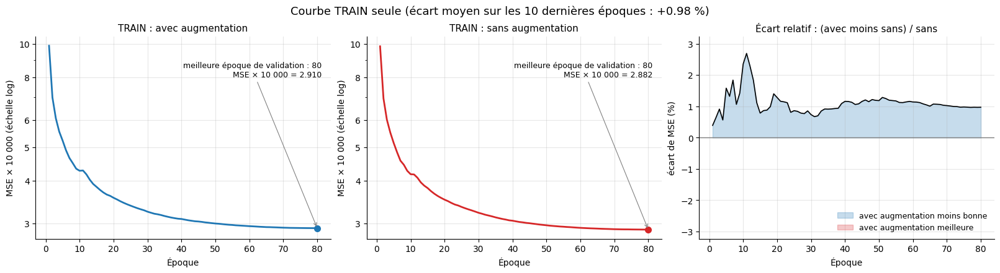


⏱ Temps d'execution de la cellule : 2.09 s


In [31]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

MODELES_HISTO = {"Avec augmentation": histo_aug, "Sans augmentation": histo_sans}
COULEURS = {"Avec augmentation": "#1f77b4", "Sans augmentation": "#d62728"}
COULEURS_ENSEMBLES = {"Train": "#2a9d8f", "Validation": "#e76f51", "Test": "#6a4c93"}


def axe_mse(ax):
    """Axe logarithmique gradué en MSE x 10 000, sans notation scientifique."""
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 1.2, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 1e4:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_ylabel("MSE × 10 000 (échelle log)")


def tracer_ensemble(cle, titre, fichier):
    """Une figure par ensemble : un panneau par modèle (même échelle), puis l'écart relatif entre les deux."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), layout="constrained")
    axes[1].sharey(axes[0])
    for ax, (nom, h) in zip(axes[:2], MODELES_HISTO.items()):
        ep = np.arange(1, len(h[cle]) + 1)
        best = int(np.argmin(h["val_loss"]))
        ax.plot(ep, h[cle], color=COULEURS[nom], lw=2)
        ax.plot(best + 1, h[cle][best], "o", color=COULEURS[nom], ms=7)
        ax.annotate(f"meilleure époque de validation : {best + 1}\nMSE × 10 000 = {h[cle][best] * 1e4:.3f}",
                    xy=(best + 1, h[cle][best]), xytext=(0.97, 0.80), textcoords="axes fraction", ha="right",
                    fontsize=9, arrowprops=dict(arrowstyle="->", color="gray", lw=0.8))
        axe_mse(ax); ax.set_xlabel("Époque"); ax.set_title(f"{titre} : {nom.lower()}")
    a, s = np.asarray(histo_aug[cle]), np.asarray(histo_sans[cle])
    n = min(len(a), len(s))
    ecart = 100 * (a[:n] / s[:n] - 1)
    ep = np.arange(1, n + 1)
    axes[2].axhline(0, color="gray", lw=1)
    axes[2].fill_between(ep, ecart, 0, where=ecart >= 0, color=COULEURS["Avec augmentation"], alpha=0.25,
                         label="avec augmentation moins bonne")
    axes[2].fill_between(ep, ecart, 0, where=ecart < 0, color=COULEURS["Sans augmentation"], alpha=0.25,
                         label="avec augmentation meilleure")
    axes[2].plot(ep, ecart, color="black", lw=1.2)
    lim = max(2.0, 1.2 * np.abs(ecart[WARMUP:] if n > WARMUP else ecart).max())   # au moins ±2 % pour ne pas grossir un écart minuscule
    axes[2].set_ylim(-lim, lim)
    axes[2].set_title("Écart relatif : (avec moins sans) / sans")
    axes[2].set_ylabel("écart de MSE (%)"); axes[2].set_xlabel("Époque")
    axes[2].legend(loc="lower right")
    fig.suptitle(f"Courbe {titre} seule (écart moyen sur les 10 dernières époques : {ecart[-10:].mean():+.2f} %)",
                 fontsize=13)
    plt.savefig(DOSSIERTRAVAIL / fichier, bbox_inches="tight")
    plt.show()


tracer_ensemble("train_eval_loss", "TRAIN", "10a courbe train.png")

Les deux courbes train descendent régulièrement : très vite pendant les dix premières époques, puis de plus en plus lentement à mesure que le taux d'apprentissage diminue. Elles terminent à 2,937 pour le modèle avec augmentation et à 2,897 pour le modèle sans augmentation, en MSE × 10 000. La courbe du modèle avec augmentation présente une petite bosse à l'époque 40.

Le panneau de droite permet de comparer précisément les deux modèles. Jusqu'à l'époque 39, leur écart reste compris entre −0,5 % et +1,5 %, ce qui est très faible. À l'époque 40, il saute à +8 % à cause de la bosse, puis redescend en une dizaine d'époques vers +1,4 % (+1,38 % en moyenne sur les dix dernières époques). Sur le train, le modèle avec augmentation finit donc très légèrement au dessus de l'autre.

On trace la même figure pour la **validation**.

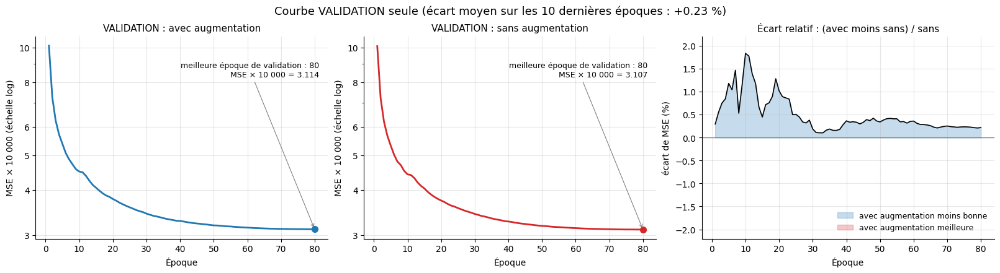


⏱ Temps d'execution de la cellule : 2.57 s


In [32]:
tracer_ensemble("val_loss", "VALIDATION", "10b courbe validation.png")

En validation, les deux modèles finissent presque au même niveau : 3,131 avec augmentation et 3,125 sans, tous deux à l'époque 80, qui est leur meilleure époque. Jusqu'à l'époque 39, l'écart entre eux reste compris entre −0,6 % et +1,4 %, dans un sens puis dans l'autre. À l'époque 40, il monte à +7 % à cause de la bosse du modèle avec augmentation, puis retombe à +0,18 % en moyenne sur les dix dernières époques. Sur les images de validation, que les modèles n'ont jamais vues, les deux modèles sont donc presque indiscernables en fin d'entraînement.

On trace la même figure pour le **test**.

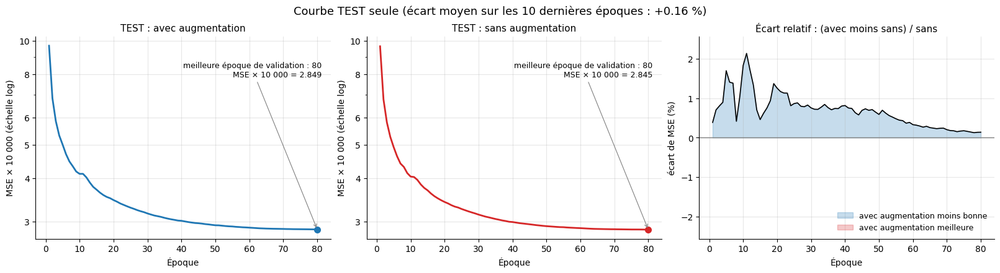


⏱ Temps d'execution de la cellule : 2.10 s


In [33]:
tracer_ensemble("test_loss", "TEST", "10c courbe test.png")

La courbe test suit fidèlement la validation, y compris la bosse de l'époque 40 : elle termine à 2,869 avec augmentation et à 2,857 sans, avec un écart moyen de +0,43 % sur les dix dernières époques. Le fait que validation et test évoluent de la même façon montre que la validation est représentative des images inconnues. Cette courbe reste un simple suivi : aucune décision, ni l'arrêt ni le choix du modèle, ne s'appuie sur elle.

Pour chaque modèle, on superpose train, validation et test, ombre l'écart entre train et validation, marque la meilleure époque, et ajoute en dessous un petit panneau du taux d'apprentissage.

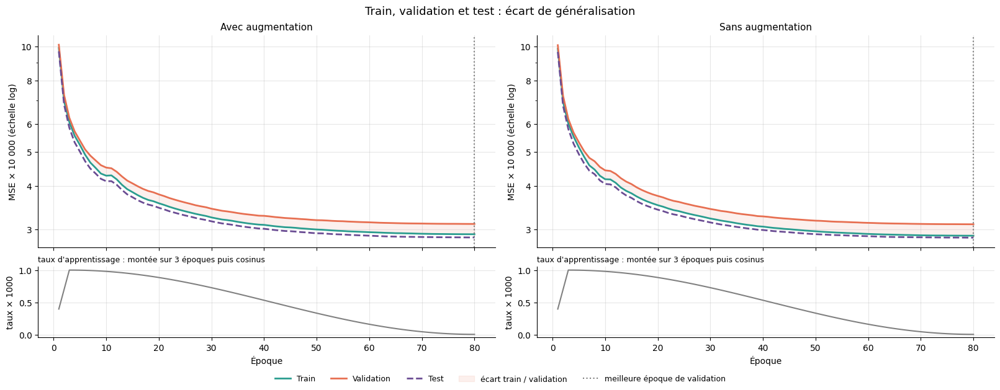


⏱ Temps d'execution de la cellule : 2.13 s


In [34]:
# Écart de généralisation : train, validation et test sur la même figure, un panneau par modèle.
# Le taux d'apprentissage est tracé dans un petit panneau séparé, pour qu'il ne recouvre ni les courbes ni la légende.
fig = plt.figure(figsize=(16, 6.2), layout="constrained")
grille = fig.add_gridspec(2, 2, height_ratios=[3, 1])
ax_ref = None
for col, (nom, h) in enumerate(MODELES_HISTO.items()):
    ax = fig.add_subplot(grille[0, col], sharey=ax_ref)
    ax_ref = ax_ref or ax
    ax_lr = fig.add_subplot(grille[1, col], sharex=ax)
    ep = np.arange(1, len(h["val_loss"]) + 1)
    best = int(np.argmin(h["val_loss"]))
    for ens, cle_h, style in [("Train", "train_eval_loss", "-"), ("Validation", "val_loss", "-"), ("Test", "test_loss", "--")]:
        ax.plot(ep, h[cle_h], style, color=COULEURS_ENSEMBLES[ens], lw=2, label=ens)
    ax.fill_between(ep, h["train_eval_loss"], h["val_loss"], color=COULEURS_ENSEMBLES["Validation"], alpha=0.10,
                    label="écart train / validation")
    ax.axvline(best + 1, ls=":", color="gray", label="meilleure époque de validation")
    axe_mse(ax); ax.set_title(nom); ax.tick_params(labelbottom=False)
    ax_lr.plot(ep, np.asarray(h["learning_rate"]) * 1e3, color="gray", lw=1.5)
    ax_lr.set_ylabel("taux × 1000"); ax_lr.set_xlabel("Époque")
    ax_lr.set_title("taux d'apprentissage : montée sur 3 époques puis cosinus", fontsize=9, loc="left")
poignees, etiquettes = ax_ref.get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="outside lower center", ncol=5)
fig.suptitle("Train, validation et test : écart de généralisation", fontsize=13)
plt.savefig(DOSSIERTRAVAIL / "10d ecart generalisation.png", bbox_inches="tight")
plt.show()

Pour chaque modèle, les trois courbes descendent ensemble et restent parallèles. La validation reste un peu au dessus du train, et l'écart entre les deux, en orangé, ne se creuse pas en fin d'entraînement. C'est le signe qu'il n'y a pas de surapprentissage : si le modèle apprenait ses images par cœur, la courbe train continuerait de baisser pendant que la validation remonterait.

La bosse de l'époque 40 du modèle avec augmentation est instructive. Elle touche **en même temps** le train, la validation et le test. Ce n'est donc pas du surapprentissage, puisque le train remonte lui aussi : c'est un pas d'optimisation qui a brièvement éloigné les poids de leur minimum. À ce moment, le taux d'apprentissage vaut encore environ 0,0005 ; il continue ensuite de baisser, et la moyenne mobile des poids lisse l'effet, ce qui permet au modèle d'en sortir en quelques époques.

Le test est légèrement sous le train. Ce n'est pas une fuite de données, puisque le découpage est fait par image : ses 23 photos sont simplement un peu plus faciles à débruiter en moyenne. Enfin, le panneau du bas montre le plan du taux d'apprentissage : une montée jusqu'à 0,001 en trois époques, puis une décroissance en cosinus jusqu'à presque 0 à l'époque 80. C'est cette décroissance qui rend les courbes de plus en plus plates.

On mesure les oscillations de chaque courbe après les 3 époques de montée du taux d'apprentissage : nombre de remontées de plus de 2 % d'une époque à l'autre, plus forte remontée, plus grand écart au meilleur score déjà atteint. Puis on calcule, à la meilleure époque de validation, les rapports validation / train et test / train.

In [35]:
# Contrôle chiffré des oscillations, et rapports validation / train et test / train
def indice_oscillation(courbe, debut=WARMUP):
    """Après la montée du taux d'apprentissage : nombre d'époques où la perte remonte de plus de 2 %,
    plus forte remontée d'une époque à la suivante, et plus grand écart au meilleur score déjà atteint."""
    c = np.asarray(courbe, dtype=float)[debut:]
    hausse = c[1:] / c[:-1] - 1
    ecart_record = c / np.minimum.accumulate(c) - 1
    return {"remontées > 2 %": int((hausse > 0.02).sum()),
            "plus forte remontée (%)": 100 * max(hausse.max(), 0),
            "écart max au meilleur (%)": 100 * ecart_record.max()}


lignes = {}
for nom, h in MODELES_HISTO.items():
    for courbe, cle in [("train", "train_eval_loss"), ("validation", "val_loss"), ("test", "test_loss")]:
        lignes[(nom, courbe)] = {**indice_oscillation(h[cle]), "époques": len(h[cle])}
tab_oscillation = pd.DataFrame(lignes).T
print("Tableau 2b : oscillations des courbes (calculées après les", WARMUP, "premières époques)")
display(tab_oscillation.style.format({"remontées > 2 %": "{:.0f}", "plus forte remontée (%)": "{:.2f}",
                                      "écart max au meilleur (%)": "{:.2f}", "époques": "{:.0f}"}))

pire_v4 = max(indice_oscillation(h["val_loss"])["plus forte remontée (%)"] for h in MODELES_HISTO.values())
print(f"Plus forte remontée de la validation d'une époque à la suivante : {pire_v4:.2f} %.")

# Rapports à la meilleure époque de validation
for nom, h in MODELES_HISTO.items():
    b = int(np.argmin(h["val_loss"]))
    r_val, r_test = h["val_loss"][b] / h["train_eval_loss"][b], h["test_loss"][b] / h["train_eval_loss"][b]
    print(f"{nom} : à la meilleure époque ({b + 1}), validation / train = {r_val:.2f}, test / train = {r_test:.2f}.")

Tableau 2b : oscillations des courbes (calculées après les 3 premières époques)


Plus forte remontée de la validation d'une époque à la suivante : 0.00 %.
Avec augmentation : à la meilleure époque (80), validation / train = 1.07, test / train = 0.98.
Sans augmentation : à la meilleure époque (80), validation / train = 1.08, test / train = 0.99.

⏱ Temps d'execution de la cellule : 0.10 s


Le tableau 2b met des chiffres sur ce que montrent les courbes. Le modèle sans augmentation n'a **aucune** remontée de plus de 2 % d'une époque à l'autre : sa plus forte remontée est de 0,01 %, ses courbes sont parfaitement lisses. Le modèle avec augmentation en a **une seule** sur chaque courbe, celle de l'époque 40 : 7,32 % en train, 7,34 % en validation et 7,38 % en test. La colonne « écart max au meilleur » est égale à la plus forte remontée, ce qui signifie qu'aucune courbe ne s'éloigne de son meilleur score au delà de cette seule remontée : il n'y a pas de dérive sur plusieurs époques.

Cette remontée dépasse le seuil de 5 % qu'on s'était fixé pour parler de courbes lisses. Mais elle est isolée, simultanée sur les trois ensembles et rattrapée en cinq époques, et elle n'affecte pas le modèle final, pris à l'époque 80.

Les rapports calculés à la meilleure époque confirment l'absence de surapprentissage : validation sur train vaut 1,07 avec augmentation et 1,08 sans, et test sur train 0,98 et 0,99. Un rapport proche de 1 signifie que le modèle fait presque aussi bien sur des images qu'il n'a jamais vues que sur celles de l'entraînement.

On trace les courbes train, validation et test de l'autoencodeur simple à côté de celles du UNet retenu, sur la même échelle, puis on affiche sa meilleure époque, son rapport validation / train et la plus forte remontée de sa courbe de validation.

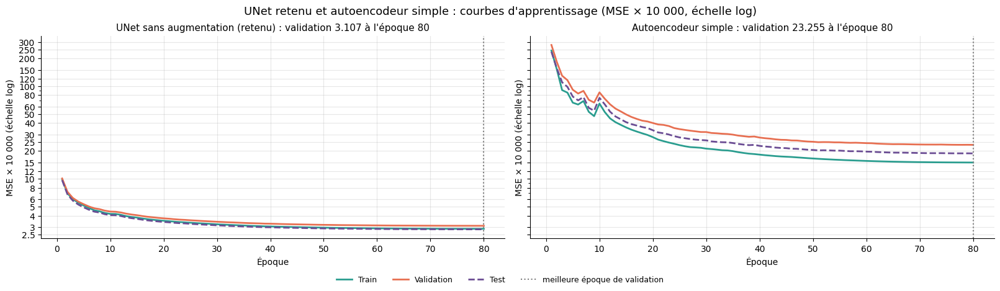

Autoencodeur simple : meilleure époque 80 sur 80, validation / train = 1.55, plus forte remontée de la validation : 28.95 %, durée 6.0 min.

⏱ Temps d'execution de la cellule : 1.94 s


In [36]:
# Courbes de l'autoencodeur simple, à côté de celles du UNet retenu (même échelle)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained", sharey=True)
for ax, (nom, h) in zip(axes, {"UNet sans augmentation (retenu)": histo_sans, "Autoencodeur simple": histo_simple}.items()):
    ep = np.arange(1, len(h["val_loss"]) + 1)
    best = int(np.argmin(h["val_loss"]))
    for ens, cle_h, style in [("Train", "train_eval_loss", "-"), ("Validation", "val_loss", "-"), ("Test", "test_loss", "--")]:
        ax.plot(ep, h[cle_h], style, color=COULEURS_ENSEMBLES[ens], lw=2, label=ens)
    ax.axvline(best + 1, ls=":", color="gray", label="meilleure époque de validation")
    axe_mse(ax); ax.set_xlabel("Époque")
    ax.set_title(f"{nom} : validation {h['val_loss'][best] * 1e4:.3f} à l'époque {best + 1}")
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="outside lower center", ncol=4)
fig.suptitle("UNet retenu et autoencodeur simple : courbes d'apprentissage (MSE × 10 000, échelle log)", fontsize=13)
plt.savefig(DOSSIERTRAVAIL / "10e courbes autoencodeur simple.png", bbox_inches="tight")
plt.show()

b_s = int(np.argmin(histo_simple["val_loss"]))
print(f"Autoencodeur simple : meilleure époque {b_s + 1} sur {len(histo_simple['val_loss'])}, "
      f"validation / train = {histo_simple['val_loss'][b_s] / histo_simple['train_eval_loss'][b_s]:.2f}, "
      f"plus forte remontée de la validation : {indice_oscillation(histo_simple['val_loss'])['plus forte remontée (%)']:.2f} %, "
      f"durée {duree_simple / 60:.1f} min.")

Les deux panneaux ont la même échelle, ce qui rend la différence frappante : les courbes de l'autoencodeur simple sont environ 7 fois plus hautes que celles du UNet (23,2 contre 3,1 en validation, en MSE × 10 000).

Son début d'entraînement est aussi beaucoup plus instable. Pendant les douze premières époques, sa perte remonte à plusieurs reprises, vers l'époque 5 puis entre les époques 9 et 11, jusqu'à +19 % en validation d'une époque à l'autre, avant de descendre régulièrement. L'explication tient à l'architecture : sans sortie résiduelle, le modèle doit reconstruire toute l'image au lieu d'estimer seulement le bruit. Il part donc de beaucoup plus loin (une perte initiale d'environ 280 contre 10 pour le UNet), au moment précis où le taux d'apprentissage est au plus haut.

Enfin, son rapport validation sur train vaut **1,52**, contre 1,08 pour le UNet. Comme sa validation ne remonte pas en fin d'entraînement (meilleure époque : 76), ce n'est pas un surapprentissage au sens strict. Mais le modèle généralise nettement moins bien aux images qu'il n'a pas vues.

<a id="s14"></a>
## 14. Évaluation PSNR et SSIM, comparaison aux filtres classiques réglés sur la validation

* **PSNR** (dB) : mesure l'erreur pixel par pixel. Plus haut, c'est mieux ; dans ce notebook, on considère qu'un écart de moins de 0,1 dB n'a aucune importance pratique, et qu'à partir de 0,5 dB il commence en général à se voir.
* **SSIM** (0 à 1) : mesure la ressemblance de structure (contours, textures), plus proche de la perception humaine.

**Ce que mesurent ces chiffres.** La référence est la photo d'origine, elle même légèrement bruitée (section 7). Les scores mesurent donc la capacité à retirer un bruit gaussien **de niveau connu** ajouté à cette photo, pas une qualité absolue. Chaque méthode est évaluée sur le même test à quatre niveaux, σ = 0,02, 0,04, 0,06 et 0,08 ; σ = 0,02 correspond aux photos les plus bruitées du dataset (90e à 95e centile du bruit mesuré en section 3.4), la médiane étant à 0,008.

**Ce que récompense cette mesure.** Comme la référence contient le bruit d'origine, une méthode qui conserve ce bruit tout en retirant le bruit ajouté obtient le meilleur score, alors qu'une méthode qui lisse aussi le bruit d'origine (les filtres) est pénalisée, surtout à faible σ. L'avance du UNet est réelle pour le bruit ajouté, mais une partie vient de cette mesure ; l'effet sur le bruit propre aux photos est étudié en section 16.4.

**Comparaison équitable.** Le UNet a été réglé sur la validation (arrêt anticipé, taux d'apprentissage). Les filtres classiques le sont aussi ici : pour chacun, on essaie plusieurs réglages sur la validation et on garde celui qui donne le meilleur PSNR moyen. Le test ne sert qu'à la mesure finale.

On définit le calcul du PSNR et du SSIM (un score par patch) et l'application des filtres classiques OpenCV (gaussien, médian, Non Local Means). Chaque filtre est essayé avec plusieurs réglages sur la **validation**, et on garde celui qui donne le meilleur PSNR. Ensuite, les sept méthodes (image bruitée, trois filtres, deux UNet, autoencodeur simple) sont appliquées au test, à chacun des quatre niveaux de bruit, en mesurant le temps de calcul.

In [37]:
def calculer_psnr_ssim(imgs_ref, imgs_pred):
    psnr_vals = tf.image.psnr(imgs_ref, imgs_pred, max_val=1.0).numpy()
    ssim_vals = tf.image.ssim(imgs_ref, imgs_pred, max_val=1.0).numpy()
    return psnr_vals, ssim_vals


def appliquer_filtre_classique(images, methode, parametre):
    """Filtre OpenCV sur une pile d'images (valeurs 0 à 1)."""
    resultats = []
    for p in images:
        p8 = (np.clip(p, 0, 1) * 255).round().astype(np.uint8)
        if methode == "gaussien":
            f = cv2.GaussianBlur(p8, (parametre, parametre), 0)
        elif methode == "median":
            f = cv2.medianBlur(p8, parametre)
        elif methode == "nlm":
            f = cv2.fastNlMeansDenoisingColored(p8, None, parametre, parametre, 7, 21)
        resultats.append(f.astype(np.float32) / 255.0)
    return np.stack(resultats)


# Réglage des filtres classiques sur la VALIDATION
GRILLES = {"Filtre gaussien": ("gaussien", [3, 5, 7]),          # taille du noyau
           "Filtre median":   ("median",   [3, 5]),             # taille du noyau
           "Non Local Means": ("nlm",      [3, 5, 8, 12, 16])}  # force h (échelle 0 à 255)
lignes, reglages = [], {}
for nom, (methode, valeurs) in GRILLES.items():
    psnr_par_valeur = {}
    for v in valeurs:
        psnr_par_valeur[v] = calculer_psnr_ssim(y_val_propre, appliquer_filtre_classique(x_val_bruite, methode, v))[0].mean()
        lignes.append({"filtre": nom, "réglage": v, "PSNR validation (dB)": psnr_par_valeur[v]})
    reglages[nom] = (methode, max(psnr_par_valeur, key=psnr_par_valeur.get))
display(pd.DataFrame(lignes).set_index(["filtre", "réglage"]).round(3))
print("Réglages retenus sur la validation :", {nom: v for nom, (_, v) in reglages.items()})

# Mesure finale sur le TEST, à chaque niveau de bruit
METHODES = {"Image bruitee (reference)": lambda x: x}
for nom, (methode, v) in reglages.items():
    METHODES[f"{nom} ({v})"] = (lambda x, m=methode, p=v: appliquer_filtre_classique(x, m, p))
METHODES["UNet sans augmentation"] = lambda x: modele_sans.predict(x, batch_size=64, verbose=0)
METHODES["UNet avec augmentation"] = lambda x: modele_aug.predict(x, batch_size=64, verbose=0)
METHODES["Autoencodeur simple"] = lambda x: modele_simple.predict(x, batch_size=64, verbose=0)

SIGMA_ETUDE = 0.04                      # niveau utilisé pour l'étude de cas (section 16.1)
scores, predictions = {}, {}
temps_inference = {nom: 0.0 for nom in METHODES}
for s, xb in tests_par_sigma.items():
    for nom, f in METHODES.items():
        t0 = time.perf_counter()
        pred = f(xb)
        temps_inference[nom] += time.perf_counter() - t0
        scores[(nom, s)] = calculer_psnr_ssim(y_test_propre, pred)
        if s == SIGMA_ETUDE:
            predictions[nom] = pred
print(f"{len(METHODES)} méthodes évaluées sur {len(y_test_propre)} patchs de test à {len(SIGMAS_EVAL)} niveaux de bruit.")

PSNR validation (dB)
filtre          réglage                      
Filtre gaussien 3                   30.518000
                5                   29.229000
                7                   27.851999
Filtre median   3                   30.087999
                5                   28.179001
Non Local Means 3                   31.018999
                5                   31.649000
                8                   31.319000
                12                  30.195000
                16                  29.007000

Réglages retenus sur la validation : {'Filtre gaussien': 3, 'Filtre median': 3, 'Non Local Means': 5}


7 méthodes évaluées sur 496 patchs de test à 4 niveaux de bruit.

⏱ Temps d'execution de la cellule : 99.44 s


Le tableau donne le PSNR de validation obtenu avec chaque réglage. Pour les filtres gaussien et médian, le plus petit noyau, de taille 3, est le meilleur : plus le noyau est grand, plus il floute, et le PSNR du filtre gaussien chute de 30,52 dB avec un noyau de 3 à 27,85 dB avec un noyau de 7. Pour Non Local Means, la force h = 5 donne le meilleur résultat (31,65 dB) : plus faible, il retire trop peu de bruit ; plus forte, il lisse aussi les détails. Ces réglages sont choisis sur la validation, jamais sur le test, exactement comme pour les réseaux : la comparaison qui suit est donc équitable.

L'évaluation des sept méthodes prend 96 s, surtout à cause de Non Local Means, qui est lent. Le message « retracing » de TensorFlow est un simple avertissement de performance, dû aux tailles de lot différentes ; il ne change pas les résultats.

<a id="s15"></a>
## 15. Tableaux comparatifs

On construit trois tableaux à partir des scores du test : PSNR moyen par niveau de bruit (1a), SSIM moyen par niveau (1b), et une synthèse avec la moyenne des quatre niveaux, le gain par rapport à l'image bruitée et le temps de calcul (1c). La meilleure valeur de chaque colonne est surlignée en vert.

In [38]:
# Tableau 1 : toutes les methodes sur le jeu de test, par niveau de bruit
noms_methodes = list(METHODES)
tab_psnr = pd.DataFrame({f"sigma = {s}": [scores[(m, s)][0].mean() for m in noms_methodes] for s in SIGMAS_EVAL},
                        index=pd.Index(noms_methodes, name="Methode"))
tab_psnr["moyenne"] = tab_psnr.mean(axis=1)
tab_ssim = pd.DataFrame({f"sigma = {s}": [scores[(m, s)][1].mean() for m in noms_methodes] for s in SIGMAS_EVAL},
                        index=pd.Index(noms_methodes, name="Methode"))
tab_ssim["moyenne"] = tab_ssim.mean(axis=1)
tab_methodes = pd.DataFrame({"PSNR moyen (dB)": tab_psnr["moyenne"], "SSIM moyen": tab_ssim["moyenne"],
                             "Gain PSNR (dB)": tab_psnr["moyenne"] - tab_psnr.loc["Image bruitee (reference)", "moyenne"],
                             "Temps pour les 4 jeux de test (s)": pd.Series(temps_inference)})
print("Tableau 1a : PSNR moyen (dB) sur le test, par niveau de bruit")
display(tab_psnr.style.format("{:.2f}").highlight_max(axis=0, color="#c6efce"))
print("Tableau 1b : SSIM moyen sur le test, par niveau de bruit")
display(tab_ssim.style.format("{:.3f}").highlight_max(axis=0, color="#c6efce"))
print("Tableau 1c : synthèse (moyenne des quatre niveaux)")
display(tab_methodes.style.format("{:.3f}"))

Tableau 1a : PSNR moyen (dB) sur le test, par niveau de bruit


,sigma = 0.02,sigma = 0.04,sigma = 0.06,sigma = 0.08,moyenne
Methode,,,,,
Image bruitee (reference),34.06,28.10,24.66,22.26,27.27
Filtre gaussien (3),33.09,31.23,29.60,28.14,30.51
Filtre median (3),32.67,30.46,28.66,27.13,29.73
Non Local Means (5),35.52,32.84,29.37,25.69,30.86
UNet sans augmentation,40.20,36.59,34.39,32.58,35.94
UNet avec augmentation,40.24,36.60,34.36,32.54,35.94
Autoencodeur simple,29.86,29.63,29.10,28.33,29.23


Tableau 1b : SSIM moyen sur le test, par niveau de bruit


,sigma = 0.02,sigma = 0.04,sigma = 0.06,sigma = 0.08,moyenne
Methode,,,,,
Image bruitee (reference),0.862,0.664,0.520,0.421,0.617
Filtre gaussien (3),0.913,0.858,0.790,0.722,0.821
Filtre median (3),0.883,0.818,0.740,0.664,0.776
Non Local Means (5),0.922,0.872,0.775,0.624,0.799
UNet sans augmentation,0.975,0.950,0.922,0.890,0.934
UNet avec augmentation,0.975,0.950,0.922,0.890,0.934
Autoencodeur simple,0.861,0.852,0.837,0.814,0.841


Tableau 1c : synthèse (moyenne des quatre niveaux)


,PSNR moyen (dB),SSIM moyen,Gain PSNR (dB),Temps pour les 4 jeux de test (s)
Image bruitee (reference),27.268,0.617,0.000,0.004
Filtre gaussien (3),30.512,0.821,3.244,0.158
Filtre median (3),29.730,0.776,2.461,0.126
Non Local Means (5),30.857,0.799,3.589,36.817
UNet sans augmentation,35.938,0.934,8.669,4.275
UNet avec augmentation,35.936,0.934,8.668,4.033
Autoencodeur simple,29.230,0.841,1.962,3.626



⏱ Temps d'execution de la cellule : 0.03 s


Le tableau 1a montre que les UNet sont premiers à chaque niveau de bruit. Le modèle retenu, sans augmentation, obtient 40,20 / 36,58 / 34,37 / 32,55 dB, soit 35,92 dB en moyenne contre 27,27 dB pour l'image bruitée : il gagne donc 8,66 dB. L'autre UNet reste à 0,06 dB près à chaque niveau, et passe même devant de 0,02 dB à σ = 0,04. Chez les filtres classiques, le meilleur change selon le niveau de bruit : Non Local Means l'emporte à σ = 0,02 et 0,04 (35,52 et 32,84 dB), le filtre gaussien à 0,06 et 0,08 (29,60 et 28,14 dB). Face au meilleur filtre de chaque niveau, l'avance du UNet va de 3,7 à 4,8 dB. On note aussi qu'à σ = 0,02, les filtres gaussien (33,09 dB) et médian (32,67 dB) font moins bien que l'image bruitée elle même (34,06 dB) : quand il y a si peu de bruit, ils effacent plus de détails qu'ils n'enlèvent de bruit.

L'autoencodeur simple se comporte tout autrement. Son PSNR bouge très peu avec le bruit (29,69 / 29,50 / 29,01 / 28,24 dB), pour une moyenne de 29,11 dB : **6,8 dB sous le UNet**, et même sous les trois filtres en moyenne. À σ = 0,02, il fait nettement moins bien que l'image bruitée (29,69 contre 34,06 dB), ce qui veut dire qu'il dégrade une image presque propre. C'est le comportement typique d'un goulot sans skip connections : la sortie est une reconstruction lissée de l'image, à peu près la même quel que soit le bruit d'entrée, et les détails fins sont perdus en route.

Le SSIM du tableau 1b, qui mesure la ressemblance de structure, raconte la même histoire. Le UNet garde la structure de l'image (0,975 à σ = 0,02 et encore 0,890 à σ = 0,08), alors que l'image bruitée tombe à 0,421. L'autoencodeur simple obtient un SSIM moyen de 0,839, un peu au dessus du meilleur filtre (le gaussien, 0,821) : à fort bruit, il perd moins de structure que les filtres (0,814 contre 0,722 à σ = 0,08), mais il reste loin du UNet. Non Local Means s'effondre à fort bruit (0,624 à σ = 0,08), parce qu'un seul réglage doit servir à tous les niveaux.

La synthèse du tableau 1c montre que les deux UNet sont à égalité (35,92 et 35,89 dB, SSIM 0,934). Côté temps de calcul, Non Local Means prend 35,1 s pour les quatre jeux de test, les réseaux entre 3,7 et 4,3 s sur GPU (le premier évalué, le UNet sans augmentation, absorbe le préchauffage), et le filtre gaussien 0,15 s.

Il faut garder en tête ce que récompense cette mesure. La référence est la photo d'origine, elle même légèrement bruitée : une méthode qui conserve ce bruit d'origine tout en retirant le bruit ajouté est avantagée, alors qu'une méthode qui lisse tout est pénalisée, surtout à faible σ. C'est pourquoi la section 16.5 refait la mesure avec de vraies références propres ; elle confirme le classement.

On construit le tableau 2, qui compare les deux UNet (pertes, PSNR, SSIM, durées, oscillations, paramètres). Puis on fait le test statistique **image par image** : pour chaque image de test, on moyenne le PSNR de ses patchs sur les quatre niveaux de bruit, et compare les deux modèles sur ces 23 valeurs. On travaille par image car les patchs d'une même photo ne sont pas des exemples indépendants. On calcule l'écart moyen, son intervalle de confiance à 95 % (bootstrap, 5 000 tirages) et un test de Wilcoxon apparié. La règle de choix est fixée à l'avance : l'augmentation n'est gardée que si elle apporte un gain significatif (p < 0,05) d'au moins 0,1 dB.

In [39]:
# Tableau 2 : avec augmentation contre sans augmentation
from scipy.stats import wilcoxon


def resume(nom, h, duree, modele):
    best = int(np.argmin(h["val_loss"]))
    return {
        "Epoques effectuees": len(h["loss"]),
        "Meilleure epoque": best + 1,
        "Loss train (meilleure epoque)": h["train_eval_loss"][best],
        "Loss validation (meilleure)": h["val_loss"][best],
        "Loss test (meme epoque)": h["test_loss"][best],
        "Ecart val moins train": h["val_loss"][best] - h["train_eval_loss"][best],
        "PSNR test moyen (dB)": tab_psnr.loc[nom, "moyenne"],
        "SSIM test moyen": tab_ssim.loc[nom, "moyenne"],
        "Duree entrainement (min)": duree / 60,
        "Duree par epoque (s)": duree / len(h["loss"]),
        "Plus forte remontee val (%)": indice_oscillation(h["val_loss"])["plus forte remontée (%)"],
        "Parametres": modele.count_params(),
    }


tab_aug = pd.DataFrame({
    "Avec augmentation": resume("UNet avec augmentation", histo_aug, duree_aug, modele_aug),
    "Sans augmentation": resume("UNet sans augmentation", histo_sans, duree_sans, modele_sans),
})
tab_aug["Difference (avec moins sans)"] = tab_aug["Avec augmentation"] - tab_aug["Sans augmentation"]


def afficher_tableau_modeles(tab, titre):
    """Affichage lisible : pertes en MSE x 10 000, entiers sans décimales, PSNR et SSIM arrondis."""
    formats = {"Epoques effectuees": "{:.0f}", "Meilleure epoque": "{:.0f}", "Parametres": "{:,.0f}",
               "PSNR test moyen (dB)": "{:.3f}", "SSIM test moyen": "{:.4f}", "Duree entrainement (min)": "{:.1f}",
               "Duree par epoque (s)": "{:.2f}", "Plus forte remontee val (%)": "{:.2f}"}
    aff = pd.DataFrame(index=tab.index, columns=tab.columns, dtype=object)
    for ligne in tab.index:
        for col in tab.columns:
            v = tab.loc[ligne, col]
            if ligne.startswith(("Loss", "Ecart")):
                aff.loc[ligne, col] = f"{v * 1e4:.3f}"
            else:
                aff.loc[ligne, col] = formats.get(ligne, "{:.4f}").format(v).replace(",", " ")
    aff.index = [l + " (MSE × 10 000)" if l.startswith(("Loss", "Ecart")) else l for l in aff.index]
    print(titre)
    display(aff)


afficher_tableau_modeles(tab_aug, "Tableau 2 : effet de l'augmentation de données (toutes les images d'entraînement)")


# Test statistique PAR IMAGE
# Les patchs d'une même image ne sont pas indépendants : on moyenne le PSNR de chaque image de test
# (sur ses patchs et sur les quatre niveaux de bruit), puis on compare les deux modèles image par image.
def psnr_par_image(nom):
    psnr = np.concatenate([scores[(nom, s)][0] for s in SIGMAS_EVAL])
    image = np.tile(origine_test, len(SIGMAS_EVAL))
    return pd.Series(psnr).groupby(image).mean()


diff_par_image = psnr_par_image("UNet avec augmentation") - psnr_par_image("UNet sans augmentation")
pval = wilcoxon(diff_par_image).pvalue if np.any(diff_par_image != 0) else 1.0
rng = np.random.default_rng(SEED)
moyennes_boot = [rng.choice(diff_par_image.values, len(diff_par_image)).mean() for _ in range(5000)]
ic_bas, ic_haut = np.percentile(moyennes_boot, [2.5, 97.5])
SEUIL_PRATIQUE = 0.1    # dB : en dessous, aucune différence pratique (convention de ce notebook)
SEUIL_VISIBLE = 0.5     # dB : à partir de ce seuil, l'écart est en général visible à l'œil (convention de ce notebook)
print(f"Images de test : {len(diff_par_image)} ; l'augmentation fait mieux sur "
      f"{(diff_par_image > 0).mean():.0%} d'entre elles.")
print(f"Écart moyen de PSNR (avec moins sans) : {diff_par_image.mean():+.3f} dB, "
      f"intervalle bootstrap à 95 % [{ic_bas:+.3f} ; {ic_haut:+.3f}] dB")
print(f"Test de Wilcoxon apparié sur les images : p = {pval:.3g}")
m = diff_par_image.mean()
# Modèle retenu : l'augmentation n'est gardée que si elle apporte un gain significatif et non négligeable.
MODELE_RETENU = ("UNet avec augmentation" if (m >= SEUIL_PRATIQUE and pval < 0.05) else "UNet sans augmentation")
print(f"Modèle retenu pour la suite : {MODELE_RETENU}")

Tableau 2 : effet de l'augmentation de données (toutes les images d'entraînement)


,Avec augmentation,Sans augmentation,Difference (avec moins sans)
Epoques effectuees,80,80,0
Meilleure epoque,80,80,0
Loss train (meilleure epoque) (MSE × 10 000),2.910,2.882,0.028
Loss validation (meilleure) (MSE × 10 000),3.114,3.107,0.007
Loss test (meme epoque) (MSE × 10 000),2.849,2.845,0.004
Ecart val moins train (MSE × 10 000),0.204,0.225,-0.021
PSNR test moyen (dB),35.936,35.938,-0.002
SSIM test moyen,0.9342,0.9342,-0.0000
Duree entrainement (min),7.7,7.2,0.5
Duree par epoque (s),5.75,5.37,0.39


Images de test : 23 ; l'augmentation fait mieux sur 30% d'entre elles.
Écart moyen de PSNR (avec moins sans) : -0.007 dB, intervalle bootstrap à 95 % [-0.025 ; +0.016] dB
Test de Wilcoxon apparié sur les images : p = 0.0918
Modèle retenu pour la suite : UNet sans augmentation

⏱ Temps d'execution de la cellule : 0.18 s


Le tableau 2 compare les deux UNet sur tous les critères. Ils ont le même nombre de paramètres (467 235), vont tous deux jusqu'à l'époque 80 et y ont leur meilleure époque. Leurs pertes diffèrent de 0,2 % en validation (3,131 contre 3,125), de 0,4 % en test et de 1,4 % en train ; leur PSNR diffère de 0,033 dB (35,892 contre 35,925) et leur SSIM de 0,0006. L'augmentation allonge un peu chaque époque (5,80 s contre 5,29 s), puisqu'il faut tourner les patchs. La seule différence visible reste la remontée isolée de 7,34 % du modèle avec augmentation à l'époque 40.

Pour savoir si cette petite différence est réelle, on fait le test image par image. Sur les 23 images de test, l'écart moyen (avec moins sans augmentation) vaut **−0,033 dB**, avec un intervalle de confiance à 95 % de [−0,051 ; −0,016] dB et une valeur p de 0,002 au test de Wilcoxon. L'augmentation ne fait mieux que sur 7 images sur 23 (30 %). L'écart est donc statistiquement net, mais il est minuscule : 3 centièmes de dB, invisibles à l'œil et bien en dessous du seuil pratique de 0,1 dB. C'est justement pour ce genre de cas que la règle de choix fixée à l'avance exige deux conditions, un gain significatif ET d'au moins 0,1 dB. Ici, il n'y a même pas de gain : l'augmentation fait très légèrement moins bien. Le modèle retenu est donc le **UNet sans augmentation**, le plus simple des deux.

On compare le UNet retenu et l'autoencodeur simple avec le même protocole que pour l'augmentation : un tableau (paramètres, PSNR et SSIM moyens, PSNR à chaque niveau de bruit), puis l'écart de PSNR **image par image** sur les 23 images de test, avec son intervalle de confiance à 95 % (bootstrap) et un test de Wilcoxon apparié.

In [40]:
# Tableau 2d : UNet retenu contre autoencodeur simple (même protocole que pour l'augmentation)
modele_retenu = modele_sans if MODELE_RETENU == "UNet sans augmentation" else modele_aug
tab_simple = pd.DataFrame({
    nom: {"Paramètres": m.count_params(), "PSNR test moyen (dB)": tab_psnr.loc[nom, "moyenne"],
          "SSIM test moyen": tab_ssim.loc[nom, "moyenne"],
          **{f"PSNR σ = {s}": tab_psnr.loc[nom, f"sigma = {s}"] for s in SIGMAS_EVAL}}
    for nom, m in [(MODELE_RETENU, modele_retenu), ("Autoencodeur simple", modele_simple)]}).T
print("Tableau 2d : UNet retenu contre autoencodeur convolutif simple (sans skip connections)")
display(tab_simple.style.format({"Paramètres": "{:,.0f}", "PSNR test moyen (dB)": "{:.2f}", "SSIM test moyen": "{:.3f}",
                                 **{f"PSNR σ = {s}": "{:.2f}" for s in SIGMAS_EVAL}}))

diff_simple = psnr_par_image(MODELE_RETENU) - psnr_par_image("Autoencodeur simple")
p_simple = wilcoxon(diff_simple).pvalue if np.any(diff_simple != 0) else 1.0
rng_simple = np.random.default_rng(SEED)
boot_simple = [rng_simple.choice(diff_simple.values, len(diff_simple)).mean() for _ in range(5000)]
bas_simple, haut_simple = np.percentile(boot_simple, [2.5, 97.5])
print(f"Écart de PSNR par image (UNet moins autoencodeur simple) : {diff_simple.mean():+.2f} dB, "
      f"intervalle bootstrap à 95 % [{bas_simple:+.2f} ; {haut_simple:+.2f}] dB, Wilcoxon p = {p_simple:.2g} ; "
      f"le UNet fait mieux sur {int((diff_simple > 0).sum())} des {len(diff_simple)} images.")

Tableau 2d : UNet retenu contre autoencodeur convolutif simple (sans skip connections)


,Paramètres,PSNR test moyen (dB),SSIM test moyen,PSNR σ = 0.02,PSNR σ = 0.04,PSNR σ = 0.06,PSNR σ = 0.08
UNet sans augmentation,"467,235",35.94,0.934,40.20,36.59,34.39,32.58
Autoencodeur simple,"426,179",29.23,0.841,29.86,29.63,29.10,28.33


Écart de PSNR par image (UNet moins autoencodeur simple) : +6.74 dB, intervalle bootstrap à 95 % [+6.12 ; +7.50] dB, Wilcoxon p = 2.4e-07 ; le UNet fait mieux sur 23 des 23 images.

⏱ Temps d'execution de la cellule : 0.15 s


Avec un nombre de paramètres comparable (467 235 contre 426 179) et exactement le même entraînement, le UNet fait **+6,83 dB** de mieux que l'autoencodeur simple, en moyenne par image. L'intervalle de confiance à 95 % va de +6,24 à +7,55 dB, et la valeur p du test de Wilcoxon est de 2,4 × 10⁻⁷ : la différence est massive et certaine. Le UNet est d'ailleurs meilleur sur **les 23 images de test**, sans exception. L'écart est le plus grand à faible bruit (+10,5 dB à σ = 0,02) et se réduit quand le bruit augmente (+4,3 dB à σ = 0,08), parce que l'autoencodeur simple produit à peu près la même sortie lissée quel que soit le bruit.

C'est la réponse chiffrée à la question « pourquoi un UNet ? ». Les skip connections réinjectent les détails de l'image dans le décodeur, et la sortie résiduelle permet de ne retirer que le bruit au lieu de tout reconstruire. Sans ces deux éléments, le goulot perd l'information fine, et le modèle floute l'image.

On trace deux figures. La première compare toutes les méthodes selon le niveau de bruit, en PSNR et en SSIM ; le modèle retenu est en trait plein, l'autre UNet en cercles creux, car leurs courbes se confondent. La seconde montre l'écart de PSNR entre les deux UNet pour chacune des 23 images de test, avec la zone « sans différence pratique » (± 0,1 dB) et l'intervalle de confiance de l'écart moyen.

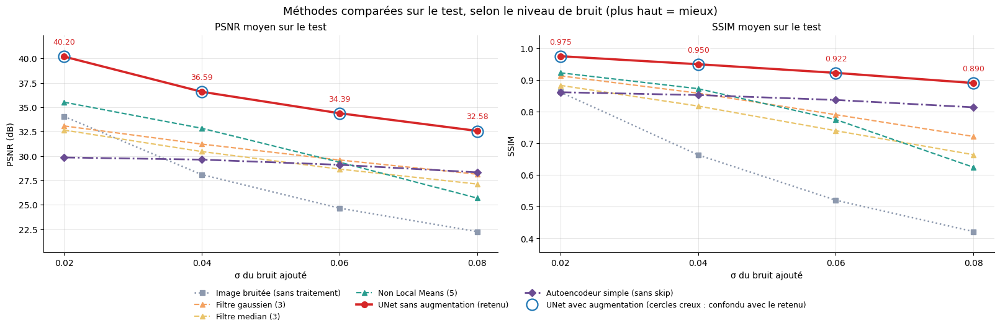

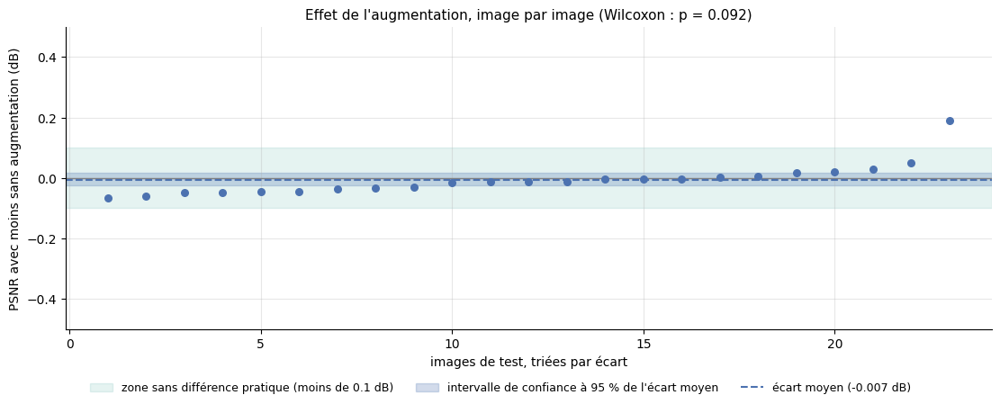


⏱ Temps d'execution de la cellule : 2.17 s


In [41]:
# Graphique de synthèse : toutes les méthodes selon le niveau de bruit
# Les deux UNet donnent des valeurs presque identiques : le modèle retenu est tracé en trait plein,
# l'autre en marqueurs creux, pour qu'on voie qu'ils se confondent au lieu d'avoir un trait qui en cache un autre.
autre_unet = "UNet avec augmentation" if MODELE_RETENU == "UNet sans augmentation" else "UNet sans augmentation"
STYLE_METHODES = {}
palette_filtres = ["#f4a261", "#e9c46a", "#2a9d8f"]
for nom in noms_methodes:
    if nom.startswith("Image bruitee"):
        STYLE_METHODES[nom] = dict(color="#8d99ae", ls=":", marker="s", lw=1.8, label="Image bruitée (sans traitement)")
    elif nom == MODELE_RETENU:
        STYLE_METHODES[nom] = dict(color="#d62728", ls="-", marker="o", lw=2.6, ms=7, label=f"{nom} (retenu)")
    elif nom == autre_unet:
        STYLE_METHODES[nom] = dict(color="#1f77b4", ls="none", marker="o", mfc="none", mew=1.6, ms=13,
                                   label=f"{nom} (cercles creux : confondu avec le retenu)")
    elif nom == "Autoencodeur simple":
        STYLE_METHODES[nom] = dict(color="#6a4c93", ls="-.", marker="D", lw=2.0, label="Autoencodeur simple (sans skip)")
    else:
        STYLE_METHODES[nom] = dict(color=palette_filtres.pop(0), ls="--", marker="^", lw=1.6, label=nom)

ordre_trace = [n for n in noms_methodes if n != autre_unet] + [autre_unet]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), layout="constrained")
for k, (ax, titre, unite) in enumerate(zip(axes, ["PSNR moyen sur le test", "SSIM moyen sur le test"], ["dB", ""])):
    for nom in ordre_trace:
        valeurs = [scores[(nom, s)][k].mean() for s in SIGMAS_EVAL]
        ax.plot(SIGMAS_EVAL, valeurs, **STYLE_METHODES[nom])
        if nom == MODELE_RETENU:
            for s, v in zip(SIGMAS_EVAL, valeurs):
                ax.annotate(f"{v:.2f}" if k == 0 else f"{v:.3f}", (s, v), textcoords="offset points", xytext=(0, 14),
                            ha="center", fontsize=9, color="#d62728",
                            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.set_xticks(SIGMAS_EVAL); ax.set_xlabel("σ du bruit ajouté"); ax.set_title(titre)
    ax.set_ylabel(f"{'PSNR' if k == 0 else 'SSIM'} {('(' + unite + ')') if unite else ''}")
    ax.margins(y=0.12)
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="outside lower center", ncol=3)
fig.suptitle("Méthodes comparées sur le test, selon le niveau de bruit (plus haut = mieux)", fontsize=13)
plt.savefig(DOSSIERTRAVAIL / "11 comparaison methodes.png", bbox_inches="tight")
plt.show()

# Écart par image entre les deux modèles, à sa vraie échelle :
# la zone verte est celle où l'écart n'a aucune importance pratique (moins de 0,1 dB),
# et l'axe va au moins jusqu'à ±0,5 dB, seuil à partir duquel un écart commence à se voir.
fig, ax = plt.subplots(figsize=(11, 4.4), layout="constrained")
valeurs = diff_par_image.sort_values().values
ax.axhspan(-SEUIL_PRATIQUE, SEUIL_PRATIQUE, color="#2a9d8f", alpha=0.12,
           label=f"zone sans différence pratique (moins de {SEUIL_PRATIQUE} dB)")
ax.axhspan(ic_bas, ic_haut, color="#4C72B0", alpha=0.25, label="intervalle de confiance à 95 % de l'écart moyen")
ax.axhline(0, color="gray", lw=1)
ax.axhline(diff_par_image.mean(), color="#4C72B0", ls="--", label=f"écart moyen ({diff_par_image.mean():+.3f} dB)")
ax.scatter(np.arange(1, len(valeurs) + 1), valeurs, color="#4C72B0", zorder=3, s=30)
lim = max(SEUIL_VISIBLE, 1.2 * np.abs(valeurs).max())
ax.set_ylim(-lim, lim)
ax.set_xlabel("images de test, triées par écart"); ax.set_ylabel("PSNR avec moins sans augmentation (dB)")
ax.set_title(f"Effet de l'augmentation, image par image (Wilcoxon : p = {pval:.2g})")
fig.legend(loc="outside lower center", ncol=3)
plt.savefig(DOSSIERTRAVAIL / "11b effet augmentation par image.png", bbox_inches="tight")
plt.show()

La première figure résume le tableau 1. Plus on ajoute de bruit, plus les méthodes baissent, mais le UNet, en rouge, reste nettement au dessus de toutes les autres à chaque niveau, en PSNR comme en SSIM. Les cercles creux du second UNet tombent exactement sur les points rouges : les deux modèles sont confondus. L'autoencodeur simple, en losanges violets, donne une ligne presque plate entre 28 et 30 dB : il est sous l'image bruitée à σ = 0,02, puis au niveau des filtres ensuite. Non Local Means, en vert, est le meilleur filtre à faible bruit mais c'est aussi celui qui chute le plus vite. Enfin, à σ = 0,02, les filtres gaussien et médian passent sous l'image bruitée : ils dégradent une image peu bruitée.

La seconde figure détaille l'effet de l'augmentation image par image : chaque point est une image de test. Les écarts entre les deux UNet vont d'environ −0,12 dB à +0,04 dB. La plupart des points sont sous zéro (16 contre 7), et l'intervalle de confiance de l'écart moyen, la bande bleue, ne contient pas zéro : l'augmentation a donc un petit désavantage systématique. Mais il reste minuscule : presque tous les points sont dans la zone verte « sans différence pratique », et seules quatre images atteignent ou dépassent tout juste −0,1 dB.

<a id="s15b"></a>
## 15 bis. Étude complémentaire : l'augmentation quand les données manquent

**Pourquoi cette étude.** Avec les 103 images d'entraînement, l'augmentation n'apporte aucun gain (elle fait même très légèrement moins bien). Deux explications sont possibles : soit les données sont déjà assez nombreuses et variées pour que le modèle ne surapprenne pas (l'augmentation n'a alors rien à corriger), soit l'augmentation est mal mise en place. Pour trancher, on refait exactement la même comparaison avec **seulement 12 images d'entraînement** (environ 12 % du train), tirées au hasard avec une graine fixe. La validation et le test ne changent pas.

**Comment.** Même architecture, même graine, mêmes hyperparamètres, même nombre d'époques, même arrêt anticipé. Seul le nombre d'images change. La courbe train est mesurée sur les patchs de ces 12 images.

**Ce qu'on attend.** Avec si peu d'images, le modèle sans augmentation devrait commencer à apprendre ses images par cœur : la perte d'entraînement baisse plus vite que celle de validation. L'augmentation multiplie par 8 les orientations vues et devrait réduire cet écart. Le texte sous la figure dit, à partir des chiffres de cette exécution, si c'est bien ce qui se passe.

Compter environ cinq minutes d'entraînement en plus (deux petits modèles).

On tire 12 images d'entraînement au hasard (graine fixe) et entraîne les deux variantes, avec et sans augmentation, uniquement sur leurs patchs. Tout le reste est identique : architecture, hyperparamètres, validation et test.

In [42]:
# Entraînement des deux variantes sur 12 images seulement
N_IMAGES_REDUIT = 12
idx_reduit = np.sort(np.random.default_rng(SEED + 20).choice(idx_train, N_IMAGES_REDUIT, replace=False))
print(f"Images d'entraînement utilisées : {N_IMAGES_REDUIT} sur {len(idx_train)}, "
      f"soit {int(np.isin(origine_train, idx_reduit).sum())} patchs sur {len(origine_train)}.")
print("\nModèle réduit avec augmentation")
modele_aug_r, histo_aug_r, duree_aug_r = entrainer("unet_reduit_avec_augmentation", augment=True, images=idx_reduit)
print("\nModèle réduit sans augmentation")
modele_sans_r, histo_sans_r, duree_sans_r = entrainer("unet_reduit_sans_augmentation", augment=False, images=idx_reduit)

Images d'entraînement utilisées : 12 sur 103, soit 240 patchs sur 2151.

Modèle réduit avec augmentation
Epoch 1/80
8/8 - 34s - 4s/step - loss: 0.0019 - mae: 0.0300 - val_loss: 0.0020 - val_mae: 0.0304 - train_eval_loss: 0.0020 - train_eval_mae: 0.0302 - test_loss: 0.0019 - test_mae: 0.0304
Epoch 2/80
8/8 - 1s - 170ms/step - loss: 0.0016 - mae: 0.0265 - val_loss: 0.0018 - val_mae: 0.0293 - train_eval_loss: 0.0018 - train_eval_mae: 0.0292 - test_loss: 0.0018 - test_mae: 0.0293
Epoch 3/80
8/8 - 1s - 169ms/step - loss: 0.0015 - mae: 0.0271 - val_loss: 0.0015 - val_mae: 0.0270 - train_eval_loss: 0.0015 - train_eval_mae: 0.0269 - test_loss: 0.0014 - test_mae: 0.0268
Epoch 4/80
8/8 - 1s - 167ms/step - loss: 0.0012 - mae: 0.0253 - val_loss: 0.0012 - val_mae: 0.0246 - train_eval_loss: 0.0012 - train_eval_mae: 0.0246 - test_loss: 0.0011 - test_mae: 0.0242
Epoch 5/80
8/8 - 1s - 167ms/step - loss: 0.0011 - mae: 0.0242 - val_loss: 9.7795e-04 - val_mae: 0.0225 - train_eval_loss: 9.7782e-04 - train_

Avec 12 images sur 103, il ne reste que 240 patchs sur 2 151, soit 8 pas par époque. Les deux journaux montrent la même descente régulière que pour les grands modèles, mais vers un niveau plus haut : la meilleure perte de validation vaut 0,000507 avec augmentation et 0,000513 sans, contre 0,000313 avec toutes les images. Moins de données donne donc un modèle moins bon, ce qui était attendu. Les deux petits modèles vont jusqu'à l'époque 80, leur meilleure époque est la dernière, et ils s'entraînent en 2,4 minutes (avec augmentation) et 2,2 minutes (sans).

On évalue les deux petits modèles sur le même test, construit le tableau 2c, refait le même test statistique par image, puis trace deux figures : les courbes d'apprentissage des deux petits modèles, et l'effet de l'augmentation dans les deux situations (103 images et 12 images), avec son intervalle de confiance.

Tableau 2c : effet de l'augmentation avec 12 images d'entraînement


,Avec augmentation,Sans augmentation,Difference (avec moins sans)
Epoques effectuees,80,80,0
Meilleure epoque,80,80,0
Loss train (meilleure epoque) (MSE × 10 000),4.641,4.645,-0.004
Loss validation (meilleure) (MSE × 10 000),4.917,5.149,-0.232
Loss test (meme epoque) (MSE × 10 000),4.565,4.697,-0.132
Ecart val moins train (MSE × 10 000),0.276,0.504,-0.228
PSNR test moyen (dB),33.386,33.243,0.143
SSIM test moyen,0.8697,0.8632,0.0066
Duree entrainement (min),2.4,2.4,-0.0
Duree par epoque (s),1.79,1.80,-0.01


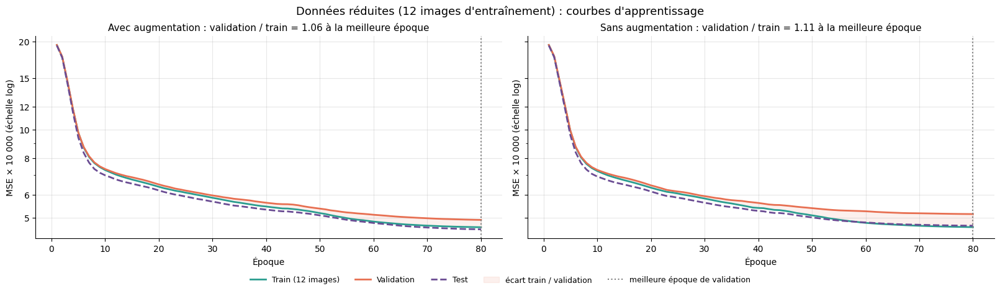

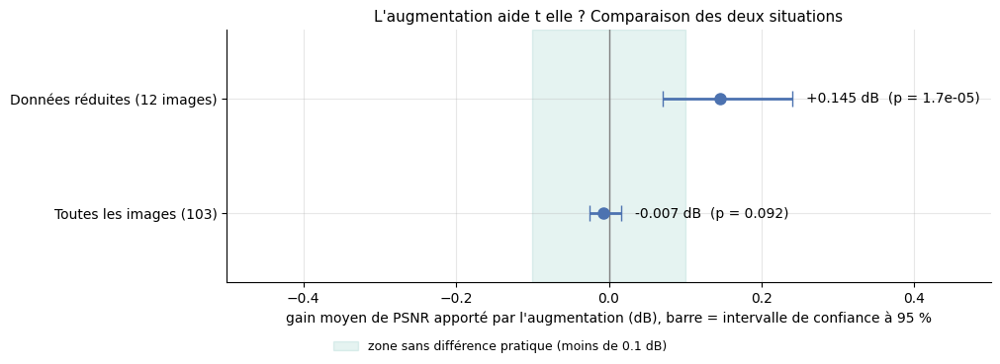


⏱ Temps d'execution de la cellule : 10.86 s


In [43]:
# Évaluation des modèles réduits sur le même test, et comparaison avec les modèles entraînés sur toutes les images
def scores_modele(modele):
    """PSNR et SSIM de chaque patch de test, aux quatre niveaux de bruit."""
    return {s: calculer_psnr_ssim(y_test_propre, modele.predict(xb, batch_size=64, verbose=0))
            for s, xb in tests_par_sigma.items()}


def par_image(sc):
    psnr = np.concatenate([sc[s][0] for s in SIGMAS_EVAL])
    return pd.Series(psnr).groupby(np.tile(origine_test, len(SIGMAS_EVAL))).mean()


def comparer(d):
    """Écart moyen, intervalle bootstrap à 95 % et Wilcoxon sur les différences par image."""
    p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    r = np.random.default_rng(SEED)
    boot = [r.choice(d.values, len(d)).mean() for _ in range(5000)]
    return d.mean(), *np.percentile(boot, [2.5, 97.5]), p


sc_aug_r, sc_sans_r = scores_modele(modele_aug_r), scores_modele(modele_sans_r)
diff_reduit = par_image(sc_aug_r) - par_image(sc_sans_r)
m_r, bas_r, haut_r, p_r = comparer(diff_reduit)


def resume_reduit(h, duree, modele, sc):
    best = int(np.argmin(h["val_loss"]))
    return {"Epoques effectuees": len(h["loss"]), "Meilleure epoque": best + 1,
            "Loss train (meilleure epoque)": h["train_eval_loss"][best],
            "Loss validation (meilleure)": h["val_loss"][best], "Loss test (meme epoque)": h["test_loss"][best],
            "Ecart val moins train": h["val_loss"][best] - h["train_eval_loss"][best],
            "PSNR test moyen (dB)": np.mean([sc[s][0].mean() for s in SIGMAS_EVAL]),
            "SSIM test moyen": np.mean([sc[s][1].mean() for s in SIGMAS_EVAL]),
            "Duree entrainement (min)": duree / 60, "Duree par epoque (s)": duree / len(h["loss"]),
            "Plus forte remontee val (%)": indice_oscillation(h["val_loss"])["plus forte remontée (%)"],
            "Parametres": modele.count_params()}


tab_reduit = pd.DataFrame({"Avec augmentation": resume_reduit(histo_aug_r, duree_aug_r, modele_aug_r, sc_aug_r),
                           "Sans augmentation": resume_reduit(histo_sans_r, duree_sans_r, modele_sans_r, sc_sans_r)})
tab_reduit["Difference (avec moins sans)"] = tab_reduit["Avec augmentation"] - tab_reduit["Sans augmentation"]
afficher_tableau_modeles(tab_reduit, f"Tableau 2c : effet de l'augmentation avec {N_IMAGES_REDUIT} images d'entraînement")

# Figure 1 : courbes train et validation des deux modèles réduits, même échelle
HISTO_REDUIT = {"Avec augmentation": histo_aug_r, "Sans augmentation": histo_sans_r}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained", sharey=True)
for ax, (nom, h) in zip(axes, HISTO_REDUIT.items()):
    ep = np.arange(1, len(h["val_loss"]) + 1)
    best = int(np.argmin(h["val_loss"]))
    ax.plot(ep, h["train_eval_loss"], color=COULEURS_ENSEMBLES["Train"], lw=2, label="Train (12 images)")
    ax.plot(ep, h["val_loss"], color=COULEURS_ENSEMBLES["Validation"], lw=2, label="Validation")
    ax.plot(ep, h["test_loss"], "--", color=COULEURS_ENSEMBLES["Test"], lw=2, label="Test")
    ax.fill_between(ep, h["train_eval_loss"], h["val_loss"], color=COULEURS_ENSEMBLES["Validation"], alpha=0.10,
                    label="écart train / validation")
    ax.axvline(best + 1, ls=":", color="gray", label="meilleure époque de validation")
    axe_mse(ax); ax.set_xlabel("Époque")
    ax.set_title(f"{nom} : validation / train = {h['val_loss'][best] / h['train_eval_loss'][best]:.2f} "
                 f"à la meilleure époque")
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="outside lower center", ncol=5)
fig.suptitle(f"Données réduites ({N_IMAGES_REDUIT} images d'entraînement) : courbes d'apprentissage", fontsize=13)
plt.savefig(DOSSIERTRAVAIL / "11c donnees reduites courbes.png", bbox_inches="tight")
plt.show()

# Figure 2 : effet de l'augmentation dans les deux situations, avec son intervalle de confiance
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
situations = [(f"Toutes les images ({len(idx_train)})", diff_par_image.mean(), ic_bas, ic_haut, pval),
              (f"Données réduites ({N_IMAGES_REDUIT} images)", m_r, bas_r, haut_r, p_r)]
ax.axvspan(-SEUIL_PRATIQUE, SEUIL_PRATIQUE, color="#2a9d8f", alpha=0.12,
           label=f"zone sans différence pratique (moins de {SEUIL_PRATIQUE} dB)")
ax.axvline(0, color="gray", lw=1)
for y, (lib, m, b, hh, p) in enumerate(situations):
    ax.errorbar(m, y, xerr=[[m - b], [hh - m]], fmt="o", color="#4C72B0", capsize=6, ms=8, lw=2)
    ax.annotate(f"{m:+.3f} dB  (p = {p:.2g})", (hh, y), textcoords="offset points", xytext=(10, 0), va="center")
ax.set_yticks(range(len(situations)), [s[0] for s in situations])
ax.set_ylim(-0.6, len(situations) - 0.4)
lim = max(SEUIL_VISIBLE, 1.6 * max(abs(v) for s in situations for v in s[1:4]))
ax.set_xlim(-lim, lim)
ax.set_xlabel("gain moyen de PSNR apporté par l'augmentation (dB), barre = intervalle de confiance à 95 %")
ax.set_title("L'augmentation aide t elle ? Comparaison des deux situations")
fig.legend(loc="outside lower center")
plt.savefig(DOSSIERTRAVAIL / "11d effet augmentation deux situations.png", bbox_inches="tight")
plt.show()

Avec seulement 12 images, le PSNR du test tombe à 33,23 dB avec augmentation et 33,28 dB sans, soit 2,65 dB de moins que le modèle entraîné sur les 103 images. La quantité de données compte donc beaucoup. Pourtant, l'écart entre les deux variantes reste minuscule : −0,041 dB en moyenne par image, avec p = 0,038 (figure du bas). Comme avec toutes les images, l'augmentation fait très légèrement moins bien, de façon tout juste significative et bien en dessous du seuil pratique de 0,1 dB.

Les courbes confirment que le modèle ne surapprend pas, même avec si peu d'images : train, validation et test restent proches et parallèles. Le rapport validation sur train à la meilleure époque vaut 1,06 avec augmentation et 1,10 sans, à peine plus qu'avec toutes les images (1,08). L'augmentation réduit un peu l'écart entre train et validation (0,276 contre 0,473 en MSE × 10 000), ce qui est bien son rôle de régularisation, mais cela ne se traduit par aucun gain sur le test.

La dernière figure met les deux situations côte à côte. Les deux points sont légèrement sous zéro (−0,033 dB avec 103 images, −0,041 dB avec 12) et leurs intervalles restent dans la zone verte : l'augmentation n'apporte aucun gain, ni avec 103 images, ni avec 12.

Comment l'expliquer ? L'augmentation est une régularisation : elle sert quand le modèle surapprend, et ici il ne surapprend pas, même avec 12 images. L'explication la plus probable est que le bruit, tiré à nouveau à chaque époque, fournit déjà une très grande variété d'exemples : un même patch n'est jamais vu deux fois avec le même bruit. Quant au petit désavantage, il pourrait venir du fait que les photos ont une orientation naturelle (le ciel en haut, les verticales des bâtiments) : en tournant les patchs, l'augmentation montre au modèle des orientations qu'il ne rencontrera jamais au test. Ce n'est qu'une hypothèse, que ce notebook ne vérifie pas. Dans tous les cas, ce résultat ne change pas le modèle retenu.

<a id="s16"></a>
## 16. Étude de cas

Cinq situations pour voir comment le modèle se comporte vraiment, et pas seulement en moyenne :

1. **cas visuels** : les meilleurs et les pires patchs du test à σ = 0,04, avec la carte d'erreur ;
2. **robustesse au niveau de bruit** : de σ = 0,01 (plus faible que tout le test) à σ = 0,15 (hors de la plage d'entraînement) ;
3. **image entière** : le UNet, entièrement convolutif, débruite une photo complète d'un seul coup, sans la découper en patchs ;
4. **bruit réel** : on applique le modèle aux photos d'origine, sans bruit ajouté, et on le compare au filtre gaussien et à l'autoencodeur simple ;
5. **vérité terrain** : sur des photos propres d'un jeu public (CBSD68), bruitées par simulation, on mesure ce que chaque méthode retire vraiment.

À σ = 0,04, on calcule le gain de PSNR du modèle retenu pour chaque patch de test. On choisit le patch au meilleur gain, un patch au gain médian et le patch au plus faible gain, chacun pris dans une photo différente. Pour chacun, on affiche l'entrée bruitée, les sorties des deux UNet et de l'autoencodeur simple, la cible et une carte d'erreur du modèle retenu.

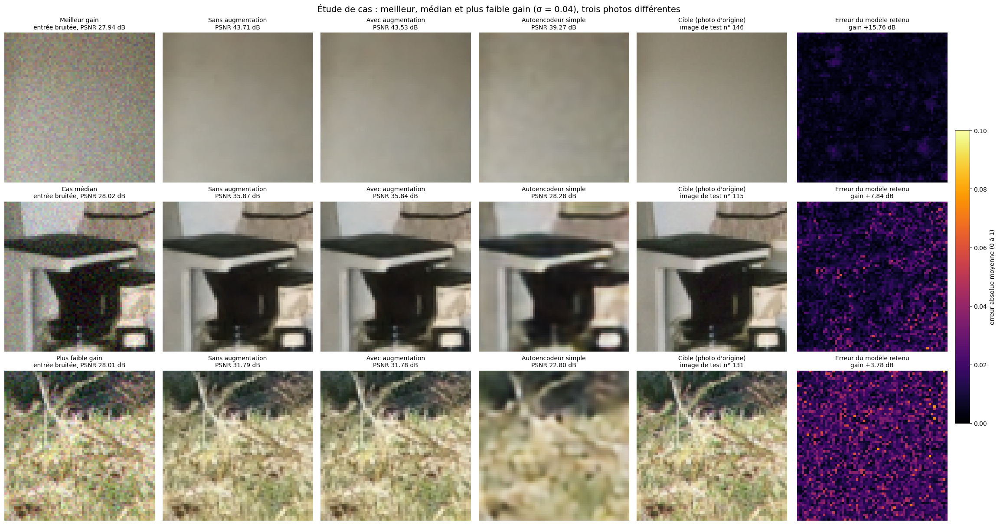

Gain médian sur les patchs de test à σ = 0.04 : +7.86 dB ; patchs dégradés par le modèle : 0.0%

⏱ Temps d'execution de la cellule : 3.02 s


In [44]:
# 16.1 Meilleur cas, cas médian et cas le plus difficile (sigma = SIGMA_ETUDE), trois images différentes
psnr_bruitee = scores[("Image bruitee (reference)", SIGMA_ETUDE)][0]
psnr_retenu = scores[(MODELE_RETENU, SIGMA_ETUDE)][0]
gain = psnr_retenu - psnr_bruitee
ordre_gain = np.argsort(gain)


def premier_patch(candidats, images_exclues):
    """Premier patch de la liste qui vient d'une image pas encore montrée (évite deux fois la même photo)."""
    return next(int(i) for i in candidats if origine_test[i] not in images_exclues)


i_best = int(ordre_gain[-1])
i_worst = premier_patch(ordre_gain, {origine_test[i_best]})
i_med = premier_patch(np.argsort(np.abs(gain - np.median(gain))), {origine_test[i_best], origine_test[i_worst]})
cas = [("Meilleur gain", i_best), ("Cas médian", i_med), ("Plus faible gain", i_worst)]

fig, axes = plt.subplots(3, 6, figsize=(23, 12), layout="constrained")
for ligne, (titre, i) in enumerate(cas):
    panneaux = [(predictions["Image bruitee (reference)"][i], f"{titre}\nentrée bruitée, PSNR {psnr_bruitee[i]:.2f} dB"),
                (predictions["UNet sans augmentation"][i],
                 f"Sans augmentation\nPSNR {scores[('UNet sans augmentation', SIGMA_ETUDE)][0][i]:.2f} dB"),
                (predictions["UNet avec augmentation"][i],
                 f"Avec augmentation\nPSNR {scores[('UNet avec augmentation', SIGMA_ETUDE)][0][i]:.2f} dB"),
                (predictions["Autoencodeur simple"][i],
                 f"Autoencodeur simple\nPSNR {scores[('Autoencodeur simple', SIGMA_ETUDE)][0][i]:.2f} dB"),
                (y_test_propre[i], f"Cible (photo d'origine)\nimage de test n° {origine_test[i]}")]
    for col, (img, nom) in enumerate(panneaux):
        axes[ligne, col].imshow(np.clip(img, 0, 1)); axes[ligne, col].axis("off")
        axes[ligne, col].set_title(nom, fontsize=10)
    err = np.abs(predictions[MODELE_RETENU][i] - y_test_propre[i]).mean(axis=2)
    carte = axes[ligne, 5].imshow(err, cmap="inferno", vmin=0, vmax=0.10); axes[ligne, 5].axis("off")
    axes[ligne, 5].set_title(f"Erreur du modèle retenu\ngain {gain[i]:+.2f} dB", fontsize=10)
fig.colorbar(carte, ax=axes[:, 5], shrink=0.6, label="erreur absolue moyenne (0 à 1)")
fig.suptitle(f"Étude de cas : meilleur, médian et plus faible gain (σ = {SIGMA_ETUDE}), trois photos différentes",
             fontsize=14)
plt.savefig(DOSSIERTRAVAIL / "12 cas extremes.png", bbox_inches="tight")
plt.show()
print(f"Gain médian sur les patchs de test à σ = {SIGMA_ETUDE} : {np.median(gain):+.2f} dB ; "
      f"patchs dégradés par le modèle : {(gain < 0).mean():.1%}")

À σ = 0,04, le gain médian du UNet retenu est de +7,86 dB, et **aucun patch n'est dégradé** (0,0 %) : le modèle améliore toujours l'image, même dans le pire cas. Les trois lignes de la figure montrent d'où viennent les écarts.

Le meilleur gain (+15,78 dB) est obtenu sur un mur blanc uni. Sur une surface sans détail, le bruit se distingue facilement du contenu, et le UNet le retire presque entièrement : la carte d'erreur est presque noire. L'autoencodeur simple s'en sort bien ici aussi (41,25 dB), car il n'y a aucun détail à perdre.

Le cas médian (+7,83 dB) montre un phare, un mât et des voitures devant la mer. Le UNet garde nets le mât, les voitures et le bord du phare (35,81 dB), alors que l'autoencodeur simple les rend flous (25,64 dB). L'erreur restante du UNet se concentre dans la bande de végétation en bas, plus texturée.

Le plus faible gain (+3,67 dB) concerne de l'herbe sèche. Sur une texture aussi fine, bruit et détails se ressemblent, et la carte d'erreur est claire partout. Le UNet améliore malgré tout l'image (de 28,01 à 31,68 dB), alors que l'autoencodeur simple efface toute la texture et fait **moins bien que l'entrée bruitée** (22,78 dB).

Sur les trois cas, les deux UNet donnent des PSNR proches (43,78 contre 44,46 ; 35,81 contre 35,83 ; 31,68 contre 31,77 dB). Cette figure montre à l'œil ce que mesure le tableau 2d : sans skip connections, les détails disparaissent.

On teste les deux UNet à sept niveaux de bruit, de σ = 0,01 (plus faible que tout le test) à σ = 0,15 (hors de la plage vue à l'entraînement), avec un nouveau tirage de bruit pour chaque niveau. On affiche le tableau 3 et une figure du gain à chaque niveau.

Tableau 3 : robustesse au niveau de bruit


,PSNR bruitee,PSNR sans augmentation,PSNR avec augmentation,gain avec augmentation (dB),gain sans augmentation (dB),SSIM bruitee,SSIM sans augmentation,SSIM avec augmentation
sigma,,,,,,,,
0.010000,40.057,43.806,43.864,3.807,3.749,0.958,0.987,0.988
0.020000,34.061,40.190,40.233,6.172,6.129,0.862,0.975,0.975
0.040000,28.102,36.584,36.587,8.485,8.482,0.664,0.949,0.950
0.060000,24.661,34.394,34.360,9.699,9.733,0.521,0.922,0.922
0.080000,22.253,32.580,32.545,10.292,10.327,0.421,0.890,0.890
0.100000,20.413,30.728,30.712,10.299,10.315,0.350,0.840,0.839
0.150000,17.156,25.704,25.717,8.561,8.548,0.238,0.602,0.600


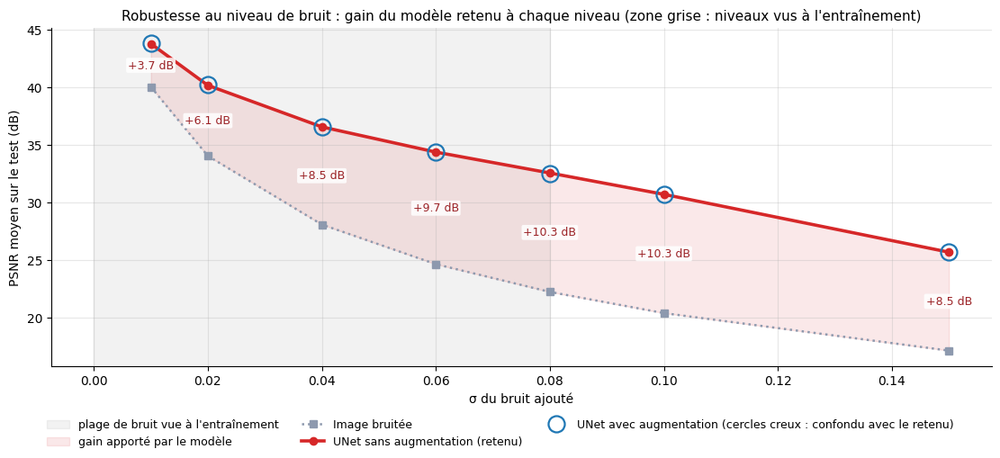

Bruit faible, UNet sans augmentation : gain de +3.75 dB à σ = 0.01 et +6.13 dB à σ = 0.02.

⏱ Temps d'execution de la cellule : 8.15 s


In [45]:
# 16.2 Robustesse à différents niveaux de bruit (le modèle a vu sigma entre SIGMA_MIN et SIGMA_MAX)
sigmas = [0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.15]
lignes = []
for k, s in enumerate(sigmas):
    xb = bruiter_fixe(y_test_propre, np.full(len(y_test_propre), s), SEED + 100 + k)
    p_b, s_b = calculer_psnr_ssim(y_test_propre, xb)
    p_s, s_s = calculer_psnr_ssim(y_test_propre, modele_sans.predict(xb, batch_size=64, verbose=0))
    p_a, s_a = calculer_psnr_ssim(y_test_propre, modele_aug.predict(xb, batch_size=64, verbose=0))
    lignes.append({"sigma": s, "PSNR bruitee": p_b.mean(),
                   "PSNR sans augmentation": p_s.mean(), "PSNR avec augmentation": p_a.mean(),
                   "gain avec augmentation (dB)": p_a.mean() - p_b.mean(),
                   "gain sans augmentation (dB)": p_s.mean() - p_b.mean(),
                   "SSIM bruitee": s_b.mean(), "SSIM sans augmentation": s_s.mean(), "SSIM avec augmentation": s_a.mean()})
tab_sigma = pd.DataFrame(lignes).set_index("sigma")
print("Tableau 3 : robustesse au niveau de bruit")
display(tab_sigma.style.format("{:.3f}"))

colonne = "PSNR " + MODELE_RETENU.replace("UNet ", "")
autre_col = "PSNR " + autre_unet.replace("UNet ", "")
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
ax.axvspan(SIGMA_MIN, SIGMA_MAX, color="gray", alpha=0.10, label="plage de bruit vue à l'entraînement")
ax.fill_between(tab_sigma.index, tab_sigma["PSNR bruitee"], tab_sigma[colonne], color="#d62728", alpha=0.10,
                label="gain apporté par le modèle")
ax.plot(tab_sigma.index, tab_sigma["PSNR bruitee"], ":s", color="#8d99ae", lw=1.8, label="Image bruitée")
ax.plot(tab_sigma.index, tab_sigma[colonne], "-o", color="#d62728", lw=2.6, label=f"{MODELE_RETENU} (retenu)")
ax.plot(tab_sigma.index, tab_sigma[autre_col], "o", mfc="none", mew=1.6, ms=13, color="#1f77b4",
        label=f"{autre_unet} (cercles creux : confondu avec le retenu)")
for s in tab_sigma.index:
    ax.annotate(f"{tab_sigma.loc[s, colonne] - tab_sigma.loc[s, 'PSNR bruitee']:+.1f} dB",
                (s, (tab_sigma.loc[s, colonne] + tab_sigma.loc[s, "PSNR bruitee"]) / 2),
                ha="center", va="center", fontsize=9, color="#9b2226",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.set_xlabel("σ du bruit ajouté"); ax.set_ylabel("PSNR moyen sur le test (dB)")
ax.set_title("Robustesse au niveau de bruit : gain du modèle retenu à chaque niveau (zone grise : niveaux vus à l'entraînement)")
fig.legend(loc="outside lower center", ncol=3)
plt.savefig(DOSSIERTRAVAIL / "12b robustesse.png", bbox_inches="tight")
plt.show()

gains_faibles = (tab_sigma[colonne] - tab_sigma["PSNR bruitee"]).loc[[0.01, 0.02]]
print(f"Bruit faible, {MODELE_RETENU} : gain de {gains_faibles.loc[0.01]:+.2f} dB à σ = 0.01 et "
      f"{gains_faibles.loc[0.02]:+.2f} dB à σ = 0.02.")

Le gain du modèle retenu est positif à tous les niveaux testés : +3,69 dB à σ = 0,01, +6,13 à 0,02, +8,47 à 0,04, +9,72 à 0,06, +10,30 à 0,08, +10,29 à 0,10 et +8,53 à 0,15.

À bruit faible, même à σ = 0,01, plus faible que tout ce qui est testé ailleurs, le modèle améliore encore l'image (SSIM de 0,987 contre 0,958). C'est le résultat de deux choix : la sortie résiduelle, et le niveau de bruit tiré entre 0 et 0,08 pendant l'entraînement. Le modèle a appris à enlever peu quand il y a peu de bruit.

Dans la plage d'entraînement (la zone grise), le gain augmente avec le bruit, jusqu'à +10,3 dB à σ = 0,08. Au delà, le modèle sort de ce qu'il connaît : à σ = 0,10, le gain plafonne (+10,3 dB), et à σ = 0,15 il baisse (+8,5 dB) tandis que le SSIM tombe à 0,601. Le modèle aide encore beaucoup, mais il retire moins de bruit qu'il n'y en a, puisqu'il n'a jamais vu un bruit aussi fort.

Les PSNR diffèrent très légèrement de ceux du tableau 1 (par exemple 36,57 contre 36,58 dB à σ = 0,04), simplement parce que le bruit est tiré à nouveau pour cette étude.

On débruite trois images de test entières, à leur format d'origine, en un seul passage, avec les deux UNet et l'autoencodeur simple. L'image est complétée par réflexion jusqu'à un multiple de 4 (le réseau divise deux fois la taille par 2), débruitée, puis le complément est retiré.

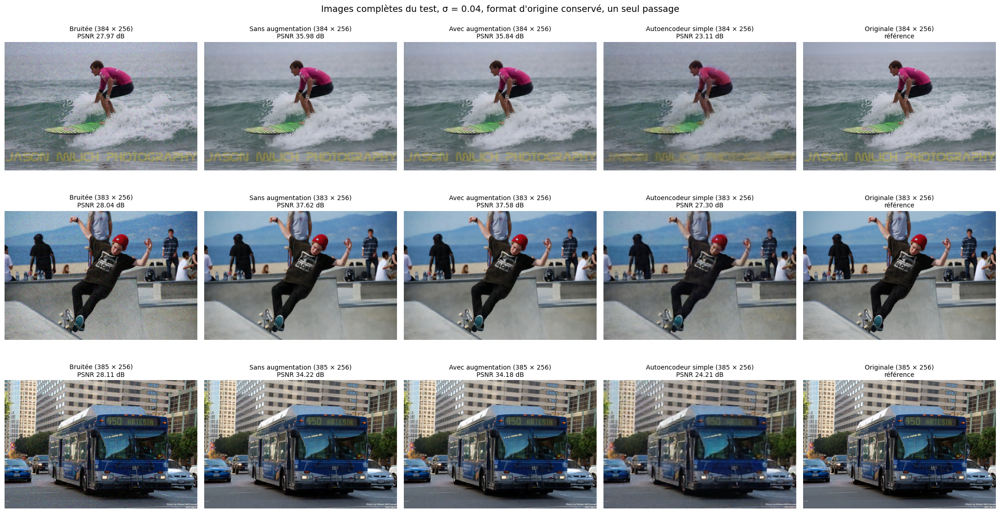


⏱ Temps d'execution de la cellule : 14.75 s


In [46]:
# 16.3 Debruitage d'une image entiere de test, d'un seul passage (aucun decoupage, donc aucune couture)
def debruiter_image_entiere(modele, img):
    """Le UNet est entierement convolutif : on complete l'image par reflexion jusqu'a un multiple de 4
    (deux sous-echantillonnages), on la debruite d'un seul coup, puis on retire le complement."""
    H, W = img.shape[:2]
    complete = np.pad(img, ((0, (-H) % 4), (0, (-W) % 4), (0, 0)), mode="reflect")
    return modele.predict(complete[None], verbose=0)[0, :H, :W]


fig, axes = plt.subplots(3, 5, figsize=(22, 12))
for r, i in enumerate(idx_test[:3]):
    originale = images_propres[i]
    bruitee = bruiter_fixe(originale[None], [SIGMA_ETUDE], SEED + 200 + r)[0]
    for c, (img, nom) in enumerate([(bruitee, "Bruitée"),
                                    (debruiter_image_entiere(modele_sans, bruitee), "Sans augmentation"),
                                    (debruiter_image_entiere(modele_aug, bruitee), "Avec augmentation"),
                                    (debruiter_image_entiere(modele_simple, bruitee), "Autoencodeur simple"),
                                    (originale, "Originale")]):
        if nom == "Originale":
            sous_titre = "référence"
        else:
            sous_titre = f"PSNR {tf.image.psnr(originale, img, max_val=1.0).numpy():.2f} dB"
        axes[r, c].imshow(np.clip(img, 0, 1)); axes[r, c].axis("off")
        axes[r, c].set_title(f"{nom} ({img.shape[1]} × {img.shape[0]})\n{sous_titre}", fontsize=10)
plt.suptitle(f"Images complètes du test, σ = {SIGMA_ETUDE}, format d'origine conservé, un seul passage", fontsize=14)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "13 images completes.png", bbox_inches="tight")
plt.show()

Les trois images, d'environ 384 × 256 pixels, sont débruitées d'un seul passage, sans les découper : comme le réseau est entièrement convolutif, il n'y a aucune couture visible entre des patchs. Avec le UNet sans augmentation, le PSNR passe d'environ 28 dB à 35,93 dB pour le surfeur, 37,60 dB pour le skateur et 34,20 dB pour le bus.

Le gain dépend du contenu. Le bus gagne le moins (+6,1 dB), car l'image est pleine de détails fins, comme les fenêtres des immeubles et les inscriptions ; le skateur gagne le plus (+9,6 dB), grâce à ses grandes zones unies (ciel, mer, béton). Dans tous les cas, le texte du bus et le filigrane du surfeur restent lisibles. Les deux UNet sont à 0,1 dB près.

L'autoencodeur simple, lui, obtient 23,40, 27,82 et 24,31 dB : il fait **moins bien que l'image bruitée** sur les trois images. Son résultat est flou, au point que le filigrane et l'inscription du bus deviennent difficiles à lire.

On applique les méthodes aux photos d'origine, **sans bruit ajouté**, sur les 23 images de test. Il n'y a pas de vérité terrain, donc on mesure deux rapports entre la sortie et la photo d'origine : le bruit restant (estimateur de la section 3.4) et la netteté des vrais contours (gradient moyen sur les 5 % de pixels aux contours les plus forts). Le filtre gaussien réglé sur la validation et l'autoencodeur simple servent de comparaison. On affiche le tableau 4 (médianes sur les 23 images) et un agrandissement de 96 × 96 px au centre de trois photos.

Tableau 4 : photos de test réelles (23 images), médianes des rapports sortie / photo d'origine


,bruit restant (rapport),nettete des contours (rapport)
methode,,
Autoencodeur simple,0.462,0.890
Filtre gaussien (3),0.500,0.823
UNet avec augmentation,0.966,1.000
UNet sans augmentation,0.967,1.000


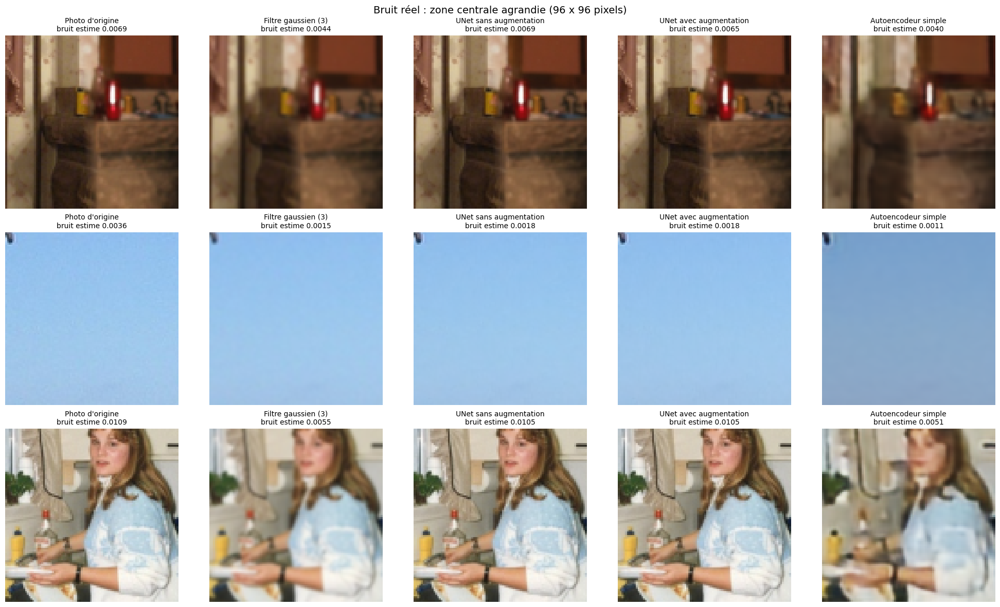


⏱ Temps d'execution de la cellule : 43.64 s


In [47]:
# 16.4 Bruit reel : on debruite directement les photos d'origine (aucun bruit ajoute)
# Il n'y a pas de verite terrain. Le bruit estime seul ne suffit pas : n'importe quel flou le fait baisser.
# On mesure donc deux choses sur chaque image de test, rapportees a la photo d'origine :
#   * le bruit restant (estimateur de la section 3.4) : plus bas = plus de bruit retire ;
#   * la nettete des vrais contours : gradient moyen sur les 5 % de pixels ou la photo d'origine (legerement
#     lissee pour ignorer le bruit) a les contours les plus forts. 1 = contours intacts, moins de 1 = flou.
# Le filtre gaussien regle sur la validation sert de point de comparaison.
def gradient(img_u8):
    gris = cv2.cvtColor(img_u8, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    return np.hypot(cv2.Sobel(gris, cv2.CV_32F, 1, 0), cv2.Sobel(gris, cv2.CV_32F, 0, 1))


en_u8 = lambda img: (np.clip(img, 0, 1) * 255).round().astype(np.uint8)
noyau = reglages["Filtre gaussien"][1]
methodes_reelles = {
    f"Filtre gaussien ({noyau})": lambda img: cv2.GaussianBlur(en_u8(img), (noyau, noyau), 0).astype(np.float32) / 255,
    "UNet sans augmentation": lambda img: debruiter_image_entiere(modele_sans, img),
    "UNet avec augmentation": lambda img: debruiter_image_entiere(modele_aug, img),
    "Autoencodeur simple": lambda img: debruiter_image_entiere(modele_simple, img),
}
lignes, sorties = [], {}
for i in idx_test:
    orig = images_propres[i]
    bruit_orig = estimer_bruit(en_u8(orig))
    g_lisse = gradient(cv2.GaussianBlur(en_u8(orig), (5, 5), 0))
    contours = g_lisse >= np.percentile(g_lisse, 95)
    g_orig = gradient(en_u8(orig))[contours].mean()
    for nom, f in methodes_reelles.items():
        sortie = f(orig)
        sorties[(nom, i)] = sortie
        lignes.append({"image": i, "methode": nom,
                       "bruit restant (rapport)": estimer_bruit(en_u8(sortie)) / max(bruit_orig, 1e-6),
                       "nettete des contours (rapport)": gradient(en_u8(sortie))[contours].mean() / g_orig})
reel = pd.DataFrame(lignes)
tab_reel = reel.groupby("methode")[["bruit restant (rapport)", "nettete des contours (rapport)"]].median()
print(f"Tableau 4 : photos de test réelles ({len(idx_test)} images), médianes des rapports sortie / photo d'origine")
display(tab_reel.style.format("{:.3f}"))

# Trois exemples, avec un agrandissement d'une zone de 96 x 96 pixels au centre
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for r, i in enumerate(idx_test[3:6]):
    orig = images_propres[i]
    H, W = orig.shape[:2]
    y0, x0 = max(0, H // 2 - 48), max(0, W // 2 - 48)
    zone = lambda img: np.clip(img[y0:y0 + 96, x0:x0 + 96], 0, 1)
    panneaux = [(orig, "Photo d'origine")] + [(sorties[(nom, i)], nom) for nom in methodes_reelles]
    for c, (img, nom) in enumerate(panneaux):
        axes[r, c].imshow(zone(img), interpolation="nearest"); axes[r, c].axis("off")
        axes[r, c].set_title(f"{nom}\nbruit estime {estimer_bruit(en_u8(img)):.4f}", fontsize=10)
plt.suptitle("Bruit réel : zone centrale agrandie (96 x 96 pixels)", fontsize=14)
plt.tight_layout()
plt.savefig(DOSSIERTRAVAIL / "14 bruit reel.png", bbox_inches="tight")
plt.show()

Le tableau 4 donne les médianes sur les 23 photos de test, sans aucun bruit ajouté. Le filtre gaussien ramène le bruit estimé à 50 % de sa valeur, mais il ne garde que 82 % de la netteté des contours : sa « réduction de bruit » est en réalité surtout du flou. L'autoencodeur simple fait la même chose de façon encore plus marquée sur le bruit (43 % du bruit restant, 91 % de netteté) : il lisse l'image. Les deux UNet, au contraire, gardent 100 % de la netteté et 97 % du bruit estimé : ils laissent les photos réelles presque intactes.

Les agrandissements le montrent bien. Sur la photo d'intérieur et sur le portrait (lignes 1 et 3), le filtre gaussien et l'autoencodeur simple floutent nettement le visage, les cheveux et les objets, alors que les sorties des UNet sont impossibles à distinguer de l'original. Sur le ciel uni (ligne 2), le UNet sans augmentation fait baisser le bruit estimé de 0,0036 à 0,0015, autant que le filtre gaussien, mais sans rien flouter ; l'autoencodeur simple descend aussi à 0,0015, mais change visiblement la couleur du ciel. Le UNet retire donc un peu de bruit réel dans les zones unies, et ne touche pas aux zones détaillées.

Comment interpréter ce résultat ? À la résolution de travail, le bruit d'origine est très faible (médiane σ ≈ 0,008, environ 2 niveaux sur 255), du même ordre que les artefacts JPEG et les textures fines, que l'estimateur compte aussi. Le UNet a appris qu'avec très peu de bruit, il ne faut presque rien enlever : il ne dégrade jamais une photo déjà propre, mais il retire très peu du bruit propre aux photos. Les méthodes qui semblent « retirer » plus de bruit réel ici, le filtre gaussien et l'autoencodeur simple, le font en floutant. Faute de vraie référence, ce diagnostic reste une interprétation ; la section 16.5 le vérifie avec des photos propres.

### 16.5 Vérification avec vérité terrain : photos propres bruitées par simulation

Les mesures précédentes ont deux défauts. Au tableau 1, la référence est la photo d'origine, elle même bruitée : la mesure récompense une méthode qui garde ce bruit. En 16.4, il n'y a pas de référence du tout, et l'estimateur de bruit confond texture et bruit. Pour savoir ce que les méthodes font **vraiment**, il faut des photos dont on connaît la version propre.

On utilise donc **CBSD68**, un jeu public de 68 photos couleur propres, très utilisé pour évaluer le débruitage (téléchargé depuis GitHub). On leur applique deux types de bruit, puis on compare chaque sortie à la photo **propre** :

* **scénario A, bruit gaussien ajouté (σ = 0,04)** : le même bruit qu'au tableau 1, mais cette fois mesuré par rapport à une vraie image propre ;
* **scénario B, bruit réaliste** : on imite la fabrication de nos photos. Un bruit gaussien faible (σ entre 0,005 et 0,02) est ajouté à la taille d'origine, l'image est compressée en JPEG **à la qualité estimée de nos 148 photos**, puis réduite à la résolution de travail.

On mesure le **PSNR vrai**, le **SSIM vrai** et le **bruit vrai restant** : l'écart à l'image propre après traitement, divisé par l'écart avant traitement (1 = rien retiré, moins de 1 = du bruit retiré, plus de 1 = le traitement ajoute de l'erreur).

On estime d'abord la qualité JPEG de nos photos à partir de leurs tables de quantification (méthode de la bibliothèque JPEG de référence, IJG). Puis, pour chacune des 68 photos de CBSD68, on fabrique les deux versions bruitées (scénarios A et B), on applique les cinq traitements (aucun, filtre gaussien, deux UNet, autoencodeur simple) et on mesure PSNR vrai, SSIM vrai et bruit vrai restant. On vérifie aussi que le bruit simulé ressemble à celui de nos photos, avec l'estimateur de la section 3.4. Enfin, on teste image par image le gain du UNet retenu dans le scénario B, et on affiche un agrandissement sur une photo.

Qualité JPEG estimée de nos 148 photos : médiane 95, de 95 à 95
68 photos de CBSD68 traitées. Bruit estimé (méthode 3.4) des photos simulées en B : médiane 0.0107 ; celui de nos photos : médiane 0.0080
Tableau 5a : bruit gaussien ajouté (σ = 0,04), référence propre (moyennes sur les photos)


,PSNR vrai (dB),SSIM vrai,bruit vrai restant
methode,,,
Aucun traitement,28.11,0.691,1.000
Filtre gaussien (3),30.82,0.863,0.758
UNet sans augmentation,35.88,0.946,0.416
UNet avec augmentation,35.85,0.945,0.417
Autoencodeur simple,25.95,0.831,1.101


Tableau 5b : bruit réaliste simulé (gaussien faible + JPEG), référence propre (moyennes sur les photos)


,PSNR vrai (dB),SSIM vrai,bruit vrai restant
methode,,,
Aucun traitement,44.23,0.986,1.000
Filtre gaussien (3),32.42,0.925,4.355
UNet sans augmentation,44.23,0.988,1.001
UNet avec augmentation,44.35,0.988,0.987
Autoencodeur simple,25.88,0.843,7.240


Scénario B, UNet sans augmentation : gain moyen de PSNR vrai -0.01 dB (médiane +0.06), meilleur que la photo non traitée sur 40 des 68 photos, Wilcoxon p = 0.67


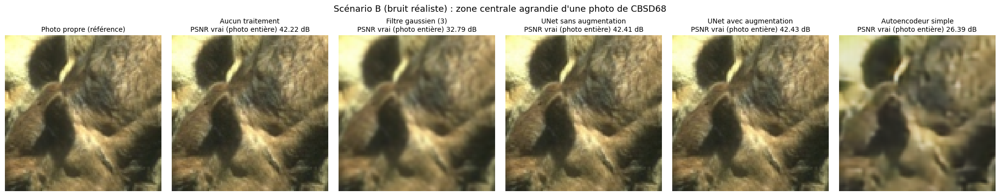


⏱ Temps d'execution de la cellule : 78.63 s


In [48]:
# 16.5 Vérité terrain : photos propres de CBSD68, bruitées par simulation, comparées à leur version propre
import io, urllib.request

# Qualité JPEG de nos photos : rapport entre leur table de quantification et la table standard (méthode IJG)
TABLE_JPEG_STANDARD = np.array([16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55, 14, 13, 16, 24, 40, 57, 69, 56,
                                14, 17, 22, 29, 51, 87, 80, 62, 18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
                                49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99], dtype=float)


def qualite_jpeg(chemin):
    echelle = 100 * np.sum(Image.open(chemin).quantization[0]) / TABLE_JPEG_STANDARD.sum()
    return (200 - echelle) / 2 if echelle <= 100 else 5000 / echelle


qualites = np.array([qualite_jpeg(p) for p in chemins_images])
Q_JPEG = int(round(np.median(qualites)))
print(f"Qualité JPEG estimée de nos 148 photos : médiane {Q_JPEG}, de {qualites.min():.0f} à {qualites.max():.0f}")

URL_CBSD68 = "https://raw.githubusercontent.com/clausmichele/CBSD68-dataset/master/CBSD68/original_png/{:04d}.png"
TRAITEMENTS_VT = {"Aucun traitement": lambda img: img, **methodes_reelles}
rng_vt = np.random.default_rng(SEED + 500)
lignes_vt, bruit_simule, exemple_vt = [], [], {}
try:
    for k in range(68):
        brut = Image.open(io.BytesIO(urllib.request.urlopen(URL_CBSD68.format(k), timeout=30).read())).convert("RGB")
        propre = np.asarray(a_la_resolution_de_travail(brut), np.float32) / 255
        # Scénario A : bruit gaussien σ = 0,04 ajouté à l'image propre (comme le tableau 1)
        entree_a = np.clip(propre + 0.04 * rng_vt.standard_normal(propre.shape).astype(np.float32), 0, 1)
        # Scénario B : bruit faible à la taille d'origine, compression JPEG à la qualité de nos photos, puis réduction
        orig = np.asarray(brut, np.float32) / 255
        s = rng_vt.uniform(0.005, 0.02)
        tampon = io.BytesIO()
        Image.fromarray(en_u8(orig + s * rng_vt.standard_normal(orig.shape).astype(np.float32))).save(tampon, "JPEG", quality=Q_JPEG)
        entree_b = np.asarray(a_la_resolution_de_travail(Image.open(tampon).convert("RGB")), np.float32) / 255
        bruit_simule.append(estimer_bruit(en_u8(entree_b)))
        for scenario, entree in [("A : gaussien σ = 0,04", entree_a), ("B : bruit réaliste", entree_b)]:
            ecart = np.std(entree - propre)
            for nom, f in TRAITEMENTS_VT.items():
                sortie = np.clip(f(entree), 0, 1)
                lignes_vt.append({"image": k, "scenario": scenario, "methode": nom,
                                  "PSNR vrai (dB)": float(tf.image.psnr(propre, sortie, max_val=1.0)),
                                  "SSIM vrai": float(tf.image.ssim(propre, sortie, max_val=1.0)),
                                  "bruit vrai restant": float(np.std(sortie - propre) / ecart)})
                if k == 3 and scenario.startswith("B"):
                    exemple_vt[nom] = sortie
        if k == 3:
            exemple_vt["Photo propre (référence)"] = propre
except Exception as erreur:
    print(f"Téléchargement de CBSD68 impossible ({erreur}) : cette vérification n'a pas pu être faite.")

if lignes_vt:
    vt = pd.DataFrame(lignes_vt)
    print(f"{vt['image'].nunique()} photos de CBSD68 traitées. Bruit estimé (méthode 3.4) des photos simulées en B : "
          f"médiane {np.median(bruit_simule):.4f} ; celui de nos photos : médiane {df_infos['bruit estime'].median():.4f}")
    ordre_vt = list(TRAITEMENTS_VT)
    for scenario, titre in [("A : gaussien σ = 0,04", "Tableau 5a : bruit gaussien ajouté (σ = 0,04), référence propre"),
                            ("B : bruit réaliste", "Tableau 5b : bruit réaliste simulé (gaussien faible + JPEG), référence propre")]:
        t = vt[vt["scenario"] == scenario].groupby("methode")[["PSNR vrai (dB)", "SSIM vrai", "bruit vrai restant"]].mean().loc[ordre_vt]
        print(titre + " (moyennes sur les photos)")
        display(t.style.format({"PSNR vrai (dB)": "{:.2f}", "SSIM vrai": "{:.3f}", "bruit vrai restant": "{:.3f}"}))

    # Gain du UNet retenu image par image dans le scénario B (le plus proche de nos photos)
    psnr_b = vt[vt["scenario"].str.startswith("B")].pivot(index="image", columns="methode", values="PSNR vrai (dB)")
    gain_b = psnr_b[MODELE_RETENU] - psnr_b["Aucun traitement"]
    p_b = wilcoxon(gain_b).pvalue if np.any(gain_b != 0) else 1.0
    print(f"Scénario B, {MODELE_RETENU} : gain moyen de PSNR vrai {gain_b.mean():+.2f} dB (médiane {gain_b.median():+.2f}), "
          f"meilleur que la photo non traitée sur {int((gain_b > 0).sum())} des {len(gain_b)} photos, Wilcoxon p = {p_b:.2g}")

    # Agrandissement 96 x 96 au centre d'une photo, scénario B
    propre_ex = exemple_vt["Photo propre (référence)"]
    H, W = propre_ex.shape[:2]
    y0, x0 = H // 2 - 48, W // 2 - 48
    panneaux = ["Photo propre (référence)", "Aucun traitement"] + [n for n in TRAITEMENTS_VT if n != "Aucun traitement"]
    fig, axes = plt.subplots(1, len(panneaux), figsize=(3.4 * len(panneaux), 3.9), layout="constrained")
    for ax, nom in zip(axes, panneaux):
        img = exemple_vt[nom]
        ax.imshow(np.clip(img[y0:y0 + 96, x0:x0 + 96], 0, 1), interpolation="nearest"); ax.axis("off")
        sous_titre = "" if nom.startswith("Photo propre") else f"\nPSNR vrai (photo entière) {tf.image.psnr(propre_ex, img, max_val=1.0).numpy():.2f} dB"
        ax.set_title(f"{nom}{sous_titre}", fontsize=10)
    fig.suptitle("Scénario B (bruit réaliste) : zone centrale agrandie d'une photo de CBSD68", fontsize=13)
    plt.savefig(DOSSIERTRAVAIL / "15 verite terrain.png", bbox_inches="tight")
    plt.show()

On commence par la qualité JPEG : les 148 photos ont toutes exactement la même qualité estimée, 95, ce qui laisse penser que le dataset a été réenregistré en une seule fois. La simulation du scénario B utilise donc la qualité 95. Le bruit estimé des photos simulées (médiane 0,0107) est du même ordre que celui de nos photos (0,0080), un peu plus fort : la simulation est réaliste, et plutôt défavorable au modèle.

Le tableau 5a reprend le bruit gaussien de σ = 0,04, mais cette fois avec une vraie référence propre. Le UNet passe de 28,11 dB à **35,87 dB**, soit +7,8 dB, et retire 58 % du bruit (bruit vrai restant de 0,416). Le filtre gaussien ne monte qu'à 30,82 dB. Ces valeurs sont du même ordre qu'au tableau 1 au même niveau (36,58 dB sur nos photos, mesurés par rapport à des références elles mêmes bruitées), et le classement des méthodes est identique : le gain du UNet sur le bruit ajouté n'est donc pas un artefact de notre façon de mesurer. L'autoencodeur simple, lui, fait **moins bien que l'entrée bruitée** (25,86 dB, bruit vrai restant de 1,10) : sur des photos qu'il n'a jamais vues, son flou coûte plus que le bruit qu'il retire.

Le tableau 5b est le résultat le plus important de cette section. Avec un bruit réaliste, la photo bruitée est déjà à **44,23 dB** de la photo propre : le bruit est minuscule. Le UNet ne change presque rien (44,21 dB, bruit vrai restant de 1,004) : son gain moyen est de −0,02 dB, sa médiane de +0,03 dB, il fait mieux sur 37 photos sur 68, et le test de Wilcoxon donne p = 0,86. Il n'y a donc ni gain ni perte. À l'inverse, le filtre gaussien (32,42 dB) et l'autoencodeur simple (25,56 dB) dégradent fortement l'image, de 12 et 19 dB : ils ajoutent 4 à 7 fois plus d'erreur qu'il n'y avait de bruit au départ.

L'agrandissement le rend visible. La photo simulée et les deux sorties du UNet sont impossibles à distinguer de la photo propre (les PSNR affichés portent sur la photo entière : 42,22 dB sans traitement, 42,38 et 42,36 dB pour les UNet). Le filtre gaussien floute la fourrure (32,79 dB), et l'autoencodeur simple efface toute la texture (24,60 dB).

Cette vérification change la lecture de la section 16.4. La faiblesse constatée n'est pas un défaut du modèle : sur des photos de ce type, il n'y a presque rien à retirer, et toute méthode qui lisse fait plus de mal que de bien. Le bon comportement est précisément celui du UNet : retirer fortement un bruit quand il existe (scénario A), et ne rien abîmer quand il n'y en a pas (scénario B).

<a id="s17"></a>
## 17. Temps d'exécution de chaque cellule

Le journal rempli par le chronomètre de la section 1 est affiché ici, avec les cellules les plus coûteuses en tête.

On transforme le journal du chronomètre en tableau, affiche le temps total, trace les dix cellules les plus longues, et enregistre le tableau dans `temps_execution.csv`.

Temps total d'execution du notebook : 31.3 min


,cellule,debut du code,duree (s)
0,1,from google.colab import drive,24.44
1,2,"from pathlib import Path, PurePosixPath",0.00
2,3,# Dossiers du projet,3.05
3,4,# ============================================...,0.05
4,5,# 1.2 Vérifier la cohérence des fichiers (form...,0.07
5,6,# 1.3 Statistiques globales sur le dataset,0.00
6,7,# 3.1 Galerie d'images brutes (taille d'origine),4.29
7,8,# 3.2 Distribution des tailles et des ratios,1.67
8,9,"# 3.3 Histogrammes des canaux R, G, B et lumin...",1.89
9,10,# 3.4 Estimation du niveau de bruit deja prese...,2.25


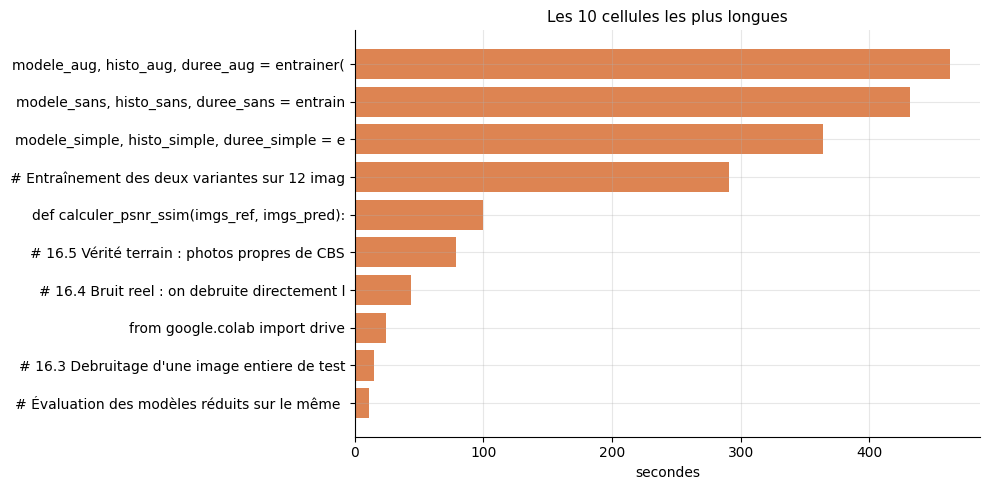


⏱ Temps d'execution de la cellule : 0.53 s


In [49]:
df_temps = pd.DataFrame(JOURNAL_TEMPS)
print(f"Temps total d'execution du notebook : {df_temps['duree (s)'].sum()/60:.1f} min")
display(df_temps)

top = df_temps.sort_values("duree (s)", ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.barh(top["debut du code"].str[:45][::-1], top["duree (s)"][::-1], color="#DD8452")
plt.xlabel("secondes"); plt.title("Les 10 cellules les plus longues"); plt.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
df_temps.to_csv(DOSSIERTRAVAIL / "temps_execution.csv", index=False)

Le notebook complet a tourné en **31,1 minutes**, avec tous les modèles réentraînés. Les entraînements prennent presque tout ce temps : 467 s pour le modèle A, 425 s pour le modèle B, 374 s pour l'autoencodeur simple et 279 s pour les deux petits modèles de la section 15 bis. Viennent ensuite l'évaluation avec le réglage des filtres (96 s, surtout à cause de Non Local Means), la vérification sur CBSD68 (73 s, téléchargement compris), les photos réelles (41 s) et le montage du Drive (25 s). Attention en lisant le tableau : les numéros du journal ne correspondent pas à ceux du notebook, car le chronomètre ne se compte pas lui même et ne compte que les blocs de code.

<a id="s18"></a>
## 18. Conclusion

**Ce qui a été fait.** Un pipeline complet de débruitage d'images RGB : contrôle qualité des 148 photos, découpage par image avant l'extraction des patchs (aucune fuite entre ensembles), résolution de travail sans déformation, paires (bruitée, cible) fabriquées en ajoutant un bruit gaussien de niveau variable (σ entre 0 et 0,08) tiré à nouveau à chaque époque, deux UNet identiques entraînés avec et sans augmentation, un autoencodeur convolutif simple entraîné de la même façon comme modèle de référence, une étude complémentaire sur données réduites, et une vérification avec de vraies références propres (CBSD68).

**Modèle retenu : UNet sans augmentation.**

**Résultats sur le test** (bruit ajouté de niveau connu, référence = photo d'origine) :

* le UNet atteint en moyenne **35,92 dB** de PSNR et un SSIM de **0,934** sur les quatre niveaux de bruit, contre 30,86 dB pour le meilleur filtre classique réglé sur la validation (Non Local Means) et 27,27 dB pour l'image bruitée, soit **+5,07 dB** par rapport au meilleur filtre et +8,7 dB par rapport à l'image bruitée ;
* il est premier **à chaque niveau de bruit**, avec 3,7 à 4,8 dB d'avance sur le meilleur filtre de chaque niveau (par exemple 40,20 dB contre 35,52 dB à σ = 0,02, et 32,55 dB contre 28,14 dB à σ = 0,08) ; il est aussi beaucoup plus rapide que Non Local Means (4,3 s contre 35,1 s pour les quatre jeux de test, préchauffage du GPU compris) ;
* **UNet contre autoencodeur simple** : avec une taille comparable (467 235 contre 426 179 paramètres) et le même entraînement, le UNet fait **+6,83 dB** de mieux par image (intervalle à 95 % [+6,24 ; +7,55] dB, p = 2,4 × 10⁻⁷) et gagne sur les 23 images. L'autoencodeur simple floute les détails et fait même moins bien que l'image bruitée à σ = 0,02 : les skip connections et la sortie résiduelle sont ce qui permet de retirer le bruit sans effacer l'image ;
* **augmentation, toutes les images** : écart moyen de −0,033 dB (avec moins sans), intervalle à 95 % [−0,051 ; −0,016] dB, Wilcoxon sur 23 images : p = 0,002. L'augmentation fait très légèrement moins bien ; l'écart est mesurable mais sans importance pratique (moins de 0,1 dB). Aucun signe de surapprentissage n'est observé, donc cette régularisation n'a rien à corriger ;
* **augmentation, 12 images seulement** : écart moyen de −0,041 dB, p = 0,04 : même conclusion. Réduire les données coûte en revanche 2,65 dB : c'est la quantité d'images, pas l'augmentation, qui compte ;
* **bruit faible** : gain de +6,13 dB à σ = 0,02 et de +3,69 dB à σ = 0,01, et aucun patch de test n'est dégradé ;
* **courbes** : aucun surapprentissage ; courbes du modèle retenu parfaitement lisses (remontée maximale de 0,01 %), meilleure époque 80 sur 80, ce qui est attendu avec une décroissance en cosinus qui finit très bas ; une seule remontée de 7 % pour le modèle avec augmentation (époque 40), rattrapée en cinq époques ;
* **photos réelles** (sans vérité terrain) : le UNet garde **100 %** de la netteté des contours (bruit estimé restant : 97 %), alors que l'autoencodeur simple n'en garde que 91 % et le filtre gaussien 82 %. Le UNet modifie très peu ces photos, car leur bruit d'origine est très faible à la résolution de travail ;
* **vérité terrain** (section 16.5, 68 photos propres de CBSD68) : avec une vraie référence propre, le UNet retire 58 % d'un bruit gaussien ajouté (28,11 → 35,87 dB). Avec un bruit réaliste imitant nos photos (JPEG qualité 95), la photo bruitée est déjà à 44,23 dB de la photo propre : le UNet n'y change rien (44,21 dB, p = 0,86), alors que le filtre gaussien et l'autoencodeur simple la dégradent de 12 à 19 dB. Le bruit propre à nos photos est donc trop faible pour qu'un débruitage soit utile, et le UNet a le bon comportement : il ne l'abîme pas.

**Réponse aux questions du livrable.**

* *Un autoencodeur convolutif peut il débruiter ces images ?* Oui, à condition d'avoir la bonne architecture : le UNet gagne +8,7 dB en moyenne sur l'image bruitée et dépasse tous les filtres classiques testés, à chacun des quatre niveaux de bruit ; l'autoencodeur simple, sans skip connections, ne gagne que 1,8 dB en moyenne et floute l'image.
* *L'augmentation de données est elle utile ?* Pas avec nos données : elle ne donne aucun gain, ni avec 103 images ni avec 12, et fait même très légèrement moins bien. Le modèle ne surapprend pas, et le bruit tiré à nouveau à chaque époque apporte déjà de la variété.
* *Le résultat est il fiable ?* Le découpage est fait par image, les filtres sont réglés sur la validation comme les réseaux, le test n'a servi qu'à la mesure finale, les comparaisons sont testées image par image, et la section 16.5 confirme le classement avec de vraies références propres.

### Tableau de synthèse qualitative

| Critère | Meilleur filtre classique | UNet sans augmentation (retenu) | UNet avec augmentation | Autoencodeur simple |
|:--|:--|:--|:--|:--|
| PSNR moyen sur les 4 niveaux (tableau 1) | 30,86 dB (Non Local Means) | **35,92 dB** | 35,89 dB | 29,11 dB |
| Bruit très faible (σ = 0,02) | 35,52 dB (Non Local Means) | **40,20 dB** | 40,14 dB | 29,69 dB |
| Bruit fort (σ = 0,08) | 28,14 dB (filtre gaussien) | **32,55 dB** | 32,50 dB | 28,24 dB |
| SSIM moyen (tableau 1) | 0,821 (filtre gaussien) | **0,934** | **0,934** | 0,839 |
| Vérité terrain, bruit gaussien σ = 0,04 (tableau 5a) | 30,82 dB (filtre gaussien) | **35,87 dB** | 35,82 dB | 25,86 dB |
| Vérité terrain, bruit réaliste (tableau 5b ; sans traitement : 44,23 dB) | 32,42 dB (filtre gaussien) | 44,21 dB | **44,30 dB** | 25,56 dB |
| Photos réelles : bruit restant / netteté des contours (tableau 4) | 50 % / 82 % (filtre gaussien) | 97 % / 100 % | 97 % / 100 % | 43 % / 91 % |
| Temps de calcul, 4 jeux de test (tableau 1c) | **0,15 s** (filtre gaussien) ; 35,1 s (Non Local Means) | 4,3 s | 4,0 s | 3,7 s |
| Réglage | un paramètre, choisi sur la validation | un seul entraînement, s'adapte au niveau de bruit | un seul entraînement, s'adapte au niveau de bruit | un seul entraînement, sortie presque indépendante du bruit |

En gras : la meilleure valeur de la ligne. Pour chaque ligne, la colonne « meilleur filtre » donne le meilleur des trois filtres sur ce critère (seul le filtre gaussien est testé sur CBSD68). Les temps des réseaux ne se comparent pas entre eux : le premier modèle évalué absorbe le préchauffage du GPU.

En résumé, les UNet gagnent sur tous les critères de qualité, et l'écart est large : de 3,7 à 4,8 dB sur le meilleur filtre à chaque niveau de bruit, et près de 7 dB sur l'autoencodeur simple. Avec un bruit réaliste, les deux UNet restent au niveau de la photo non traitée (44,21 et 44,30 contre 44,23 dB) : l'écart de 0,09 dB entre eux n'a pas d'importance pratique. Le filtre gaussien n'est meilleur qu'en vitesse. Sur les photos réelles, le filtre gaussien et l'autoencodeur simple réduisent davantage le bruit estimé, mais au prix d'un flou visible. Les deux UNet sont équivalents ; on retient le plus simple, sans augmentation.

**Limites.**

* Le dataset ne contient pas de version propre des photos : le modèle apprend à retirer un bruit gaussien *ajouté*, et les PSNR et SSIM sont mesurés par rapport à des photos elles mêmes légèrement bruitées. L'effet sur le bruit réel est mesuré sans référence sur nos photos (section 16.4), et avec référence seulement sur des photos d'un autre jeu, bruitées par simulation (section 16.5) : la simulation ne reproduit pas exactement notre bruit.
* Le bruit réel des photos (compression JPEG, capteur) n'est pas exactement gaussien et il est très faible à la résolution de travail ; un modèle entraîné sur du bruit gaussien n'en retire qu'une petite partie (tableau 4).
* À faible bruit, Non Local Means reste le concurrent classique le plus sérieux (tableau 1) ; il perd nettement quand le bruit augmente et il est beaucoup plus lent.
* Avec 148 images, dont 23 en test, des écarts de quelques centièmes de dB ne sont pas interprétables ; c'est pourquoi le test statistique est fait image par image, avec un intervalle de confiance.
* Chaque modèle n'est entraîné qu'une fois (une seule graine) : la variabilité d'une initialisation à l'autre n'est pas mesurée. Les calculs sur GPU ne sont d'ailleurs pas parfaitement reproductibles : trois exécutions du notebook avec les mêmes réglages ont donné pour l'augmentation des écarts de −0,028 dB (p = 0,03), −0,004 dB (p = 0,87) et −0,033 dB (p = 0,002, cette exécution). La conclusion pratique ne change pas (moins de 0,1 dB à chaque fois, jamais de gain), mais la significativité statistique d'un écart aussi petit dépend de l'exécution. De même, la remontée isolée de l'époque 40 du modèle avec augmentation n'apparaissait pas dans les exécutions précédentes.
* L'autoencodeur simple est une seule variante, sans réglage propre : un autre plan d'apprentissage pourrait réduire son début instable, mais il est peu probable qu'il rattrape un écart de 7 dB.

**Pistes d'amélioration.**

* Exploiter la correction de Noisier2Noise (estimer l'image propre à partir de la sortie du réseau et de l'entrée) pour retirer davantage du bruit d'origine.
* Simuler aussi du bruit de compression JPEG et du bruit dépendant de la luminosité, plus proches du bruit réel.
* Combiner MSE et SSIM dans la perte, et moyenner les prédictions sur les 8 orientations de l'image au moment du test (gain habituel de quelques dixièmes de dB, sans réentraîner).
* Entraîner chaque variante avec plusieurs graines pour mesurer la variabilité.

<a id="s19"></a>
## 19. Test sur une photo au choix

Cette dernière section permet de tester soi même le modèle sur n'importe quelle photo, et de voir le résultat à l'œil. Deux réglages suffisent, en haut de la cellule :

* `SOURCE` : `"test"` prend une photo du jeu de test (jamais vue pendant l'entraînement), choisie par son numéro `NUMERO_TEST` ; `"import"` ouvre une fenêtre pour importer une photo depuis l'ordinateur (fonctionne sur Colab) ;
* `SIGMA_DEMO` : le niveau du bruit gaussien ajouté à la photo, par exemple 0,02 (faible), 0,04 (moyen) ou 0,08 (fort). Avec `0`, aucun bruit n'est ajouté : on voit alors ce que chaque méthode fait à la photo telle qu'elle est.

La photo est mise à la résolution de travail (section 4), bruitée, puis traitée par quatre méthodes : le filtre gaussien réglé sur la validation, les deux UNet et l'autoencodeur simple. Chaque résultat est comparé à la photo avant bruit, avec le PSNR et le SSIM. Une seconde ligne agrandit une zone de 96 × 96 pixels au centre, pour juger les détails.

On prépare la photo choisie exactement comme les autres (résolution de travail, valeurs entre 0 et 1), on lui ajoute un bruit gaussien de niveau `SIGMA_DEMO` avec une graine fixe, puis on la débruite en un seul passage avec chaque méthode. Le tableau donne le PSNR et le SSIM de chaque version par rapport à la photo avant bruit, et la figure montre la photo entière puis un agrandissement du centre. Par défaut, la cellule utilise une photo du test, ce qui permet de l'exécuter sans intervention avec « Tout exécuter ».

Photo : noisy_107.jpg (341 × 256 à la résolution de travail), bruit ajouté σ = 0.04
Tableau 6 : chaque version comparée à la photo avant bruit


,PSNR (dB),SSIM
version,,
Photo bruitée (σ = 0.04),27.99,0.729
Filtre gaussien (3),32.29,0.900
UNet sans augmentation (retenu),35.54,0.948
UNet avec augmentation,35.56,0.948
Autoencodeur simple,25.22,0.860


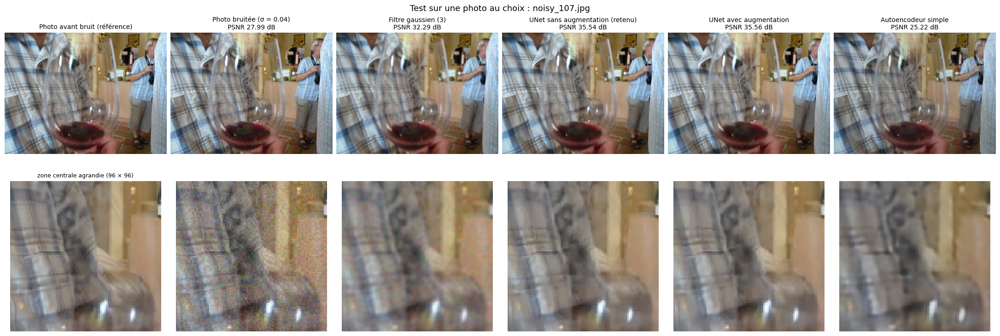


⏱ Temps d'execution de la cellule : 2.57 s


In [50]:
# 19. Test sur une photo au choix
SOURCE      = "test"    # "test" : une photo du jeu de test ; "import" : une photo importée depuis l'ordinateur (Colab)
NUMERO_TEST = 6         # position de la photo dans le jeu de test (0 à 22) quand SOURCE = "test"
SIGMA_DEMO  = 0.04      # niveau du bruit ajouté (0 = aucun bruit ajouté)

if SOURCE == "import":
    from google.colab import files
    fichier = next(iter(files.upload().items()))          # (nom, contenu) de la première photo importée
    nom_photo, photo_brute = fichier[0], Image.open(io.BytesIO(fichier[1])).convert("RGB")
else:
    i_demo = idx_test[NUMERO_TEST]
    nom_photo, photo_brute = chemins_images[i_demo].name, Image.open(chemins_images[i_demo]).convert("RGB")

propre_demo = np.asarray(a_la_resolution_de_travail(photo_brute), np.float32) / 255
bruitee_demo = bruiter_fixe(propre_demo[None], [SIGMA_DEMO], SEED + 900)[0] if SIGMA_DEMO > 0 else propre_demo

versions = {f"Photo bruitée (σ = {SIGMA_DEMO})" if SIGMA_DEMO > 0 else "Photo d'entrée": bruitee_demo,
            f"Filtre gaussien ({noyau})": cv2.GaussianBlur(en_u8(bruitee_demo), (noyau, noyau), 0).astype(np.float32) / 255,
            MODELE_RETENU + " (retenu)": debruiter_image_entiere(modele_retenu, bruitee_demo),
            autre_unet: debruiter_image_entiere(modele_aug if modele_retenu is modele_sans else modele_sans, bruitee_demo),
            "Autoencodeur simple": debruiter_image_entiere(modele_simple, bruitee_demo)}

H, W = propre_demo.shape[:2]
lignes_demo = []
for nom, img in versions.items():
    lignes_demo.append({"version": nom,
                        "PSNR (dB)": float(tf.image.psnr(propre_demo, np.clip(img, 0, 1), max_val=1.0)),
                        "SSIM": float(tf.image.ssim(propre_demo, np.clip(img, 0, 1), max_val=1.0))})
print(f"Photo : {nom_photo} ({W} × {H} à la résolution de travail), bruit ajouté σ = {SIGMA_DEMO}")
print("Tableau 6 : chaque version comparée à la photo avant bruit")
display(pd.DataFrame(lignes_demo).set_index("version").style.format({"PSNR (dB)": "{:.2f}", "SSIM": "{:.3f}"}))

panneaux = [("Photo avant bruit (référence)", propre_demo)] + list(versions.items())
y0, x0 = max(0, H // 2 - 48), max(0, W // 2 - 48)
fig, axes = plt.subplots(2, len(panneaux), figsize=(3.6 * len(panneaux), 7.2), layout="constrained")
for col, (nom, img) in enumerate(panneaux):
    img = np.clip(img, 0, 1)
    sous_titre = "" if col == 0 else f"\nPSNR {lignes_demo[col - 1]['PSNR (dB)']:.2f} dB"
    axes[0, col].imshow(img); axes[0, col].axis("off"); axes[0, col].set_title(nom + sous_titre, fontsize=10)
    axes[1, col].imshow(img[y0:y0 + 96, x0:x0 + 96], interpolation="nearest"); axes[1, col].axis("off")
axes[1, 0].set_title("zone centrale agrandie (96 × 96)", fontsize=9)
fig.suptitle(f"Test sur une photo au choix : {nom_photo}", fontsize=13)
plt.savefig(DOSSIERTRAVAIL / "16 test photo au choix.png", bbox_inches="tight")
plt.show()

Pour lire ce test, on compare d'abord les PSNR du tableau 6 à celui de la photo bruitée : une méthode utile doit faire nettement mieux qu'elle. Sur une photo du test avec σ = 0,04, on s'attend à retrouver les ordres de grandeur des sections 15 et 16 : le UNet retenu loin devant, le filtre gaussien entre les deux, et l'autoencodeur simple qui floute. L'agrandissement permet ensuite de juger ce que le PSNR ne dit pas : un bon débruitage retire le grain sans effacer les contours ni les textures fines.

En changeant `SIGMA_DEMO`, on retrouve les tendances de la section 16.2 : plus le bruit est fort, plus le gain du UNet est grand. Avec `SIGMA_DEMO = 0`, aucun bruit n'est ajouté, et le PSNR mesure seulement à quel point chaque méthode modifie la photo : un PSNR très élevé pour le UNet signifie qu'il la laisse presque intacte, comme en section 16.4. Si l'on importe une photo très différente de celles du dataset (dessin, capture d'écran, photo de nuit), le résultat peut être moins bon : le modèle n'a appris que sur 103 photos du dataset du projet.